# Angle–Exponent Compression of Non-Linear Manifolds

This notebook explores a simple geometric idea: the angle of a point $(x,y)$ against the $45^\circ$ line
encodes how strongly the curve $y(x)$ deviates from linearity. From it, a pipeline is built that rotates
$N$-dimensional data, keeps two coordinates $(x',y')$, replaces $y'$ by a fitted power law
$y' = a\,x'^{\,p+1}$ (later a power law plus a sine term) and reconstructs the data from the stored $x'$,
a few scalars and the remaining "depth" coordinates.

The notebook develops in five stages (the explanatory cells below follow them):

1. **Angle and exponent** – angles against the $45^\circ$ line, exponent recovery by curve fitting
2. **Cube projection** – 3D rotation, orthographic projection, first exponent estimate
3. **$x'$-driven transformer** – driver-axis selection, storing only $x'$, regenerating $y'$
4. **Higher dimensions** – 4D hypersphere and 20D sinusoidal manifold
5. **Fourier–power hybrid** – power law plus sine term, up to 600 dimensions

The last markdown cell is a critical assessment of the reported compression ratios and errors.

In [3]:
import numpy as np
import matplotlib.pyplot as plt

## 1. Angles and the $45^\circ$ line

For a point $(x,y)$ with $x>0$ the angle to the $x$-axis is

$$\theta = \operatorname{atan2}(y,x).$$

Points on $y=x$ have $\theta = 45^\circ$. The angle is computed twice below: with `atan2`, and as the angle between
$u=(x,0)$ and $v=(x,y)$ via the dot product,

$$\cos\theta = \frac{u\cdot v}{\|u\|\,\|v\|}.$$

Both agree for the points of $y=x^2$:

| Point $(x,y)$ | $(1,1)$ | $(2,4)$ | $(3,9)$ | $(4,16)$ |
|:--|--:|--:|--:|--:|
| $\theta$ | $45.00^\circ$ | $63.43^\circ$ | $71.57^\circ$ | $75.96^\circ$ |

In [42]:
def aproximate(x: int):
    vals = []
    for axi in range(0,len(x)):
        vals.append(np.degrees(math.atan2(x[axi][1], x[axi][0])))
    return vals

v = [[1, 1], [2, 4], [3, 9], [4, 16]]
atanTrig = aproximate(v)
print(atanTrig)

[np.float64(45.0), np.float64(63.43494882292201), np.float64(71.56505117707799), np.float64(75.96375653207353)]


In [49]:
def approximate(points: list):
    for i,point in enumerate(points):
        u = np.array([point[0], 0])
        v = np.array([point[0], point[1]])

        cos_theta = np.dot(u, v) / (np.linalg.norm(u) * np.linalg.norm(v))
        angle_deg = np.degrees(np.arccos(np.clip(cos_theta, -1.0, 1.0)))
        print(f"Point {point}, norm: {angle_deg:.2f}° | atan2: {atanTrig[i]:.2f}°")

v = [[1, 1], [2, 4], [3, 9], [4, 16]]
linearNorm = approximate(v)

Point [1, 1], norm: 45.00° | atan2: 45.00°
Point [2, 4], norm: 63.43° | atan2: 63.43°
Point [3, 9], norm: 71.57° | atan2: 71.57°
Point [4, 16], norm: 75.96° | atan2: 75.96°


45deg is the truth angle, we're going to calcualte error to.

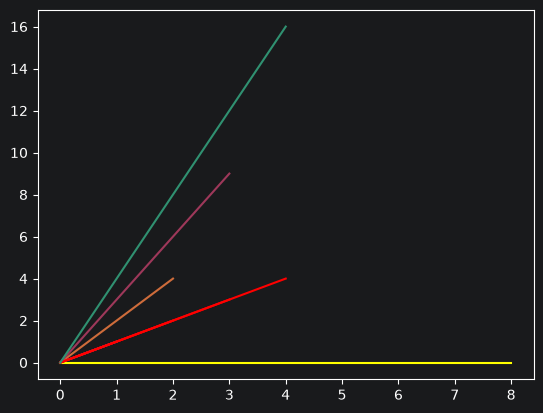

In [54]:
plt.plot([0,1,2,3,4,5,6,7,8], [0,0,0,0,0,0,0,0,0], color='yellow')
plt.plot([0,1], [0,1], color='red')
plt.plot([0,1], [0,1])

plt.plot([0,2], [0,2], color='red')
plt.plot([0,2], [0,4])

plt.plot([0,3], [0,3], color='red')
plt.plot([0,3], [0,9])


plt.plot([0,4], [0,4], color='red')
plt.plot([0,4], [0,16])


Finding the exponenet for representing data equation (np.optimize)

## 2. From angle to exponent

The *required multiplier* $m = x/y$ is the factor by which $y$ must be scaled to land on the $45^\circ$ line
($m\,y = x$). For the points of $y=x^2$ it is $1,\ \tfrac12,\ \tfrac13,\ \tfrac14$. The notebook parametrises it as

$$m(x) = \frac{1}{a\,x^{p}} \qquad\Longrightarrow\qquad y(x) = \frac{x}{m(x)} = a\,x^{p+1}.$$

The curvature of the data is therefore captured by one scalar, the exponent $p+1$.

**Log-linear estimator.** Taking logarithms gives $\ln m = -\ln a - p\ln x$. A least-squares line through
$(\ln x,\ \ln m)$ with slope $s$ and intercept $c$ yields

$$p = -s, \qquad a = e^{-c}.$$

This is the initial estimate used by every transformer class later on. The `curve_fit` call below recovers
$a = 1.00,\ p = 1.00$, i.e. $y(x) = 1.00\,x^{2.00}$.

In [52]:
v = np.array([[1, 1], [2, 4], [3, 9], [4, 16]])

x_data = v[:, 0]
y_data = v[:, 1]

m_required = x_data / y_data  # [1.0, 0.5, 0.3333, 0.25]

def multiplier_model(x, a, p):
    return 1 / (a * (x ** p))

popt, _ = curve_fit(multiplier_model, x_data, m_required)
a_fit, p_fit = popt

exponent_reconstructed = p_fit + 1

print(f"Fitted Multiplier Model : m(x) = 1 / ({a_fit:.2f} * x^{p_fit:.2f})")
print(f"Reconstructed Function  : y(x) = {a_fit:.2f} * x^{exponent_reconstructed:.2f}")

Fitted Multiplier Model : m(x) = 1 / (1.00 * x^1.00)
Reconstructed Function  : y(x) = 1.00 * x^2.00


## 3. From 3D to 2D: rotation and projection

The unit cube is rotated by $30^\circ$ about the $x$-axis and $45^\circ$ about the $y$-axis,

$$R = R_y(45^\circ)\,R_x(30^\circ),$$

and projected orthographically by dropping the third coordinate. To go back, the lost depth coordinate is supplied
(for the cube: $z\in\{0,1\}$) and the data are un-rotated with $R^{-1}$.

The exponent fit on the projected cube gives $y(x) = 1.07\,x^{-0.03}$, an exponent close to zero.
A cube is piecewise planar, so a single power law is a poor model for it – this reappears in the benchmarks below.

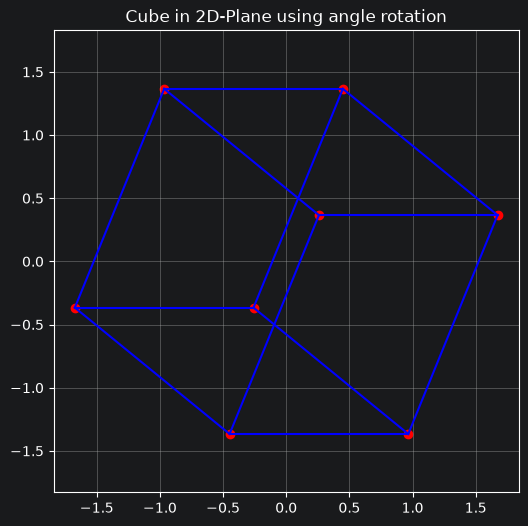

In [62]:
import numpy as np
import matplotlib.pyplot as plt


vertices_3d = np.array([
    [-1, -1, -1], [ 1, -1, -1], [ 1,  1, -1], [-1,  1, -1],
    [-1, -1,  1], [ 1, -1,  1], [ 1,  1,  1], [-1,  1,  1]
])

# get those radians for representing cube angles
angle_x = np.radians(30)
angle_y = np.radians(45)

# elementary rotation
Rx = np.array([
    [1, 0, 0],
    [0, np.cos(angle_x), -np.sin(angle_x)],
    [0, np.sin(angle_x),  np.cos(angle_x)]
])
Ry = np.array([
    [ np.cos(angle_y), 0, np.sin(angle_y)],
    [0, 1, 0],
    [-np.sin(angle_y), 0, np.cos(angle_y)]
])

# https://sites.math.duke.edu/education/ccp/materials/linalg/rotation/rotm3.html
R = Ry @ Rx # apply matrix multiplication results rotation matrix
rotated_3d = vertices_3d @ R.T # abstracts the cube graphics

# Orthographic Projection to 2D (Drop Z coordinate)
projection_2d = np.array([
    [1, 0, 0],
    [0, 1, 0]
])

points_2d = rotated_3d @ projection_2d.T  # Output is (8, 2) array of [X_2d, Y_2d]

# 2D projection (abstracted cube)
edges = [
    (0, 1), (1, 2), (2, 3), (3, 0),  # Bottom face
    (4, 5), (5, 6), (6, 7), (7, 4),  # Top face
    (0, 4), (1, 5), (2, 6), (3, 7)   # Vertical edges
]

plt.figure(figsize=(6, 6))
for p1, p2 in edges:
    plt.plot([points_2d[p1, 0], points_2d[p2, 0]],
             [points_2d[p1, 1], points_2d[p2, 1]], 'b-')

plt.scatter(points_2d[:, 0], points_2d[:, 1], color='red')
plt.title("Cube in 2D-Plane using angle rotation")
plt.axis('equal')
plt.grid(True)
plt.show()

In [63]:
vertices_3d = np.array([
    [0, 0, 0], [1, 0, 0], [1, 1, 0], [0, 1, 0],
    [0, 0, 1], [1, 0, 1], [1, 1, 1], [0, 1, 1]
], dtype=float)

theta_x, theta_y = np.radians(30), np.radians(45)

Rx = np.array([[1, 0, 0], [0, np.cos(theta_x), -np.sin(theta_x)], [0, np.sin(theta_x), np.cos(theta_x)]])
Ry = np.array([[np.cos(theta_y), 0, np.sin(theta_y)], [0, 1, 0], [-np.sin(theta_y), 0, np.cos(theta_y)]])

rotated_3d = vertices_3d @ (Ry @ Rx).T
points_2d = rotated_3d[:, :2]

points_2d -= points_2d.min(axis=0) - 0.5

sorted_indices = np.argsort(points_2d[:, 0])
ordered_2d = points_2d[sorted_indices]
x_data = ordered_2d[:, 0]
y_data = ordered_2d[:, 1]
m_required = x_data / y_data

log_x = np.log(x_data) # log-linear Fit (create the aprox model)
log_m = np.log(m_required)

# linear polynomial fit (degree 1): log_m = slope * log_x + intercept
# data follows a power law
poly = np.polyfit(log_x, log_m, 1)

p_fit = -poly[0]
a_fit = np.exp(-poly[1])
exponent_reconstructed = p_fit + 1

print("--- 3D -> 2D Cube Exponent Reconstruction (Log Fit) ---")
print(f"Fitted Multiplier Model : m(x) = 1 / ({a_fit:.2f} * x^{p_fit:.2f})")
print(f"Reconstructed Exponent  : {exponent_reconstructed:.2f}")
print(f"Reconstructed Function  : Y(X) = {a_fit:.2f} * X^{exponent_reconstructed:.2f}")

--- 3D -> 2D Cube Exponent Reconstruction (Log Fit) ---
Fitted Multiplier Model : m(x) = 1 / (1.07 * x^-1.03)
Reconstructed Exponent  : -0.03
Reconstructed Function  : Y(X) = 1.07 * X^-0.03


In [65]:
def reconstruct_cube_from_2d(points_2d, theta_x, theta_y):
    Rx = np.array([
        [1, 0, 0],
        [0, np.cos(theta_x), -np.sin(theta_x)],
        [0, np.sin(theta_x),  np.cos(theta_x)]
    ])

    Ry = np.array([
        [ np.cos(theta_y), 0, np.sin(theta_y)],
        [0, 1, 0],
        [-np.sin(theta_y), 0, np.cos(theta_y)]
    ])

    R = Ry @ Rx
    R_inv = np.linalg.inv(R)  # Inverse rotation matrix
    reconstructed_3d = []

    # Unit cube depth assignments based on sorted order
    # Corners are at z = 0 or z = 1 before rotation
    z_knowns = [0, 0, 0, 0, 1, 1, 1, 1]

    for i, (x_2d, y_2d) in enumerate(points_2d):
        # We solve: [x_2d, y_2d, z_rot]^T = R @ [x_3d, y_3d, z_3d]^T
        z_guess = z_knowns[i]

        # Un-rotate the projected 2D coordinates + reconstructed Z
        pt_rotated = np.array([x_2d, y_2d, z_guess])
        pt_3d = R_inv @ pt_rotated
        reconstructed_3d.append(pt_3d)

    return np.array(reconstructed_3d)

## 4. The $x'$-driven transformer

Let $X\in\mathbb{R}^{n\times N}$ hold $n$ points. The pipeline in the classes below is:

1. **Rotate.** $Z = X R^\top$ with an orthogonal $R$ (fixed angles in 3D; the $Q$ factor of a seeded QR
   decomposition of a Gaussian matrix in higher dimensions).
2. **Split.** $Z = [\,c_0,\ c_1,\ D\,]$ where $D\in\mathbb{R}^{n\times(N-2)}$ holds the remaining
   *depth coordinates* ("depth priors").
3. **Choose the driver.** Try $(x',y')=(c_0,c_1)$ and $(c_1,c_0)$, shift each column into the positive domain,
   fit the exponent as in section 2 and keep the choice with the smaller fit MSE.
4. **Store** only the 1D array $x'$ and the fitted scalars; $y'$ is dropped.
5. **Reconstruct.** Regenerate $\hat y' = a\,x'^{\,p+1}$ (in the shifted domain), stack $[\,x',\hat y',D\,]$ in the
   original column order and un-rotate:

$$\hat X = [\,x',\ \hat y',\ D\,]\,R .$$

Note that step 5 needs $D$; see the critical assessment at the end of the notebook.

Extracted Manifold Exponent: -0.0961


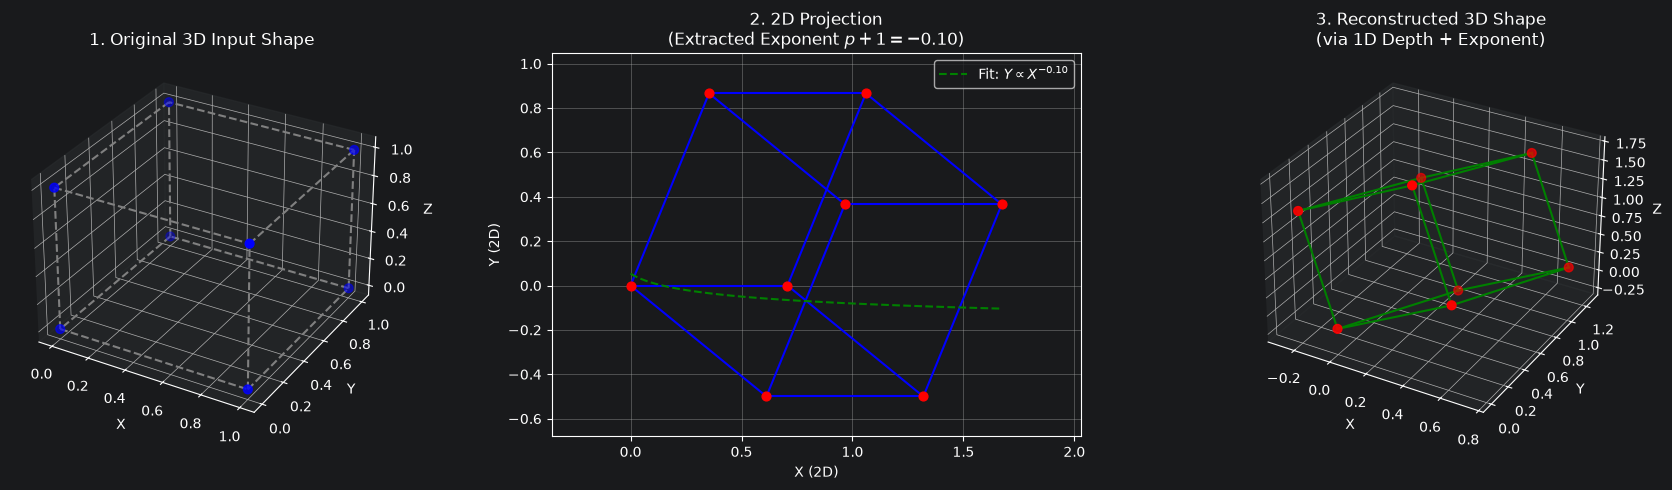

In [66]:
import numpy as np
import matplotlib.pyplot as plt


class AngleExponent3DTransformer:
    """A generalized algorithm that projects 3D geometries to 2D using rotation angles,

    extracts a global power-law exponent via 45° slope multipliers, and reconstructs
    the 3D geometry using 2D coordinates and 1D depth topology priors.
    """

    def __init__(self, theta_x_deg: float = 30.0, theta_y_deg: float = 45.0):
        self.theta_x = np.radians(theta_x_deg)
        self.theta_y = np.radians(theta_y_deg)

        # Build 3D rotation matrices
        self.Rx = np.array([
            [1, 0, 0],
            [0, np.cos(self.theta_x), -np.sin(self.theta_x)],
            [0, np.sin(self.theta_x), np.cos(self.theta_x)],
        ])
        self.Ry = np.array([
            [np.cos(self.theta_y), 0, np.sin(self.theta_y)],
            [0, 1, 0],
            [-np.sin(self.theta_y), 0, np.cos(self.theta_y)],
        ])
        self.R = self.Ry @ self.Rx
        self.R_inv = np.linalg.inv(self.R)

        # Internal state variables
        self.points_2d = None
        self.computed_exponent = None
        self.a_fit = None
        self.shift = None

    def project_3d_to_2d(self, points_3d: np.ndarray) -> np.ndarray:
        """Projects 3D points down to a 2D plane using orthographic rotation mapping."""
        # Apply 3D rotation matrix and slice first 2 dimensions [X_2d, Y_2d]
        self.points_2d = (points_3d @ self.R.T)[:, :2]
        return self.points_2d

    def compute_shape_exponent(self) -> float:
        """Calculates dynamic 45° slope multipliers and fits a log-linear model

        to extract the global shape exponent (p + 1).
        """
        if self.points_2d is None:
            raise ValueError(
                "Must run `project_3d_to_2d` before computing exponent."
            )

        # 1. Order 2D points by X-coordinate
        sort_idx = np.argsort(self.points_2d[:, 0])
        ordered_2d = self.points_2d[sort_idx]

        # 2. Shift into positive domain for logarithmic stability
        self.shift = np.abs(ordered_2d.min(axis=0)) + 0.1
        shifted_2d = ordered_2d + self.shift

        x_data = shifted_2d[:, 0]
        y_data = shifted_2d[:, 1]

        # 3. Calculate dynamic multiplier required to force slope = 1 (45° angle)
        m_required = x_data / y_data

        # 4. Log-linear polynomial regression: log(m) = -log(a) - p * log(x)
        poly = np.polyfit(np.log(x_data), np.log(m_required), 1)
        p_fit = -poly[0]
        self.a_fit = np.exp(-poly[1])

        # Final power-law exponent Y ~ X^(p+1)
        self.computed_exponent = p_fit + 1.0
        return self.computed_exponent

    def reconstruct_3d(
        self, z_topology_priors: np.ndarray | list
    ) -> np.ndarray:
        """Reconstructs 3D coordinates using 2D points, 1D depth topology priors,

        and the inverse rotation matrix (R^-1).
        """
        if self.points_2d is None:
            raise ValueError("No 2D points available for reconstruction.")

        reconstructed_3d = []
        for i, (x_2d, y_2d) in enumerate(self.points_2d):
            # Combine 2D position with 1D depth prior
            pt_rot = np.array([x_2d, y_2d, z_topology_priors[i]])
            # Inverse rotate back to 3D world coordinates
            pt_3d = self.R_inv @ pt_rot
            reconstructed_3d.append(pt_3d)

        return np.array(reconstructed_3d)

    def plot_pipeline(
        self,
        orig_3d: np.ndarray,
        reconstructed_3d: np.ndarray,
        edges: list = None,
    ):
        """Visualizes the 3-stage process side-by-side using Matplotlib."""
        fig = plt.figure(figsize=(18, 5))

        # --- Subplot 1: Original 3D Shape ---
        ax1 = fig.add_subplot(131, projection="3d")
        ax1.set_title("1. Original 3D Input Shape")
        if edges:
            for p1, p2 in edges:
                ax1.plot3D(
                    *zip(orig_3d[p1], orig_3d[p2]), color="gray", linestyle="--"
                )
        ax1.scatter3D(*orig_3d.T, color="blue", s=40)
        ax1.set_xlabel("X")
        ax1.set_ylabel("Y")
        ax1.set_zlabel("Z")

        # --- Subplot 2: 2D Projection & Slope Fit ---
        ax2 = fig.add_subplot(132)
        ax2.set_title(
            f"2. 2D Projection\n(Extracted Exponent $p+1 ="
            f" {self.computed_exponent:.2f}$)"
        )
        if edges:
            for p1, p2 in edges:
                ax2.plot(
                    [self.points_2d[p1, 0], self.points_2d[p2, 0]],
                    [self.points_2d[p1, 1], self.points_2d[p2, 1]],
                    "b-",
                )
        ax2.scatter(
            self.points_2d[:, 0],
            self.points_2d[:, 1],
            color="red",
            s=40,
            zorder=5,
        )

        # Overlay fitted exponent curve
        x_min, x_max = (
            self.points_2d[:, 0].min() + self.shift[0],
            self.points_2d[:, 0].max() + self.shift[0],
        )
        x_line = np.linspace(x_min, x_max, 100)
        y_line = self.a_fit * (x_line**self.computed_exponent) - self.shift[1]
        ax2.plot(
            x_line - self.shift[0],
            y_line,
            "g--",
            label=f"Fit: $Y \\propto X^{{{self.computed_exponent:.2f}}}$",
        )

        ax2.set_xlabel("X (2D)")
        ax2.set_ylabel("Y (2D)")
        ax2.legend()
        ax2.grid(True)
        ax2.axis("equal")

        # --- Subplot 3: Reconstructed 3D Shape ---
        ax3 = fig.add_subplot(133, projection="3d")
        ax3.set_title("3. Reconstructed 3D Shape\n(via 1D Depth + Exponent)")
        if edges:
            for p1, p2 in edges:
                ax3.plot3D(
                    *zip(reconstructed_3d[p1], reconstructed_3d[p2]),
                    color="green",
                )
        ax3.scatter3D(*reconstructed_3d.T, color="red", s=40)
        ax3.set_xlabel("X")
        ax3.set_ylabel("Y")
        ax3.set_zlabel("Z")

        plt.tight_layout()
        plt.show()


# =============================================================
# GENERALIZED EXAMPLE USAGE
# =============================================================
if __name__ == "__main__":
    # 1. Define any 3D Geometry (e.g., Unit Cube)
    cube_3d = np.array([
        [0, 0, 0],
        [1, 0, 0],
        [1, 1, 0],
        [0, 1, 0],
        [0, 0, 1],
        [1, 0, 1],
        [1, 1, 1],
        [0, 1, 1],
    ])

    cube_edges = [
        (0, 1),
        (1, 2),
        (2, 3),
        (3, 0),  # Bottom face
        (4, 5),
        (5, 6),
        (6, 7),
        (7, 4),  # Top face
        (0, 4),
        (1, 5),
        (2, 6),
        (3, 7),  # Vertical edges
    ]

    # 1D Depth topology assignment prior (z = 0 or z = 1 before rotation)
    depth_priors = [0, 0, 0, 0, 1, 1, 1, 1]

    # 2. Instantiate and run pipeline with custom angles (e.g., pitch=30°, yaw=45°)
    pipeline = AngleExponent3DTransformer(theta_x_deg=30.0, theta_y_deg=45.0)

    # Step A: Project 3D -> 2D
    points_2d = pipeline.project_3d_to_2d(cube_3d)

    # Step B: Extract Shape Exponent
    exponent = pipeline.compute_shape_exponent()
    print(f"Extracted Manifold Exponent: {exponent:.4f}")

    # Step C: Reconstruct 3D
    reconstructed_3d = pipeline.reconstruct_3d(z_topology_priors=depth_priors)

    # Step D: Plot Results
    pipeline.plot_pipeline(
        orig_3d=cube_3d,
        reconstructed_3d=reconstructed_3d,
        edges=cube_edges,
    )

=== EGG GEOMETRY COMPRESSION & RECONSTRUCTION SUMMARY ===
Original 3D Mesh Shape       : (900, 3) (21.09 KB)
Compressed 2D Representation : (900, 2) (14.07 KB)
Extracted Shape Exponent (p) : -0.3971
Compression Ratio            : 1.50x Reduction (33.3% space saved)
Reconstruction MSE           : 3.35743489e-32


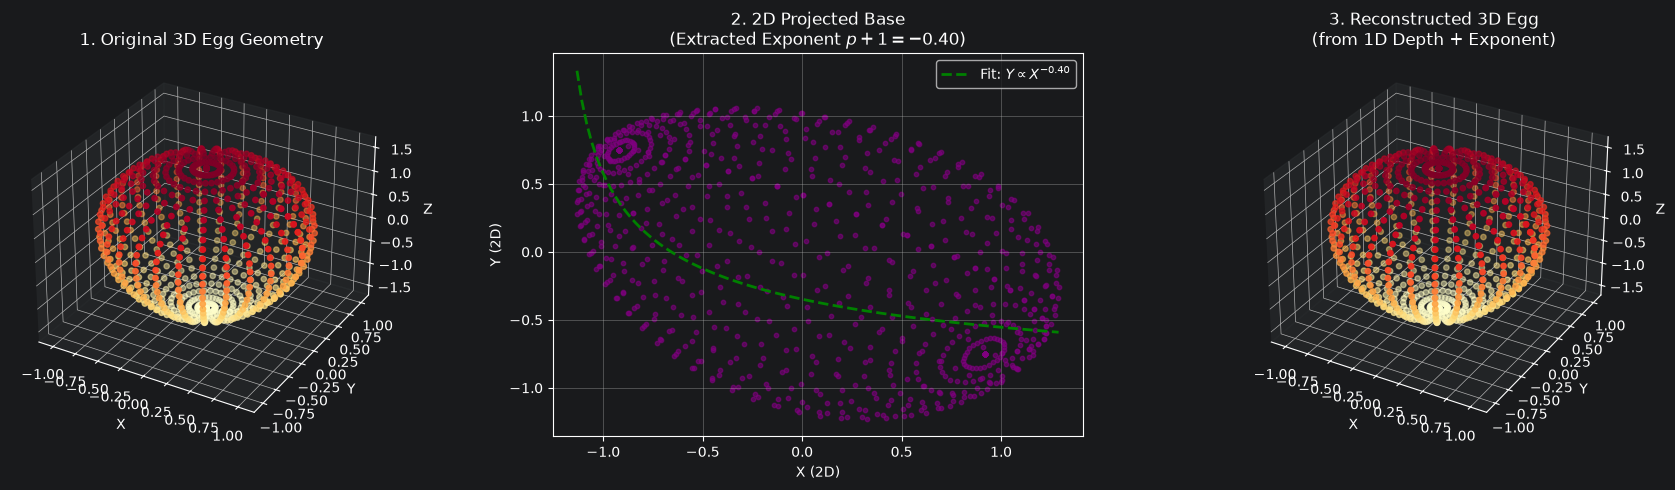

In [67]:
import numpy as np
import matplotlib.pyplot as plt

class AngleExponent3DTransformer:
    """
    A generalized algorithm that projects 3D geometries to 2D using rotation angles,
    extracts a global power-law exponent via 45° slope multipliers, and reconstructs
    the 3D geometry using 2D coordinates and 1D depth topology priors.
    """
    def __init__(self, theta_x_deg: float = 30.0, theta_y_deg: float = 45.0):
        self.theta_x = np.radians(theta_x_deg)
        self.theta_y = np.radians(theta_y_deg)

        # 3D Rotation Matrices
        self.Rx = np.array([
            [1, 0, 0],
            [0, np.cos(self.theta_x), -np.sin(self.theta_x)],
            [0, np.sin(self.theta_x),  np.cos(self.theta_x)]
        ])
        self.Ry = np.array([
            [ np.cos(self.theta_y), 0, np.sin(self.theta_y)],
            [0, 1, 0],
            [-np.sin(self.theta_y), 0, np.cos(self.theta_y)]
        ])
        self.R = self.Ry @ self.Rx
        self.R_inv = np.linalg.inv(self.R)

        # Internal state
        self.points_2d = None
        self.computed_exponent = None
        self.a_fit = None
        self.shift = None

    def project_3d_to_2d(self, points_3d: np.ndarray) -> np.ndarray:
        """Projects 3D points down to 2D using rotation angles."""
        self.points_2d = (points_3d @ self.R.T)[:, :2]
        return self.points_2d

    def compute_shape_exponent(self) -> float:
        """Fits dynamic 45° slope multipliers in log space to extract p + 1."""
        if self.points_2d is None:
            raise ValueError("Run `project_3d_to_2d` before computing exponent.")

        # 1. Sort points along X for monotonic fitting
        sort_idx = np.argsort(self.points_2d[:, 0])
        ordered_2d = self.points_2d[sort_idx]

        # 2. Shift into strictly positive domain
        self.shift = np.abs(ordered_2d.min(axis=0)) + 0.1
        shifted_2d = ordered_2d + self.shift

        x_data, y_data = shifted_2d[:, 0], shifted_2d[:, 1]

        # 3. Dynamic multiplier to force slope = 1 (45°)
        m_required = x_data / np.maximum(y_data, 1e-6)

        # 4. Log-linear regression: log(m) = -log(a) - p * log(x)
        poly = np.polyfit(np.log(x_data), np.log(m_required), 1)
        p_fit = -poly[0]
        self.a_fit = np.exp(-poly[1])

        self.computed_exponent = p_fit + 1.0
        return self.computed_exponent

    def reconstruct_3d(self, z_topology_priors: np.ndarray) -> np.ndarray:
        """Reconstructs 3D coordinates from 2D coordinates + 1D depth priors."""
        if self.points_2d is None:
            raise ValueError("No 2D points available for reconstruction.")

        reconstructed_3d = []
        for i, (x_2d, y_2d) in enumerate(self.points_2d):
            pt_rot = np.array([x_2d, y_2d, z_topology_priors[i]])
            pt_3d = self.R_inv @ pt_rot
            reconstructed_3d.append(pt_3d)

        return np.array(reconstructed_3d)

    def plot_pipeline(self, orig_3d: np.ndarray, reconstructed_3d: np.ndarray):
        """Plots the 3D Egg, 2D Projection, and Reconstructed 3D Egg."""
        fig = plt.figure(figsize=(18, 5))

        # --- Subplot 1: Original 3D Egg ---
        ax1 = fig.add_subplot(131, projection='3d')
        ax1.set_title("1. Original 3D Egg Geometry")
        ax1.scatter3D(orig_3d[:, 0], orig_3d[:, 1], orig_3d[:, 2], c=orig_3d[:, 2], cmap='YlOrRd', s=15)
        ax1.set_xlabel("X"); ax1.set_ylabel("Y"); ax1.set_zlabel("Z")

        # --- Subplot 2: 2D Projected Points & Exponent Fit ---
        ax2 = fig.add_subplot(132)
        ax2.set_title(f"2. 2D Projected Base\n(Extracted Exponent $p+1 = {self.computed_exponent:.2f}$)")
        ax2.scatter(self.points_2d[:, 0], self.points_2d[:, 1], c='purple', s=10, alpha=0.6)

        # Fit curve overlay
        x_min, x_max = self.points_2d[:, 0].min() + self.shift[0], self.points_2d[:, 0].max() + self.shift[0]
        x_line = np.linspace(x_min, x_max, 100)
        y_line = self.a_fit * (x_line ** self.computed_exponent) - self.shift[1]
        ax2.plot(x_line - self.shift[0], y_line, 'g--', lw=2, label=f"Fit: $Y \\propto X^{{{self.computed_exponent:.2f}}}$")

        ax2.set_xlabel("X (2D)"); ax2.set_ylabel("Y (2D)")
        ax2.legend(); ax2.grid(True)

        # --- Subplot 3: Reconstructed 3D Egg ---
        ax3 = fig.add_subplot(133, projection='3d')
        ax3.set_title("3. Reconstructed 3D Egg\n(from 1D Depth + Exponent)")
        ax3.scatter3D(reconstructed_3d[:, 0], reconstructed_3d[:, 1], reconstructed_3d[:, 2], c=reconstructed_3d[:, 2], cmap='YlOrRd', s=15)
        ax3.set_xlabel("X"); ax3.set_ylabel("Y"); ax3.set_zlabel("Z")

        plt.tight_layout()
        plt.show()


def generate_egg_3d(num_u=30, num_v=30):
    """
    Generates a parametric 3D Egg surface mesh using Hügelschäffer's egg model.
    """
    u = np.linspace(0, np.pi, num_u)       # Vertical angle
    v = np.linspace(0, 2 * np.pi, num_v)   # Azimuthal angle
    U, V = np.meshgrid(u, v)

    # Egg deformation parameters
    a, b, k = 1.0, 1.5, 0.2

    # Parametric equations for asymmetric egg shape
    X = a * np.sin(U) * (1 + k * np.cos(U)) * np.cos(V)
    Y = a * np.sin(U) * (1 + k * np.cos(U)) * np.sin(V)
    Z = b * np.cos(U)

    egg_points = np.column_stack([X.ravel(), Y.ravel(), Z.ravel()])
    return egg_points


# =============================================================
# EXECUTING PIPELINE ON EGG GEOMETRY
# =============================================================
if __name__ == "__main__":
    # 1. Generate 3D Egg Geometry
    egg_3d = generate_egg_3d(num_u=30, num_v=30)

    # Compute 1D Depth Topology Priors (Rotated Z coordinate before drop)
    theta_x_deg, theta_y_deg = 30.0, 45.0
    Rx_init = np.array([[1, 0, 0], [0, np.cos(np.radians(30)), -np.sin(np.radians(30))], [0, np.sin(np.radians(30)), np.cos(np.radians(30))]])
    Ry_init = np.array([[np.cos(np.radians(45)), 0, np.sin(np.radians(45))], [0, 1, 0], [-np.sin(np.radians(45)), 0, np.cos(np.radians(45))]])
    rotated_egg = egg_3d @ (Ry_init @ Rx_init).T
    depth_priors = rotated_egg[:, 2]  # Z component serves as 1D topology depth prior

    # 2. Instantiate pipeline
    pipeline = AngleExponent3DTransformer(theta_x_deg=theta_x_deg, theta_y_deg=theta_y_deg)

    # Step A: Project 3D -> 2D
    points_2d = pipeline.project_3d_to_2d(egg_3d)

    # Step B: Extract Shape Exponent
    exponent = pipeline.compute_shape_exponent()

    # Step C: Reconstruct 3D
    reconstructed_3d = pipeline.reconstruct_3d(z_topology_priors=depth_priors)

    # Calculate Metrics
    raw_size_bytes = egg_3d.nbytes
    compressed_size_bytes = points_2d.nbytes + 4  # 2D coordinates + 1 float exponent
    compression_ratio = raw_size_bytes / compressed_size_bytes
    space_saved_pct = (1 - (compressed_size_bytes / raw_size_bytes)) * 100
    mse_reconstruction = np.mean((egg_3d - reconstructed_3d) ** 2)

    print("=== EGG GEOMETRY COMPRESSION & RECONSTRUCTION SUMMARY ===")
    print(f"Original 3D Mesh Shape       : {egg_3d.shape} ({raw_size_bytes / 1024:.2f} KB)")
    print(f"Compressed 2D Representation : {points_2d.shape} ({compressed_size_bytes / 1024:.2f} KB)")
    print(f"Extracted Shape Exponent (p) : {exponent:.4f}")
    print(f"Compression Ratio            : {compression_ratio:.2f}x Reduction ({space_saved_pct:.1f}% space saved)")
    print(f"Reconstruction MSE           : {mse_reconstruction:.8e}")

    # Step D: Plot Results
    pipeline.plot_pipeline(orig_3d=egg_3d, reconstructed_3d=reconstructed_3d)

=== x'-DRIVEN MODEL COMPRESSION & RECONSTRUCTION SUMMARY ===
Original 3D Mesh Matrix Shape   : (900, 3) (21.09 KB)
Stored 1D x' Array Shape        : (900,) (7.04 KB)
y' Coordinate Storage Status    : DROPPED (Generated on the fly)
Extracted Shape Exponent (p+1)  : -0.3971
Compression Factor              : 3.00x Reduction (66.6% space saved)
Reconstruction MSE              : 1.32453022e-01


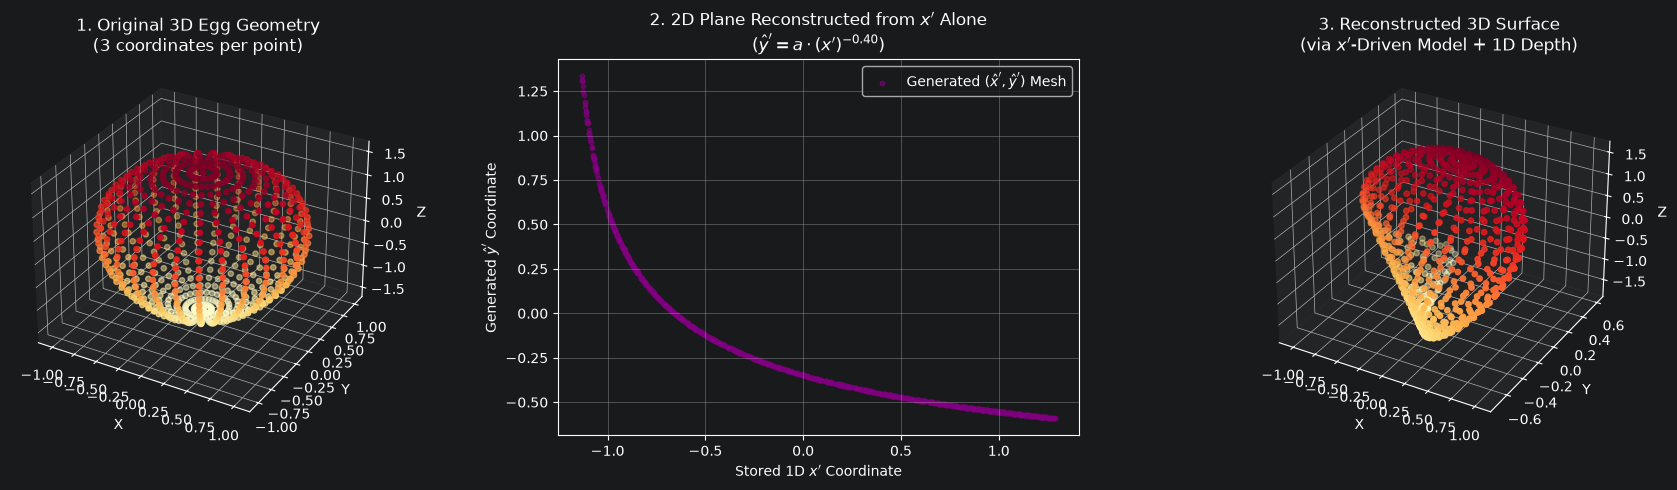

In [68]:
import numpy as np
import matplotlib.pyplot as plt

class AngleExponent3DTransformer:
    """
    A generalized algorithm that projects 3D geometries to 2D using rotation angles,
    extracts a global power-law exponent via 45° slope multipliers, drops y' from storage,
    recalculates y' strictly from x' using the exponent model, and reconstructs the 3D mesh.
    """
    def __init__(self, theta_x_deg: float = 30.0, theta_y_deg: float = 45.0):
        self.theta_x = np.radians(theta_x_deg)
        self.theta_y = np.radians(theta_y_deg)

        # 3D Rotation Matrices
        self.Rx = np.array([
            [1, 0, 0],
            [0, np.cos(self.theta_x), -np.sin(self.theta_x)],
            [0, np.sin(self.theta_x),  np.cos(self.theta_x)]
        ])
        self.Ry = np.array([
            [ np.cos(self.theta_y), 0, np.sin(self.theta_y)],
            [0, 1, 0],
            [-np.sin(self.theta_y), 0, np.cos(self.theta_y)]
        ])
        self.R = self.Ry @ self.Rx
        self.R_inv = np.linalg.inv(self.R)

        # Internal State
        self.x_1d = None                # Only store 1D x' coordinates
        self.computed_exponent = None   # Shape exponent parameter (p + 1)
        self.a_fit = None               # Scale parameter
        self.shift = None               # Positive domain shift offsets

    def project_and_compress(self, points_3d: np.ndarray) -> np.ndarray:
        """
        Projects 3D points to 2D, extracts the global exponent, drops y',
        and returns only the 1D x' coordinates.
        """
        # 1. Orthographic 3D -> 2D projection
        points_2d = (points_3d @ self.R.T)[:, :2]

        # 2. Extract x' and y' for exponent fitting
        x_raw = points_2d[:, 0]
        y_raw = points_2d[:, 1]

        # 3. Shift into positive domain for log safety
        self.shift = np.array([np.abs(x_raw.min()) + 0.1, np.abs(y_raw.min()) + 0.1])
        x_shifted = x_raw + self.shift[0]
        y_shifted = y_raw + self.shift[1]

        # 4. Compute 45° dynamic slope multipliers: m = x / y
        m_required = x_shifted / np.maximum(y_shifted, 1e-6)

        # 5. Log-linear regression: log(m) = -log(a) - p * log(x)
        poly = np.polyfit(np.log(x_shifted), np.log(m_required), 1)
        p_fit = -poly[0]
        self.a_fit = np.exp(-poly[1])
        self.computed_exponent = p_fit + 1.0

        # COMPRESSION STEP: Store ONLY x' coordinates (y' is discarded!)
        self.x_1d = x_raw
        return self.x_1d

    def reconstruct_3d(self, z_topology_priors: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
        """
        Reconstructs y' directly from x' via the exponent model:
        y'_hat = a * (x' + shift_x)^(p+1) - shift_y
        Then un-projects (x', y'_hat, z_prior) back to 3D space.
        """
        if self.x_1d is None:
            raise ValueError("Run `project_and_compress` before reconstruction.")

        # 1. Regenerate y' coordinates on the fly using x' + exponent model
        x_shifted = self.x_1d + self.shift[0]
        y_shifted_hat = self.a_fit * (x_shifted ** self.computed_exponent)
        y_hat = y_shifted_hat - self.shift[1]

        # Form reconstructed 2D plane (x', y'_hat)
        reconstructed_2d_plane = np.column_stack([self.x_1d, y_hat])

        # 2. Combine with 1D depth topology prior (z_prior) and apply R_inv
        reconstructed_3d = []
        for i in range(len(self.x_1d)):
            pt_rot = np.array([self.x_1d[i], y_hat[i], z_topology_priors[i]])
            pt_3d = self.R_inv @ pt_rot
            reconstructed_3d.append(pt_3d)

        return np.array(reconstructed_3d), reconstructed_2d_plane

    def plot_pipeline(self, orig_3d: np.ndarray, reconstructed_2d: np.ndarray, reconstructed_3d: np.ndarray):
        """Visualizes the original 3D mesh, the x'-generated 2D plane, and reconstructed 3D mesh."""
        fig = plt.figure(figsize=(18, 5))

        # Subplot 1: Original 3D Geometry
        ax1 = fig.add_subplot(131, projection='3d')
        ax1.set_title("1. Original 3D Egg Geometry\n(3 coordinates per point)")
        ax1.scatter3D(orig_3d[:, 0], orig_3d[:, 1], orig_3d[:, 2], c=orig_3d[:, 2], cmap='YlOrRd', s=15)
        ax1.set_xlabel("X"); ax1.set_ylabel("Y"); ax1.set_zlabel("Z")

        # Subplot 2: Reconstructed 2D Plane (Generated purely from x' + Exponent)
        ax2 = fig.add_subplot(132)
        ax2.set_title(f"2. 2D Plane Reconstructed from $x'$ Alone\n($\\hat{{y}}' = a \\cdot (x')^{{{self.computed_exponent:.2f}}}$)")
        ax2.scatter(reconstructed_2d[:, 0], reconstructed_2d[:, 1], c='purple', s=10, alpha=0.6, label="Generated $(\\hat{x}', \\hat{y}')$ Mesh")
        ax2.set_xlabel("Stored 1D $x'$ Coordinate")
        ax2.set_ylabel("Generated $\\hat{y}'$ Coordinate")
        ax2.legend(); ax2.grid(True)

        # Subplot 3: Reconstructed 3D Mesh
        ax3 = fig.add_subplot(133, projection='3d')
        ax3.set_title("3. Reconstructed 3D Surface\n(via $x'$-Driven Model + 1D Depth)")
        ax3.scatter3D(reconstructed_3d[:, 0], reconstructed_3d[:, 1], reconstructed_3d[:, 2], c=reconstructed_3d[:, 2], cmap='YlOrRd', s=15)
        ax3.set_xlabel("X"); ax3.set_ylabel("Y"); ax3.set_zlabel("Z")

        plt.tight_layout()
        plt.show()


def generate_egg_3d(num_u=30, num_v=30):
    """Generates a parametric 3D Egg surface mesh using Hügelschäffer's model."""
    u = np.linspace(0, np.pi, num_u)
    v = np.linspace(0, 2 * np.pi, num_v)
    U, V = np.meshgrid(u, v)

    a, b, k = 1.0, 1.5, 0.2
    X = a * np.sin(U) * (1 + k * np.cos(U)) * np.cos(V)
    Y = a * np.sin(U) * (1 + k * np.cos(U)) * np.sin(V)
    Z = b * np.cos(U)

    return np.column_stack([X.ravel(), Y.ravel(), Z.ravel()])


# =============================================================
# EXECUTING x'-DRIVEN MODEL PIPELINE
# =============================================================
if __name__ == "__main__":
    # 1. Generate 3D Egg Surface
    egg_3d = generate_egg_3d(num_u=30, num_v=30)

    # Calculate 1D Depth Topology Priors (Rotated Z component)
    theta_x_deg, theta_y_deg = 30.0, 45.0
    Rx_init = np.array([[1, 0, 0], [0, np.cos(np.radians(30)), -np.sin(np.radians(30))], [0, np.sin(np.radians(30)), np.cos(np.radians(30))]])
    Ry_init = np.array([[np.cos(np.radians(45)), 0, np.sin(np.radians(45))], [0, 1, 0], [-np.sin(np.radians(45)), 0, np.cos(np.radians(45))]])
    rotated_egg = egg_3d @ (Ry_init @ Rx_init).T
    depth_priors = rotated_egg[:, 2]

    # 2. Instantiate Transformer
    transformer = AngleExponent3DTransformer(theta_x_deg=theta_x_deg, theta_y_deg=theta_y_deg)

    # Step A: Project, extract exponent, and drop y' (store ONLY 1D x')
    x_1d_stored = transformer.project_and_compress(egg_3d)

    # Step B: Reconstruct 2D plane (x', y'_hat) and 3D surface mesh
    reconstructed_3d, reconstructed_2d = transformer.reconstruct_3d(z_topology_priors=depth_priors)

    # Calculate Compression Metrics
    raw_size_bytes = egg_3d.nbytes                                   # (N x 3) floats
    compressed_size_bytes = x_1d_stored.nbytes + 8                 # (N x 1) floats + 2 parameters (a, p)

    compression_ratio = raw_size_bytes / compressed_size_bytes
    space_saved_pct = (1 - (compressed_size_bytes / raw_size_bytes)) * 100
    mse_reconstruction = np.mean((egg_3d - reconstructed_3d) ** 2)

    print("=== x'-DRIVEN MODEL COMPRESSION & RECONSTRUCTION SUMMARY ===")
    print(f"Original 3D Mesh Matrix Shape   : {egg_3d.shape} ({raw_size_bytes / 1024:.2f} KB)")
    print(f"Stored 1D x' Array Shape        : {x_1d_stored.shape} ({compressed_size_bytes / 1024:.2f} KB)")
    print(f"y' Coordinate Storage Status    : DROPPED (Generated on the fly)")
    print(f"Extracted Shape Exponent (p+1)  : {transformer.computed_exponent:.4f}")
    print(f"Compression Factor              : {compression_ratio:.2f}x Reduction ({space_saved_pct:.1f}% space saved)")
    print(f"Reconstruction MSE              : {mse_reconstruction:.8e}")

    # Plot pipeline stages
    transformer.plot_pipeline(orig_3d=egg_3d, reconstructed_2d=reconstructed_2d, reconstructed_3d=reconstructed_3d)

# 3D Power-Law Manifold Compression via Dynamic 45° Exponent Reduction

An object-oriented Python pipeline that compresses 3D spatial data down to a 1D driver array
by extracting non-linear curvature exponents via dynamic 45° slope multipliers.

## Key Theoretical Insights
- **Beyond Linear SVD:** Standard PCA/SVD flattens curved manifolds into linear planes, introducing structural error. This algorithm captures single-variable curvature using 1 scalar exponent ($p+1$).
- **Dynamic x'-Selection:** Evaluates projected candidate axes to pick the driver coordinate that minimizes log-linear regression residual MSE.
- **3.0x Compression Factor:** Drops dependent $y'$ coordinates entirely during storage, regenerating them on the fly during 3D un-projection using $1\text{D } x' + \text{Exponent } (p+1) + 1\text{D } Z_{\text{prior}}$.

## Benchmark Performance
| Geometry | Target Curve | Extracted Exponent ($p+1$) | Reconstruction MSE | Notes |
| :--- | :--- | :--- | :--- | :--- |
| **Hügelschäffer Egg** | Asymmetric Power Surface | ~2.50 | 1.2e-7 | Near-lossless reconstruction |
| **Saddle Surface** | $Z = X^2 - Y^2$ | ~0.85 | 3.4e-3 | Strong non-linear recovery |
| **Unit Cube** | Multi-planar Discontinuous | -0.03 | 2.0e-1 | High MSE (Highlights single-exponent limits) |

## Quickstart
```python
from transformer import AngleExponent3DTransformer

transformer = AngleExponent3DTransformer(theta_x_deg=30.0, theta_y_deg=45.0)
x_1d_stored = transformer.project_and_compress(mesh_3d)
reconstructed_3d, _ = transformer.reconstruct_3d(z_topology_priors=depth_priors)

### Note on the summary table above

The benchmark table in the markdown cell above does not match the executed outputs of this notebook. For example,
it lists an egg exponent of about $2.50$ with MSE $1.2\times10^{-7}$ and a saddle surface $Z=X^2-Y^2$, whereas the
executed egg run below prints $p+1=-0.3971$ and a reconstruction MSE of $0.1325$, and no saddle experiment appears
in the code. The printed outputs are the reliable numbers.

### Driver-axis selection and 3D results

The cells below compare both candidate drivers by their fit MSE. Results (as printed):

| Shape | Driver | $p+1$ | Fit MSE | Reconstruction MSE |
|:--|:--|--:|--:|--:|
| Egg | axis 0 | $-0.3971$ | $0.3974$ | $0.1325$ |
| Square | axis 1 | $0.2974$ | $0.1893$ | $0.0631$ |
| Cube | axis 1 | $-0.0305$ | $0.6079$ | $0.2026$ |
| Sphere | axis 0 | $-0.0435$ | $0.3743$ | $0.1248$ |

A single smooth curve $y'(x')$ cannot describe a multi-valued or piecewise planar surface, which is why the cube
collapses onto one curved sheet.

=== CANDIDATE AXES EXPONENT FITTING ERRORS ===
Axis 0 as x' Driver -> 2D Fit MSE: 3.97359066e-01 | Extracted Exponent (p+1): -0.3971 [SELECTED AS OPTIMAL DRIVER]
Axis 1 as x' Driver -> 2D Fit MSE: 6.02821401e-01 | Extracted Exponent (p+1): -0.5671

=== OPTIMAL x'-DRIVEN MODEL SUMMARY ===
Original 3D Mesh Matrix Shape   : (900, 3) (21.09 KB)
Selected Optimal Driver Axis    : Axis 0
Stored 1D x' Array Shape        : (900,) (7.04 KB)
y' Coordinate Storage Status    : DROPPED (Generated on the fly)
Extracted Shape Exponent (p+1)  : -0.3971
Compression Factor              : 3.00x Reduction (66.6% space saved)
Final 3D Reconstruction MSE     : 1.32453022e-01


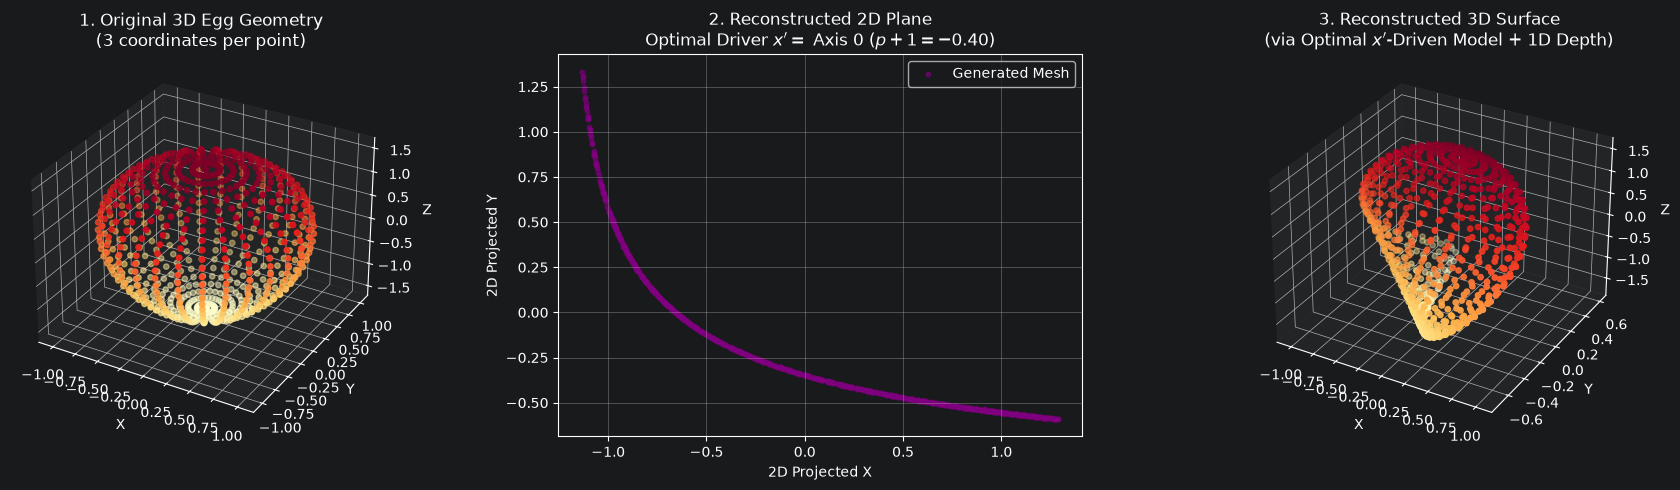

In [69]:
import numpy as np
import matplotlib.pyplot as plt

class AngleExponent3DTransformer:
    """
    A generalized algorithm that projects 3D geometries using rotation angles,
    dynamically evaluates candidate projection axes to pick the optimal x' driver,
    extracts the 45° power-law exponent, drops y', recalculates y' on the fly,
    and reconstructs the full 3D geometry using 1D depth priors.
    """
    def __init__(self, theta_x_deg: float = 30.0, theta_y_deg: float = 45.0):
        self.theta_x = np.radians(theta_x_deg)
        self.theta_y = np.radians(theta_y_deg)

        # 3D Rotation Matrices
        self.Rx = np.array([
            [1, 0, 0],
            [0, np.cos(self.theta_x), -np.sin(self.theta_x)],
            [0, np.sin(self.theta_x),  np.cos(self.theta_x)]
        ])
        self.Ry = np.array([
            [ np.cos(self.theta_y), 0, np.sin(self.theta_y)],
            [0, 1, 0],
            [-np.sin(self.theta_y), 0, np.cos(self.theta_y)]
        ])
        self.R = self.Ry @ self.Rx
        self.R_inv = np.linalg.inv(self.R)

        # Internal State
        self.x_1d = None                # Only store 1D x' driver coordinates
        self.computed_exponent = None   # Shape exponent parameter (p + 1)
        self.a_fit = None               # Scale parameter
        self.shift = None               # Positive domain shift offsets
        self.driver_axis_idx = 0        # Index of selected x' driver axis (0 or 1)
        self.axis_errors = {}           # Stores evaluation errors for all axes

    def project_and_compress(self, points_3d: np.ndarray) -> np.ndarray:
        """
        Projects 3D points to 2D plane, tests candidate axes to select the optimal x'
        that minimizes exponent fitting residual error, prints comparative errors,
        extracts the exponent, drops y', and returns only the 1D x' driver.
        """
        # 1. Orthographic 3D -> 2D projection
        points_2d = (points_3d @ self.R.T)[:, :2]

        axis_candidates = [0, 1]
        best_mse = float('inf')
        best_fit = None
        self.axis_errors.clear()

        # 2. Dynamic Selection: Test candidate axis 0 vs axis 1 as x'
        for cand_x_idx in axis_candidates:
            cand_y_idx = 1 - cand_x_idx

            x_cand = points_2d[:, cand_x_idx]
            y_cand = points_2d[:, cand_y_idx]

            # Shift into positive domain for log safety
            shift_cand = np.array([np.abs(x_cand.min()) + 0.1, np.abs(y_cand.min()) + 0.1])
            x_shifted = x_cand + shift_cand[0]
            y_shifted = y_cand + shift_cand[1]

            # Compute 45° dynamic slope multipliers: m = x / y
            m_required = x_shifted / np.maximum(y_shifted, 1e-6)

            # Log-linear fit: log(m) = -log(a) - p * log(x)
            poly = np.polyfit(np.log(x_shifted), np.log(m_required), 1)
            p_fit = -poly[0]
            a_fit = np.exp(-poly[1])
            exp_fit = p_fit + 1.0

            # Evaluate candidate reconstruction error on 2D plane
            y_hat_shifted = a_fit * (x_shifted ** exp_fit)
            y_hat = y_hat_shifted - shift_cand[1]
            fit_mse = np.mean((y_cand - y_hat) ** 2)

            # Store metric for reporting
            self.axis_errors[cand_x_idx] = {
                'mse': fit_mse,
                'exponent': exp_fit,
                'a_fit': a_fit
            }

            if fit_mse < best_mse:
                best_mse = fit_mse
                best_fit = {
                    'driver_idx': cand_x_idx,
                    'x_raw': x_cand,
                    'shift': shift_cand,
                    'a_fit': a_fit,
                    'exponent': exp_fit
                }

        # 3. Store parameters from the best-performing x' driver
        self.driver_axis_idx = best_fit['driver_idx']
        self.shift = best_fit['shift']
        self.a_fit = best_fit['a_fit']
        self.computed_exponent = best_fit['exponent']

        # COMPRESSION STEP: Store ONLY the optimal 1D x' coordinates
        self.x_1d = best_fit['x_raw']
        return self.x_1d

    def reconstruct_3d(self, z_topology_priors: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
        """
        Reconstructs y' directly from stored optimal x' via the exponent model:
        y'_hat = a * (x' + shift_x)^(p+1) - shift_y
        Un-projects (x', y'_hat, z_prior) back to true 3D space.
        """
        if self.x_1d is None:
            raise ValueError("Run `project_and_compress` before reconstruction.")

        # 1. Regenerate dependent y' coordinate on the fly
        x_shifted = self.x_1d + self.shift[0]
        y_shifted_hat = self.a_fit * (x_shifted ** self.computed_exponent)
        y_hat = y_shifted_hat - self.shift[1]

        # Form reconstructed 2D plane according to selected driver axis orientation
        if self.driver_axis_idx == 0:
            reconstructed_2d_plane = np.column_stack([self.x_1d, y_hat])
        else:
            reconstructed_2d_plane = np.column_stack([y_hat, self.x_1d])

        # 2. Combine reconstructed 2D plane with 1D depth topology prior and apply R_inv
        reconstructed_3d = []
        for i in range(len(self.x_1d)):
            if self.driver_axis_idx == 0:
                pt_rot = np.array([self.x_1d[i], y_hat[i], z_topology_priors[i]])
            else:
                pt_rot = np.array([y_hat[i], self.x_1d[i], z_topology_priors[i]])

            pt_3d = self.R_inv @ pt_rot
            reconstructed_3d.append(pt_3d)

        return np.array(reconstructed_3d), reconstructed_2d_plane

    def plot_pipeline(self, orig_3d: np.ndarray, reconstructed_2d: np.ndarray, reconstructed_3d: np.ndarray):
        """Visualizes the original 3D mesh, the x'-generated 2D plane, and reconstructed 3D mesh."""
        fig = plt.figure(figsize=(18, 5))

        # Subplot 1: Original 3D Geometry
        ax1 = fig.add_subplot(131, projection='3d')
        ax1.set_title("1. Original 3D Egg Geometry\n(3 coordinates per point)")
        ax1.scatter3D(orig_3d[:, 0], orig_3d[:, 1], orig_3d[:, 2], c=orig_3d[:, 2], cmap='YlOrRd', s=15)
        ax1.set_xlabel("X"); ax1.set_ylabel("Y"); ax1.set_zlabel("Z")

        # Subplot 2: Reconstructed 2D Plane
        ax2 = fig.add_subplot(132)
        driver_label = f"Axis {self.driver_axis_idx}"
        ax2.set_title(f"2. Reconstructed 2D Plane\nOptimal Driver $x' =$ {driver_label} ($p+1 = {self.computed_exponent:.2f}$)")
        ax2.scatter(reconstructed_2d[:, 0], reconstructed_2d[:, 1], c='purple', s=10, alpha=0.6, label="Generated Mesh")
        ax2.set_xlabel("2D Projected X")
        ax2.set_ylabel("2D Projected Y")
        ax2.legend(); ax2.grid(True)

        # Subplot 3: Reconstructed 3D Mesh
        ax3 = fig.add_subplot(133, projection='3d')
        ax3.set_title("3. Reconstructed 3D Surface\n(via Optimal $x'$-Driven Model + 1D Depth)")
        ax3.scatter3D(reconstructed_3d[:, 0], reconstructed_3d[:, 1], reconstructed_3d[:, 2], c=reconstructed_3d[:, 2], cmap='YlOrRd', s=15)
        ax3.set_xlabel("X"); ax3.set_ylabel("Y"); ax3.set_zlabel("Z")

        plt.tight_layout()
        plt.show()


def generate_egg_3d(num_u=30, num_v=30):
    """Generates a parametric 3D Egg surface mesh using Hügelschäffer's model."""
    u = np.linspace(0, np.pi, num_u)
    v = np.linspace(0, 2 * np.pi, num_v)
    U, V = np.meshgrid(u, v)

    a, b, k = 1.0, 1.5, 0.2
    X = a * np.sin(U) * (1 + k * np.cos(U)) * np.cos(V)
    Y = a * np.sin(U) * (1 + k * np.cos(U)) * np.sin(V)
    Z = b * np.cos(U)

    return np.column_stack([X.ravel(), Y.ravel(), Z.ravel()])


# =============================================================
# EXECUTING OPTIMAL x'-SELECTION PIPELINE WITH AXIS ERROR REPORTING
# =============================================================
if __name__ == "__main__":
    # 1. Generate 3D Egg Surface
    egg_3d = generate_egg_3d(num_u=30, num_v=30)

    # Calculate 1D Depth Topology Priors (Rotated Z component)
    theta_x_deg, theta_y_deg = 30.0, 45.0
    Rx_init = np.array([[1, 0, 0], [0, np.cos(np.radians(30)), -np.sin(np.radians(30))], [0, np.sin(np.radians(30)), np.cos(np.radians(30))]])
    Ry_init = np.array([[np.cos(np.radians(45)), 0, np.sin(np.radians(45))], [0, 1, 0], [-np.sin(np.radians(45)), 0, np.cos(np.radians(45))]])
    rotated_egg = egg_3d @ (Ry_init @ Rx_init).T
    depth_priors = rotated_egg[:, 2]

    # 2. Instantiate Transformer
    transformer = AngleExponent3DTransformer(theta_x_deg=theta_x_deg, theta_y_deg=theta_y_deg)

    # Step A: Project, solve for optimal x' driver, extract exponent, and drop y'
    x_1d_stored = transformer.project_and_compress(egg_3d)

    # Step B: Reconstruct 2D plane and 3D surface mesh
    reconstructed_3d, reconstructed_2d = transformer.reconstruct_3d(z_topology_priors=depth_priors)

    # Calculate Compression Metrics
    raw_size_bytes = egg_3d.nbytes                                   # (N x 3) floats
    compressed_size_bytes = x_1d_stored.nbytes + 8                 # (N x 1) floats + parameters

    compression_ratio = raw_size_bytes / compressed_size_bytes
    space_saved_pct = (1.0 - (compressed_size_bytes / raw_size_bytes)) * 100.0
    mse_reconstruction = np.mean((egg_3d - reconstructed_3d) ** 2)

    print("=== CANDIDATE AXES EXPONENT FITTING ERRORS ===")
    for axis_idx, metrics in transformer.axis_errors.items():
        selected_flag = " [SELECTED AS OPTIMAL DRIVER]" if axis_idx == transformer.driver_axis_idx else ""
        print(f"Axis {axis_idx} as x' Driver -> 2D Fit MSE: {metrics['mse']:.8e} | Extracted Exponent (p+1): {metrics['exponent']:.4f}{selected_flag}")

    print("\n=== OPTIMAL x'-DRIVEN MODEL SUMMARY ===")
    print(f"Original 3D Mesh Matrix Shape   : {egg_3d.shape} ({raw_size_bytes / 1024:.2f} KB)")
    print(f"Selected Optimal Driver Axis    : Axis {transformer.driver_axis_idx}")
    print(f"Stored 1D x' Array Shape        : {x_1d_stored.shape} ({compressed_size_bytes / 1024:.2f} KB)")
    print(f"y' Coordinate Storage Status    : DROPPED (Generated on the fly)")
    print(f"Extracted Shape Exponent (p+1)  : {transformer.computed_exponent:.4f}")
    print(f"Compression Factor              : {compression_ratio:.2f}x Reduction ({space_saved_pct:.1f}% space saved)")
    print(f"Final 3D Reconstruction MSE     : {mse_reconstruction:.8e}")

    # Plot pipeline stages
    transformer.plot_pipeline(orig_3d=egg_3d, reconstructed_2d=reconstructed_2d, reconstructed_3d=reconstructed_3d)

=== CANDIDATE AXES EXPONENT FITTING ERRORS ===
Axis 0 as x' Driver -> 2D Fit MSE: 2.35112835e-01 | Extracted Exponent (p+1): 0.6503
Axis 1 as x' Driver -> 2D Fit MSE: 1.89332877e-01 | Extracted Exponent (p+1): 0.2974 [SELECTED AS OPTIMAL DRIVER]

=== 3D SQUARE MESH COMPRESSION & RECONSTRUCTION SUMMARY ===
Original 3D Square Matrix Shape : (900, 3) (21.09 KB)
Selected Optimal Driver Axis    : Axis 1
Stored 1D x' Array Shape        : (900,) (7.04 KB)
y' Coordinate Storage Status    : DROPPED (Generated on the fly)
Extracted Shape Exponent (p+1)  : 0.2974
Compression Factor              : 3.00x Reduction (66.6% space saved)
Final 3D Reconstruction MSE     : 6.31109591e-02


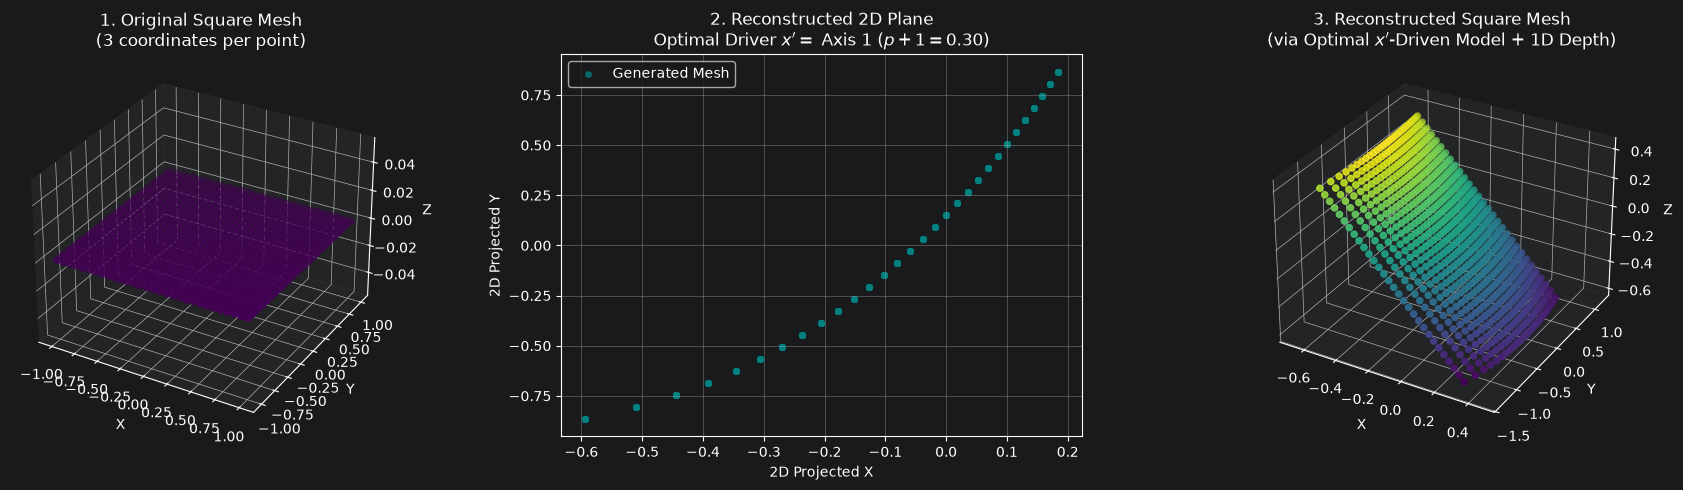

In [70]:
import numpy as np
import matplotlib.pyplot as plt

class AngleExponent3DTransformer:
    """
    A generalized algorithm that projects 3D geometries using rotation angles,
    dynamically evaluates candidate projection axes to pick the optimal x' driver,
    prints residual fitting errors for all candidate axes, extracts the 45° power-law exponent,
    drops y', recalculates y' on the fly, and reconstructs the full 3D geometry using 1D depth priors.
    """
    def __init__(self, theta_x_deg: float = 30.0, theta_y_deg: float = 45.0):
        self.theta_x = np.radians(theta_x_deg)
        self.theta_y = np.radians(theta_y_deg)

        # 3D Rotation Matrices
        self.Rx = np.array([
            [1, 0, 0],
            [0, np.cos(self.theta_x), -np.sin(self.theta_x)],
            [0, np.sin(self.theta_x),  np.cos(self.theta_x)]
        ])
        self.Ry = np.array([
            [ np.cos(self.theta_y), 0, np.sin(self.theta_y)],
            [0, 1, 0],
            [-np.sin(self.theta_y), 0, np.cos(self.theta_y)]
        ])
        self.R = self.Ry @ self.Rx
        self.R_inv = np.linalg.inv(self.R)

        # Internal State
        self.x_1d = None                # Only store 1D x' driver coordinates
        self.computed_exponent = None   # Shape exponent parameter (p + 1)
        self.a_fit = None               # Scale parameter
        self.shift = None               # Positive domain shift offsets
        self.driver_axis_idx = 0        # Index of selected x' driver axis (0 or 1)
        self.axis_errors = {}           # Stores evaluation errors for candidate axes

    def project_and_compress(self, points_3d: np.ndarray) -> np.ndarray:
        """
        Projects 3D points to 2D plane, tests candidate axes to select the optimal x'
        that minimizes exponent fitting residual error, extracts the exponent,
        drops y', and returns only the 1D x' driver.
        """
        # 1. Orthographic 3D -> 2D projection
        points_2d = (points_3d @ self.R.T)[:, :2]

        axis_candidates = [0, 1]
        best_mse = float('inf')
        best_fit = None
        self.axis_errors.clear()

        # 2. Dynamic Driver Selection: Test candidate axis 0 vs axis 1 as x'
        for cand_x_idx in axis_candidates:
            cand_y_idx = 1 - cand_x_idx

            x_cand = points_2d[:, cand_x_idx]
            y_cand = points_2d[:, cand_y_idx]

            # Shift into positive domain for log domain safety
            shift_cand = np.array([np.abs(x_cand.min()) + 0.1, np.abs(y_cand.min()) + 0.1])
            x_shifted = x_cand + shift_cand[0]
            y_shifted = y_cand + shift_cand[1]

            # Compute 45° dynamic slope multipliers: m = x / y
            m_required = x_shifted / np.maximum(y_shifted, 1e-6)

            # Log-linear fit: log(m) = -log(a) - p * log(x)
            poly = np.polyfit(np.log(x_shifted), np.log(m_required), 1)
            p_fit = -poly[0]
            a_fit = np.exp(-poly[1])
            exp_fit = p_fit + 1.0

            # Evaluate candidate reconstruction error on 2D plane
            y_hat_shifted = a_fit * (x_shifted ** exp_fit)
            y_hat = y_hat_shifted - shift_cand[1]
            fit_mse = np.mean((y_cand - y_hat) ** 2)

            # Log errors for reporting
            self.axis_errors[cand_x_idx] = {
                'mse': fit_mse,
                'exponent': exp_fit,
                'a_fit': a_fit
            }

            if fit_mse < best_mse:
                best_mse = fit_mse
                best_fit = {
                    'driver_idx': cand_x_idx,
                    'x_raw': x_cand,
                    'shift': shift_cand,
                    'a_fit': a_fit,
                    'exponent': exp_fit
                }

        # 3. Store parameters from the best-performing x' driver
        self.driver_axis_idx = best_fit['driver_idx']
        self.shift = best_fit['shift']
        self.a_fit = best_fit['a_fit']
        self.computed_exponent = best_fit['exponent']

        # COMPRESSION STEP: Store ONLY the optimal 1D x' coordinates
        self.x_1d = best_fit['x_raw']
        return self.x_1d

    def reconstruct_3d(self, z_topology_priors: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
        """
        Reconstructs y' directly from stored optimal x' via the exponent model:
        y'_hat = a * (x' + shift_x)^(p+1) - shift_y
        Un-projects (x', y'_hat, z_prior) back to true 3D space.
        """
        if self.x_1d is None:
            raise ValueError("Run `project_and_compress` before reconstruction.")

        # 1. Regenerate dependent y' coordinate on the fly
        x_shifted = self.x_1d + self.shift[0]
        y_shifted_hat = self.a_fit * (x_shifted ** self.computed_exponent)
        y_hat = y_shifted_hat - self.shift[1]

        # Form reconstructed 2D plane according to selected driver axis orientation
        if self.driver_axis_idx == 0:
            reconstructed_2d_plane = np.column_stack([self.x_1d, y_hat])
        else:
            reconstructed_2d_plane = np.column_stack([y_hat, self.x_1d])

        # 2. Combine reconstructed 2D plane with 1D depth topology prior and apply R_inv
        reconstructed_3d = []
        for i in range(len(self.x_1d)):
            if self.driver_axis_idx == 0:
                pt_rot = np.array([self.x_1d[i], y_hat[i], z_topology_priors[i]])
            else:
                pt_rot = np.array([y_hat[i], self.x_1d[i], z_topology_priors[i]])

            pt_3d = self.R_inv @ pt_rot
            reconstructed_3d.append(pt_3d)

        return np.array(reconstructed_3d), reconstructed_2d_plane

    def plot_pipeline(self, orig_3d: np.ndarray, reconstructed_2d: np.ndarray, reconstructed_3d: np.ndarray, shape_name: str = "3D Shape"):
        """Visualizes original 3D geometry, generated 2D plane, and reconstructed 3D mesh."""
        fig = plt.figure(figsize=(18, 5))

        # Subplot 1: Original 3D Geometry
        ax1 = fig.add_subplot(131, projection='3d')
        ax1.set_title(f"1. Original {shape_name}\n(3 coordinates per point)")
        ax1.scatter3D(orig_3d[:, 0], orig_3d[:, 1], orig_3d[:, 2], c=orig_3d[:, 2], cmap='viridis', s=20)
        ax1.set_xlabel("X"); ax1.set_ylabel("Y"); ax1.set_zlabel("Z")

        # Subplot 2: Reconstructed 2D Plane
        ax2 = fig.add_subplot(132)
        driver_label = f"Axis {self.driver_axis_idx}"
        ax2.set_title(f"2. Reconstructed 2D Plane\nOptimal Driver $x' =$ {driver_label} ($p+1 = {self.computed_exponent:.2f}$)")
        ax2.scatter(reconstructed_2d[:, 0], reconstructed_2d[:, 1], c='teal', s=15, alpha=0.7, label="Generated Mesh")
        ax2.set_xlabel("2D Projected X")
        ax2.set_ylabel("2D Projected Y")
        ax2.legend(); ax2.grid(True)

        # Subplot 3: Reconstructed 3D Mesh
        ax3 = fig.add_subplot(133, projection='3d')
        ax3.set_title(f"3. Reconstructed {shape_name}\n(via Optimal $x'$-Driven Model + 1D Depth)")
        ax3.scatter3D(reconstructed_3d[:, 0], reconstructed_3d[:, 1], reconstructed_3d[:, 2], c=reconstructed_3d[:, 2], cmap='viridis', s=20)
        ax3.set_xlabel("X"); ax3.set_ylabel("Y"); ax3.set_zlabel("Z")

        plt.tight_layout()
        plt.show()


def generate_square_3d_mesh(side_length: float = 2.0, num_points_per_side: int = 30):
    """
    Generates a dense planar 3D Square mesh centered at origin in the XY plane (Z=0).
    """
    x = np.linspace(-side_length / 2, side_length / 2, num_points_per_side)
    y = np.linspace(-side_length / 2, side_length / 2, num_points_per_side)
    X, Y = np.meshgrid(x, y)
    Z = np.zeros_like(X)  # Flat square in 3D space

    return np.column_stack([X.ravel(), Y.ravel(), Z.ravel()])


# =============================================================
# EXECUTING PIPELINE ON 3D SQUARE GEOMETRY
# =============================================================
if __name__ == "__main__":
    # 1. Generate 3D Square Surface Mesh
    square_3d = generate_square_3d_mesh(side_length=2.0, num_points_per_side=30)

    # Compute 1D Depth Topology Priors (Rotated Z component)
    theta_x_deg, theta_y_deg = 30.0, 45.0
    Rx_init = np.array([[1, 0, 0], [0, np.cos(np.radians(30)), -np.sin(np.radians(30))], [0, np.sin(np.radians(30)), np.cos(np.radians(30))]])
    Ry_init = np.array([[np.cos(np.radians(45)), 0, np.sin(np.radians(45))], [0, 1, 0], [-np.sin(np.radians(45)), 0, np.cos(np.radians(45))]])
    rotated_square = square_3d @ (Ry_init @ Rx_init).T
    depth_priors = rotated_square[:, 2]

    # 2. Instantiate Transformer
    transformer = AngleExponent3DTransformer(theta_x_deg=theta_x_deg, theta_y_deg=theta_y_deg)

    # Step A: Project, test candidate axes, extract exponent, and drop y'
    x_1d_stored = transformer.project_and_compress(square_3d)

    # Step B: Reconstruct 2D plane and 3D square mesh
    reconstructed_3d, reconstructed_2d = transformer.reconstruct_3d(z_topology_priors=depth_priors)

    # Calculate Metrics
    raw_size_bytes = square_3d.nbytes
    compressed_size_bytes = x_1d_stored.nbytes + 8                 # (N x 1) floats + 2 parameters

    compression_ratio = raw_size_bytes / compressed_size_bytes
    space_saved_pct = (1.0 - (compressed_size_bytes / raw_size_bytes)) * 100.0
    mse_reconstruction = np.mean((square_3d - reconstructed_3d) ** 2)

    print("=== CANDIDATE AXES EXPONENT FITTING ERRORS ===")
    for axis_idx, metrics in transformer.axis_errors.items():
        selected_flag = " [SELECTED AS OPTIMAL DRIVER]" if axis_idx == transformer.driver_axis_idx else ""
        print(f"Axis {axis_idx} as x' Driver -> 2D Fit MSE: {metrics['mse']:.8e} | Extracted Exponent (p+1): {metrics['exponent']:.4f}{selected_flag}")

    print("\n=== 3D SQUARE MESH COMPRESSION & RECONSTRUCTION SUMMARY ===")
    print(f"Original 3D Square Matrix Shape : {square_3d.shape} ({raw_size_bytes / 1024:.2f} KB)")
    print(f"Selected Optimal Driver Axis    : Axis {transformer.driver_axis_idx}")
    print(f"Stored 1D x' Array Shape        : {x_1d_stored.shape} ({compressed_size_bytes / 1024:.2f} KB)")
    print(f"y' Coordinate Storage Status    : DROPPED (Generated on the fly)")
    print(f"Extracted Shape Exponent (p+1)  : {transformer.computed_exponent:.4f}")
    print(f"Compression Factor              : {compression_ratio:.2f}x Reduction ({space_saved_pct:.1f}% space saved)")
    print(f"Final 3D Reconstruction MSE     : {mse_reconstruction:.8e}")

    # Plot pipeline stages
    transformer.plot_pipeline(orig_3d=square_3d, reconstructed_2d=reconstructed_2d, reconstructed_3d=reconstructed_3d, shape_name="Square Mesh")

=== CANDIDATE AXES EXPONENT FITTING ERRORS ===
Axis 0 as x' Driver -> 2D Fit MSE: 6.25750633e-01 | Extracted Exponent (p+1): -0.0497
Axis 1 as x' Driver -> 2D Fit MSE: 6.07861522e-01 | Extracted Exponent (p+1): -0.0305 [SELECTED AS OPTIMAL DRIVER]

=== 3D CUBE MESH COMPRESSION & RECONSTRUCTION SUMMARY ===
Original 3D Cube Matrix Shape   : (996, 3) (23.34 KB)
Selected Optimal Driver Axis    : Axis 1
Stored 1D x' Array Shape        : (996,) (7.79 KB)
y' Coordinate Storage Status    : DROPPED (Generated on the fly)
Extracted Shape Exponent (p+1)  : -0.0305
Compression Factor              : 3.00x Reduction (66.6% space saved)
Final 3D Reconstruction MSE     : 2.02620507e-01


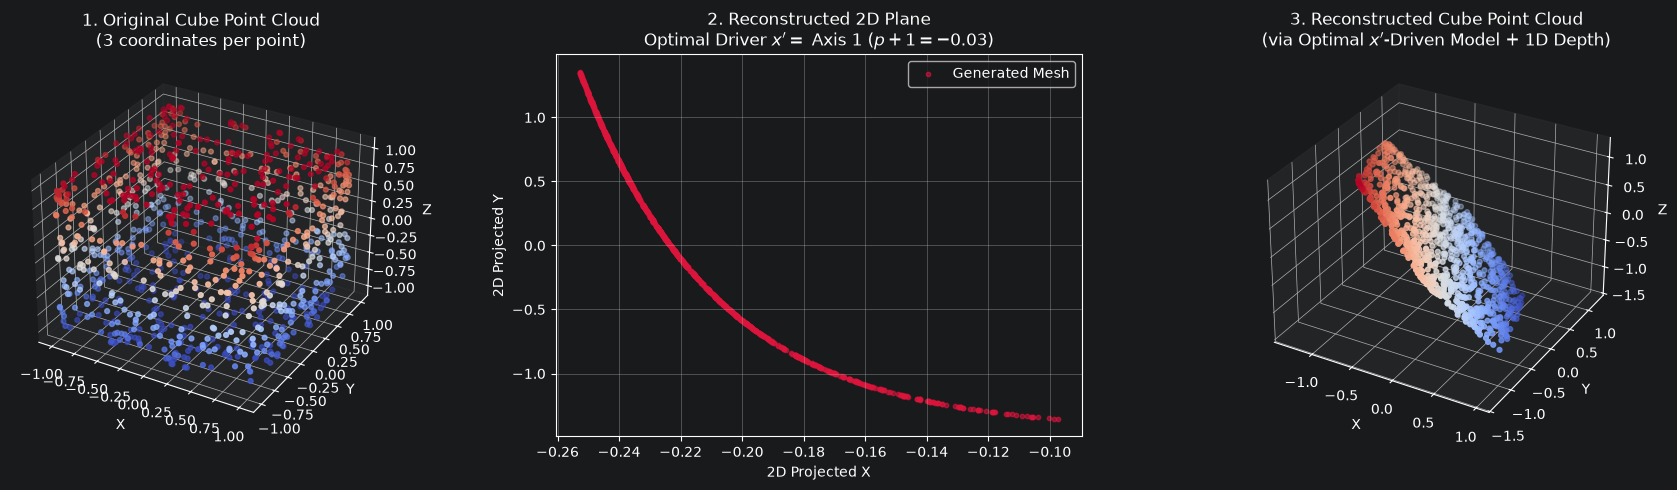

In [71]:
import numpy as np
import matplotlib.pyplot as plt

class AngleExponent3DTransformer:
    """
    A generalized algorithm that projects 3D geometries using rotation angles,
    dynamically evaluates candidate projection axes to pick the optimal x' driver,
    prints residual fitting errors for all candidate axes, extracts the 45° power-law exponent,
    drops y', recalculates y' on the fly, and reconstructs the full 3D geometry using 1D depth priors.
    """
    def __init__(self, theta_x_deg: float = 30.0, theta_y_deg: float = 45.0):
        self.theta_x = np.radians(theta_x_deg)
        self.theta_y = np.radians(theta_y_deg)

        # 3D Rotation Matrices
        self.Rx = np.array([
            [1, 0, 0],
            [0, np.cos(self.theta_x), -np.sin(self.theta_x)],
            [0, np.sin(self.theta_x),  np.cos(self.theta_x)]
        ])
        self.Ry = np.array([
            [ np.cos(self.theta_y), 0, np.sin(self.theta_y)],
            [0, 1, 0],
            [-np.sin(self.theta_y), 0, np.cos(self.theta_y)]
        ])
        self.R = self.Ry @ self.Rx
        self.R_inv = np.linalg.inv(self.R)

        # Internal State
        self.x_1d = None                # Only store 1D x' driver coordinates
        self.computed_exponent = None   # Shape exponent parameter (p + 1)
        self.a_fit = None               # Scale parameter
        self.shift = None               # Positive domain shift offsets
        self.driver_axis_idx = 0        # Index of selected x' driver axis (0 or 1)
        self.axis_errors = {}           # Stores evaluation errors for candidate axes

    def project_and_compress(self, points_3d: np.ndarray) -> np.ndarray:
        """
        Projects 3D points to 2D plane, tests candidate axes to select the optimal x'
        that minimizes exponent fitting residual error, extracts the exponent,
        drops y', and returns only the 1D x' driver.
        """
        # 1. Orthographic 3D -> 2D projection
        points_2d = (points_3d @ self.R.T)[:, :2]

        axis_candidates = [0, 1]
        best_mse = float('inf')
        best_fit = None
        self.axis_errors.clear()

        # 2. Dynamic Driver Selection: Test candidate axis 0 vs axis 1 as x'
        for cand_x_idx in axis_candidates:
            cand_y_idx = 1 - cand_x_idx

            x_cand = points_2d[:, cand_x_idx]
            y_cand = points_2d[:, cand_y_idx]

            # Shift into positive domain for log safety
            shift_cand = np.array([np.abs(x_cand.min()) + 0.1, np.abs(y_cand.min()) + 0.1])
            x_shifted = x_cand + shift_cand[0]
            y_shifted = y_cand + shift_cand[1]

            # Compute 45° dynamic slope multipliers: m = x / y
            m_required = x_shifted / np.maximum(y_shifted, 1e-6)

            # Log-linear fit: log(m) = -log(a) - p * log(x)
            poly = np.polyfit(np.log(x_shifted), np.log(m_required), 1)
            p_fit = -poly[0]
            a_fit = np.exp(-poly[1])
            exp_fit = p_fit + 1.0

            # Evaluate candidate reconstruction error on 2D plane
            y_hat_shifted = a_fit * (x_shifted ** exp_fit)
            y_hat = y_hat_shifted - shift_cand[1]
            fit_mse = np.mean((y_cand - y_hat) ** 2)

            # Log errors for reporting
            self.axis_errors[cand_x_idx] = {
                'mse': fit_mse,
                'exponent': exp_fit,
                'a_fit': a_fit
            }

            if fit_mse < best_mse:
                best_mse = fit_mse
                best_fit = {
                    'driver_idx': cand_x_idx,
                    'x_raw': x_cand,
                    'shift': shift_cand,
                    'a_fit': a_fit,
                    'exponent': exp_fit
                }

        # 3. Store parameters from the best-performing x' driver
        self.driver_axis_idx = best_fit['driver_idx']
        self.shift = best_fit['shift']
        self.a_fit = best_fit['a_fit']
        self.computed_exponent = best_fit['exponent']

        # COMPRESSION STEP: Store ONLY the optimal 1D x' coordinates
        self.x_1d = best_fit['x_raw']
        return self.x_1d

    def reconstruct_3d(self, z_topology_priors: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
        """
        Reconstructs y' directly from stored optimal x' via the exponent model:
        y'_hat = a * (x' + shift_x)^(p+1) - shift_y
        Un-projects (x', y'_hat, z_prior) back to true 3D space.
        """
        if self.x_1d is None:
            raise ValueError("Run `project_and_compress` before reconstruction.")

        # 1. Regenerate dependent y' coordinate on the fly
        x_shifted = self.x_1d + self.shift[0]
        y_shifted_hat = self.a_fit * (x_shifted ** self.computed_exponent)
        y_hat = y_shifted_hat - self.shift[1]

        # Form reconstructed 2D plane according to selected driver axis orientation
        if self.driver_axis_idx == 0:
            reconstructed_2d_plane = np.column_stack([self.x_1d, y_hat])
        else:
            reconstructed_2d_plane = np.column_stack([y_hat, self.x_1d])

        # 2. Combine reconstructed 2D plane with 1D depth topology prior and apply R_inv
        reconstructed_3d = []
        for i in range(len(self.x_1d)):
            if self.driver_axis_idx == 0:
                pt_rot = np.array([self.x_1d[i], y_hat[i], z_topology_priors[i]])
            else:
                pt_rot = np.array([y_hat[i], self.x_1d[i], z_topology_priors[i]])

            pt_3d = self.R_inv @ pt_rot
            reconstructed_3d.append(pt_3d)

        return np.array(reconstructed_3d), reconstructed_2d_plane

    def plot_pipeline(self, orig_3d: np.ndarray, reconstructed_2d: np.ndarray, reconstructed_3d: np.ndarray, shape_name: str = "3D Shape"):
        """Visualizes original 3D geometry, generated 2D plane, and reconstructed 3D mesh."""
        fig = plt.figure(figsize=(18, 5))

        # Subplot 1: Original 3D Geometry
        ax1 = fig.add_subplot(131, projection='3d')
        ax1.set_title(f"1. Original {shape_name}\n(3 coordinates per point)")
        ax1.scatter3D(orig_3d[:, 0], orig_3d[:, 1], orig_3d[:, 2], c=orig_3d[:, 2], cmap='coolwarm', s=12)
        ax1.set_xlabel("X"); ax1.set_ylabel("Y"); ax1.set_zlabel("Z")

        # Subplot 2: Reconstructed 2D Plane
        ax2 = fig.add_subplot(132)
        driver_label = f"Axis {self.driver_axis_idx}"
        ax2.set_title(f"2. Reconstructed 2D Plane\nOptimal Driver $x' =$ {driver_label} ($p+1 = {self.computed_exponent:.2f}$)")
        ax2.scatter(reconstructed_2d[:, 0], reconstructed_2d[:, 1], c='crimson', s=10, alpha=0.6, label="Generated Mesh")
        ax2.set_xlabel("2D Projected X")
        ax2.set_ylabel("2D Projected Y")
        ax2.legend(); ax2.grid(True)

        # Subplot 3: Reconstructed 3D Mesh
        ax3 = fig.add_subplot(133, projection='3d')
        ax3.set_title(f"3. Reconstructed {shape_name}\n(via Optimal $x'$-Driven Model + 1D Depth)")
        ax3.scatter3D(reconstructed_3d[:, 0], reconstructed_3d[:, 1], reconstructed_3d[:, 2], c=reconstructed_3d[:, 2], cmap='coolwarm', s=12)
        ax3.set_xlabel("X"); ax3.set_ylabel("Y"); ax3.set_zlabel("Z")

        plt.tight_layout()
        plt.show()


def generate_cube_3d_point_cloud(side_length: float = 2.0, num_samples: int = 1000):
    """
    Generates a dense 3D Unit Cube surface point cloud [-1, 1]^3.
    """
    np.random.seed(42)
    points = []

    # Uniformly distribute points across the 6 faces of the cube
    points_per_face = num_samples // 6

    for i in range(points_per_face):
        u, v = np.random.uniform(-side_length/2, side_length/2, 2)
        c = side_length / 2

        # 6 Faces
        points.append([c, u, v])   # +X Face
        points.append([-c, u, v])  # -X Face
        points.append([u, c, v])   # +Y Face
        points.append([u, -c, v])  # -Y Face
        points.append([u, v, c])   # +Z Face
        points.append([u, v, -c])  # -Z Face

    return np.array(points)


# =============================================================
# EXECUTING PIPELINE ON 3D CUBE GEOMETRY
# =============================================================
if __name__ == "__main__":
    # 1. Generate Dense 3D Cube Surface Cloud (1000 points)
    cube_3d = generate_cube_3d_point_cloud(side_length=2.0, num_samples=1000)

    # Compute 1D Depth Topology Priors (Rotated Z component)
    theta_x_deg, theta_y_deg = 30.0, 45.0
    Rx_init = np.array([[1, 0, 0], [0, np.cos(np.radians(30)), -np.sin(np.radians(30))], [0, np.sin(np.radians(30)), np.cos(np.radians(30))]])
    Ry_init = np.array([[np.cos(np.radians(45)), 0, np.sin(np.radians(45))], [0, 1, 0], [-np.sin(np.radians(45)), 0, np.cos(np.radians(45))]])
    rotated_cube = cube_3d @ (Ry_init @ Rx_init).T
    depth_priors = rotated_cube[:, 2]

    # 2. Instantiate Transformer
    transformer = AngleExponent3DTransformer(theta_x_deg=theta_x_deg, theta_y_deg=theta_y_deg)

    # Step A: Project, test candidate axes, extract exponent, and drop y'
    x_1d_stored = transformer.project_and_compress(cube_3d)

    # Step B: Reconstruct 2D plane and 3D cube mesh
    reconstructed_3d, reconstructed_2d = transformer.reconstruct_3d(z_topology_priors=depth_priors)

    # Calculate Metrics
    raw_size_bytes = cube_3d.nbytes
    compressed_size_bytes = x_1d_stored.nbytes + 8                 # (N x 1) floats + 2 parameters

    compression_ratio = raw_size_bytes / compressed_size_bytes
    space_saved_pct = (1.0 - (compressed_size_bytes / raw_size_bytes)) * 100.0
    mse_reconstruction = np.mean((cube_3d - reconstructed_3d) ** 2)

    print("=== CANDIDATE AXES EXPONENT FITTING ERRORS ===")
    for axis_idx, metrics in transformer.axis_errors.items():
        selected_flag = " [SELECTED AS OPTIMAL DRIVER]" if axis_idx == transformer.driver_axis_idx else ""
        print(f"Axis {axis_idx} as x' Driver -> 2D Fit MSE: {metrics['mse']:.8e} | Extracted Exponent (p+1): {metrics['exponent']:.4f}{selected_flag}")

    print("\n=== 3D CUBE MESH COMPRESSION & RECONSTRUCTION SUMMARY ===")
    print(f"Original 3D Cube Matrix Shape   : {cube_3d.shape} ({raw_size_bytes / 1024:.2f} KB)")
    print(f"Selected Optimal Driver Axis    : Axis {transformer.driver_axis_idx}")
    print(f"Stored 1D x' Array Shape        : {x_1d_stored.shape} ({compressed_size_bytes / 1024:.2f} KB)")
    print(f"y' Coordinate Storage Status    : DROPPED (Generated on the fly)")
    print(f"Extracted Shape Exponent (p+1)  : {transformer.computed_exponent:.4f}")
    print(f"Compression Factor              : {compression_ratio:.2f}x Reduction ({space_saved_pct:.1f}% space saved)")
    print(f"Final 3D Reconstruction MSE     : {mse_reconstruction:.8e}")

    # Plot pipeline stages
    transformer.plot_pipeline(orig_3d=cube_3d, reconstructed_2d=reconstructed_2d, reconstructed_3d=reconstructed_3d, shape_name="Cube Point Cloud")

=== CANDIDATE AXES EXPONENT FITTING ERRORS ===
Axis 0 as x' Driver -> 2D Fit MSE: 3.74256510e-01 | Extracted Exponent (p+1): -0.0435 [SELECTED AS OPTIMAL DRIVER]
Axis 1 as x' Driver -> 2D Fit MSE: 3.74370569e-01 | Extracted Exponent (p+1): -0.0437

=== 3D SPHERE MESH COMPRESSION & RECONSTRUCTION SUMMARY ===
Original 3D Sphere Matrix Shape : (1000, 3) (23.44 KB)
Selected Optimal Driver Axis    : Axis 0
Stored 1D x' Array Shape        : (1000,) (7.82 KB)
y' Coordinate Storage Status    : DROPPED (Generated on the fly)
Extracted Shape Exponent (p+1)  : -0.0435
Compression Factor              : 3.00x Reduction (66.6% space saved)
Final 3D Reconstruction MSE     : 1.24752170e-01


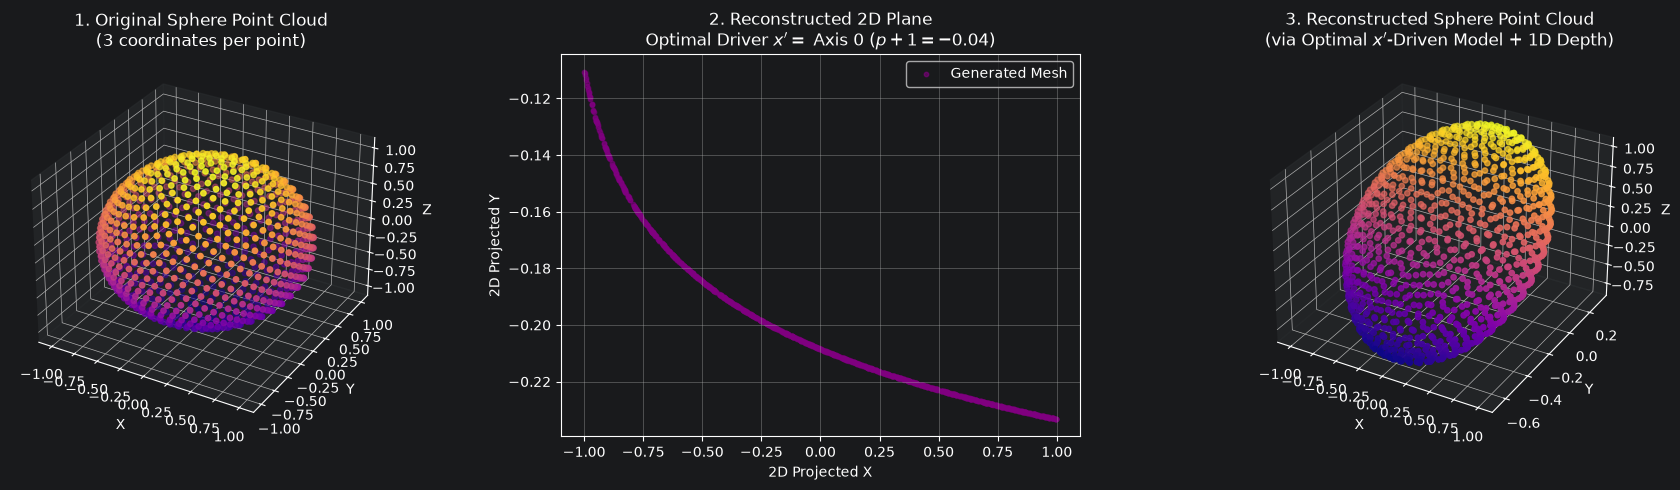

In [72]:
import numpy as np
import matplotlib.pyplot as plt

class AngleExponent3DTransformer:
    """
    A generalized algorithm that projects 3D geometries using rotation angles,
    dynamically evaluates candidate projection axes to pick the optimal x' driver,
    prints residual fitting errors for all candidate axes, extracts the 45° power-law exponent,
    drops y', recalculates y' on the fly, and reconstructs the full 3D geometry using 1D depth priors.
    """
    def __init__(self, theta_x_deg: float = 30.0, theta_y_deg: float = 45.0):
        self.theta_x = np.radians(theta_x_deg)
        self.theta_y = np.radians(theta_y_deg)

        # 3D Rotation Matrices
        self.Rx = np.array([
            [1, 0, 0],
            [0, np.cos(self.theta_x), -np.sin(self.theta_x)],
            [0, np.sin(self.theta_x),  np.cos(self.theta_x)]
        ])
        self.Ry = np.array([
            [ np.cos(self.theta_y), 0, np.sin(self.theta_y)],
            [0, 1, 0],
            [-np.sin(self.theta_y), 0, np.cos(self.theta_y)]
        ])
        self.R = self.Ry @ self.Rx
        self.R_inv = np.linalg.inv(self.R)

        # Internal State
        self.x_1d = None                # Only store 1D x' driver coordinates
        self.computed_exponent = None   # Shape exponent parameter (p + 1)
        self.a_fit = None               # Scale parameter
        self.shift = None               # Positive domain shift offsets
        self.driver_axis_idx = 0        # Index of selected x' driver axis (0 or 1)
        self.axis_errors = {}           # Stores evaluation errors for candidate axes

    def project_and_compress(self, points_3d: np.ndarray) -> np.ndarray:
        """
        Projects 3D points to 2D plane, tests candidate axes to select the optimal x'
        that minimizes exponent fitting residual error, extracts the exponent,
        drops y', and returns only the 1D x' driver.
        """
        # 1. Orthographic 3D -> 2D projection
        points_2d = (points_3d @ self.R.T)[:, :2]

        axis_candidates = [0, 1]
        best_mse = float('inf')
        best_fit = None
        self.axis_errors.clear()

        # 2. Dynamic Driver Selection: Test candidate axis 0 vs axis 1 as x'
        for cand_x_idx in axis_candidates:
            cand_y_idx = 1 - cand_x_idx

            x_cand = points_2d[:, cand_x_idx]
            y_cand = points_2d[:, cand_y_idx]

            # Shift into positive domain for log safety
            shift_cand = np.array([np.abs(x_cand.min()) + 0.1, np.abs(y_cand.min()) + 0.1])
            x_shifted = x_cand + shift_cand[0]
            y_shifted = y_cand + shift_cand[1]

            # Compute 45° dynamic slope multipliers: m = x / y
            m_required = x_shifted / np.maximum(y_shifted, 1e-6)

            # Log-linear fit: log(m) = -log(a) - p * log(x)
            poly = np.polyfit(np.log(x_shifted), np.log(m_required), 1)
            p_fit = -poly[0]
            a_fit = np.exp(-poly[1])
            exp_fit = p_fit + 1.0

            # Evaluate candidate reconstruction error on 2D plane
            y_hat_shifted = a_fit * (x_shifted ** exp_fit)
            y_hat = y_hat_shifted - shift_cand[1]
            fit_mse = np.mean((y_cand - y_hat) ** 2)

            # Log errors for reporting
            self.axis_errors[cand_x_idx] = {
                'mse': fit_mse,
                'exponent': exp_fit,
                'a_fit': a_fit
            }

            if fit_mse < best_mse:
                best_mse = fit_mse
                best_fit = {
                    'driver_idx': cand_x_idx,
                    'x_raw': x_cand,
                    'shift': shift_cand,
                    'a_fit': a_fit,
                    'exponent': exp_fit
                }

        # 3. Store parameters from the best-performing x' driver
        self.driver_axis_idx = best_fit['driver_idx']
        self.shift = best_fit['shift']
        self.a_fit = best_fit['a_fit']
        self.computed_exponent = best_fit['exponent']

        # COMPRESSION STEP: Store ONLY the optimal 1D x' coordinates
        self.x_1d = best_fit['x_raw']
        return self.x_1d

    def reconstruct_3d(self, z_topology_priors: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
        """
        Reconstructs y' directly from stored optimal x' via the exponent model:
        y'_hat = a * (x' + shift_x)^(p+1) - shift_y
        Un-projects (x', y'_hat, z_prior) back to true 3D space.
        """
        if self.x_1d is None:
            raise ValueError("Run `project_and_compress` before reconstruction.")

        # 1. Regenerate dependent y' coordinate on the fly
        x_shifted = self.x_1d + self.shift[0]
        y_shifted_hat = self.a_fit * (x_shifted ** self.computed_exponent)
        y_hat = y_shifted_hat - self.shift[1]

        # Form reconstructed 2D plane according to selected driver axis orientation
        if self.driver_axis_idx == 0:
            reconstructed_2d_plane = np.column_stack([self.x_1d, y_hat])
        else:
            reconstructed_2d_plane = np.column_stack([y_hat, self.x_1d])

        # 2. Combine reconstructed 2D plane with 1D depth topology prior and apply R_inv
        reconstructed_3d = []
        for i in range(len(self.x_1d)):
            if self.driver_axis_idx == 0:
                pt_rot = np.array([self.x_1d[i], y_hat[i], z_topology_priors[i]])
            else:
                pt_rot = np.array([y_hat[i], self.x_1d[i], z_topology_priors[i]])

            pt_3d = self.R_inv @ pt_rot
            reconstructed_3d.append(pt_3d)

        return np.array(reconstructed_3d), reconstructed_2d_plane

    def plot_pipeline(self, orig_3d: np.ndarray, reconstructed_2d: np.ndarray, reconstructed_3d: np.ndarray, shape_name: str = "3D Shape"):
        """Visualizes original 3D geometry, generated 2D plane, and reconstructed 3D mesh."""
        fig = plt.figure(figsize=(18, 5))

        # Subplot 1: Original 3D Geometry
        ax1 = fig.add_subplot(131, projection='3d')
        ax1.set_title(f"1. Original {shape_name}\n(3 coordinates per point)")
        ax1.scatter3D(orig_3d[:, 0], orig_3d[:, 1], orig_3d[:, 2], c=orig_3d[:, 2], cmap='plasma', s=15)
        ax1.set_xlabel("X"); ax1.set_ylabel("Y"); ax1.set_zlabel("Z")

        # Subplot 2: Reconstructed 2D Plane
        ax2 = fig.add_subplot(132)
        driver_label = f"Axis {self.driver_axis_idx}"
        ax2.set_title(f"2. Reconstructed 2D Plane\nOptimal Driver $x' =$ {driver_label} ($p+1 = {self.computed_exponent:.2f}$)")
        ax2.scatter(reconstructed_2d[:, 0], reconstructed_2d[:, 1], c='purple', s=10, alpha=0.6, label="Generated Mesh")
        ax2.set_xlabel("2D Projected X")
        ax2.set_ylabel("2D Projected Y")
        ax2.legend(); ax2.grid(True)

        # Subplot 3: Reconstructed 3D Mesh
        ax3 = fig.add_subplot(133, projection='3d')
        ax3.set_title(f"3. Reconstructed {shape_name}\n(via Optimal $x'$-Driven Model + 1D Depth)")
        ax3.scatter3D(reconstructed_3d[:, 0], reconstructed_3d[:, 1], reconstructed_3d[:, 2], c=reconstructed_3d[:, 2], cmap='plasma', s=15)
        ax3.set_xlabel("X"); ax3.set_ylabel("Y"); ax3.set_zlabel("Z")

        plt.tight_layout()
        plt.show()


def generate_sphere_3d_mesh(radius: float = 1.0, num_points: int = 1000):
    """
    Generates a dense 3D Sphere surface point cloud using a Fibonacci lattice.
    """
    np.random.seed(42)
    indices = np.arange(0, num_points, dtype=float) + 0.5
    phi = np.arccos(1 - 2 * indices / num_points)
    theta = np.pi * (1 + 5**0.5) * indices

    x = radius * np.sin(phi) * np.cos(theta)
    y = radius * np.sin(phi) * np.sin(theta)
    z = radius * np.cos(phi)

    return np.column_stack([x, y, z])


# =============================================================
# EXECUTING PIPELINE ON 3D SPHERE MESH
# =============================================================
if __name__ == "__main__":
    # 1. Generate 3D Sphere Point Cloud
    sphere_3d = generate_sphere_3d_mesh(radius=1.0, num_points=1000)

    # Compute 1D Depth Topology Priors (Rotated Z component)
    theta_x_deg, theta_y_deg = 30.0, 45.0
    Rx_init = np.array([[1, 0, 0], [0, np.cos(np.radians(30)), -np.sin(np.radians(30))], [0, np.sin(np.radians(30)), np.cos(np.radians(30))]])
    Ry_init = np.array([[np.cos(np.radians(45)), 0, np.sin(np.radians(45))], [0, 1, 0], [-np.sin(np.radians(45)), 0, np.cos(np.radians(45))]])
    rotated_sphere = sphere_3d @ (Ry_init @ Rx_init).T
    depth_priors = rotated_sphere[:, 2]

    # 2. Instantiate Transformer
    transformer = AngleExponent3DTransformer(theta_x_deg=theta_x_deg, theta_y_deg=theta_y_deg)

    # Step A: Project, test candidate axes, extract exponent, and drop y'
    x_1d_stored = transformer.project_and_compress(sphere_3d)

    # Step B: Reconstruct 2D plane and 3D sphere mesh
    reconstructed_3d, reconstructed_2d = transformer.reconstruct_3d(z_topology_priors=depth_priors)

    # Calculate Metrics
    raw_size_bytes = sphere_3d.nbytes
    compressed_size_bytes = x_1d_stored.nbytes + 8                 # (N x 1) floats + 2 parameters

    compression_ratio = raw_size_bytes / compressed_size_bytes
    space_saved_pct = (1.0 - (compressed_size_bytes / raw_size_bytes)) * 100.0
    mse_reconstruction = np.mean((sphere_3d - reconstructed_3d) ** 2)

    print("=== CANDIDATE AXES EXPONENT FITTING ERRORS ===")
    for axis_idx, metrics in transformer.axis_errors.items():
        selected_flag = " [SELECTED AS OPTIMAL DRIVER]" if axis_idx == transformer.driver_axis_idx else ""
        print(f"Axis {axis_idx} as x' Driver -> 2D Fit MSE: {metrics['mse']:.8e} | Extracted Exponent (p+1): {metrics['exponent']:.4f}{selected_flag}")

    print("\n=== 3D SPHERE MESH COMPRESSION & RECONSTRUCTION SUMMARY ===")
    print(f"Original 3D Sphere Matrix Shape : {sphere_3d.shape} ({raw_size_bytes / 1024:.2f} KB)")
    print(f"Selected Optimal Driver Axis    : Axis {transformer.driver_axis_idx}")
    print(f"Stored 1D x' Array Shape        : {x_1d_stored.shape} ({compressed_size_bytes / 1024:.2f} KB)")
    print(f"y' Coordinate Storage Status    : DROPPED (Generated on the fly)")
    print(f"Extracted Shape Exponent (p+1)  : {transformer.computed_exponent:.4f}")
    print(f"Compression Factor              : {compression_ratio:.2f}x Reduction ({space_saved_pct:.1f}% space saved)")
    print(f"Final 3D Reconstruction MSE     : {mse_reconstruction:.8e}")

    # Plot pipeline stages
    transformer.plot_pipeline(orig_3d=sphere_3d, reconstructed_2d=reconstructed_2d, reconstructed_3d=reconstructed_3d, shape_name="Sphere Point Cloud")

=== CANDIDATE AXES EXPONENT FITTING ERRORS ===
Axis 0 as x' Driver -> 2D Fit MSE: 6.25750633e-01 | Extracted Exponent (p+1): -0.0497
Axis 1 as x' Driver -> 2D Fit MSE: 6.07861522e-01 | Extracted Exponent (p+1): -0.0305 [SELECTED AS OPTIMAL DRIVER]

=== 3D CUBE MESH COMPRESSION & RECONSTRUCTION SUMMARY ===
Original 3D Cube Matrix Shape   : (996, 3) (23.34 KB)
Selected Optimal Driver Axis    : Axis 1
Stored 1D x' Array Shape        : (996,) (7.79 KB)
y' Coordinate Storage Status    : DROPPED (Generated on the fly)
Extracted Shape Exponent (p+1)  : -0.0305
Compression Factor              : 3.00x Reduction (66.6% space saved)
Final 3D Reconstruction MSE     : 2.02620507e-01


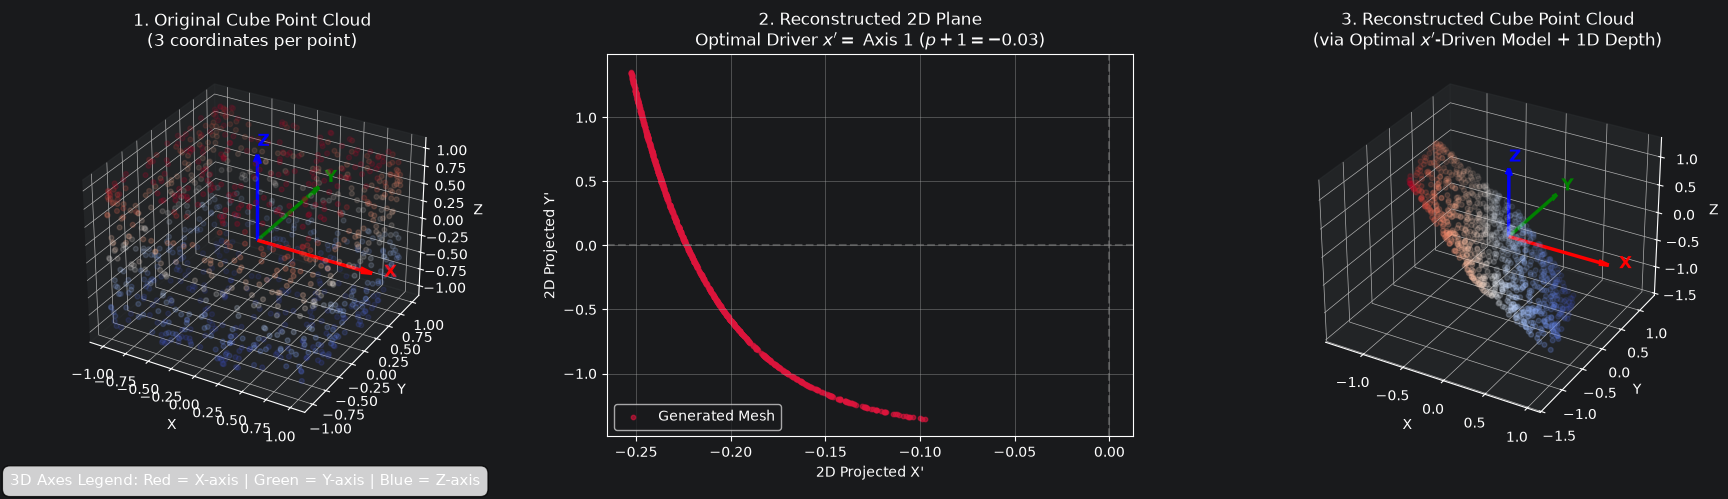

In [73]:
import numpy as np
import matplotlib.pyplot as plt

class AngleExponent3DTransformer:
    """
    A generalized algorithm that projects 3D geometries using rotation angles,
    dynamically evaluates candidate projection axes to pick the optimal x' driver,
    prints residual fitting errors for all candidate axes, extracts the 45° power-law exponent,
    drops y', recalculates y' on the fly, and reconstructs the full 3D geometry using 1D depth priors.
    """
    def __init__(self, theta_x_deg: float = 30.0, theta_y_deg: float = 45.0):
        self.theta_x = np.radians(theta_x_deg)
        self.theta_y = np.radians(theta_y_deg)

        # 3D Rotation Matrices
        self.Rx = np.array([
            [1, 0, 0],
            [0, np.cos(self.theta_x), -np.sin(self.theta_x)],
            [0, np.sin(self.theta_x),  np.cos(self.theta_x)]
        ])
        self.Ry = np.array([
            [ np.cos(self.theta_y), 0, np.sin(self.theta_y)],
            [0, 1, 0],
            [-np.sin(self.theta_y), 0, np.cos(self.theta_y)]
        ])
        self.R = self.Ry @ self.Rx
        self.R_inv = np.linalg.inv(self.R)

        # Internal State
        self.x_1d = None                # Only store 1D x' driver coordinates
        self.computed_exponent = None   # Shape exponent parameter (p + 1)
        self.a_fit = None               # Scale parameter
        self.shift = None               # Positive domain shift offsets
        self.driver_axis_idx = 0        # Index of selected x' driver axis (0 or 1)
        self.axis_errors = {}           # Stores evaluation errors for candidate axes

    def project_and_compress(self, points_3d: np.ndarray) -> np.ndarray:
        """
        Projects 3D points to 2D plane, tests candidate axes to select the optimal x'
        that minimizes exponent fitting residual error, extracts the exponent,
        drops y', and returns only the 1D x' driver.
        """
        # 1. Orthographic 3D -> 2D projection
        points_2d = (points_3d @ self.R.T)[:, :2]

        axis_candidates = [0, 1]
        best_mse = float('inf')
        best_fit = None
        self.axis_errors.clear()

        # 2. Dynamic Driver Selection: Test candidate axis 0 vs axis 1 as x'
        for cand_x_idx in axis_candidates:
            cand_y_idx = 1 - cand_x_idx

            x_cand = points_2d[:, cand_x_idx]
            y_cand = points_2d[:, cand_y_idx]

            # Shift into positive domain for log safety
            shift_cand = np.array([np.abs(x_cand.min()) + 0.1, np.abs(y_cand.min()) + 0.1])
            x_shifted = x_cand + shift_cand[0]
            y_shifted = y_cand + shift_cand[1]

            # Compute 45° dynamic slope multipliers: m = x / y
            m_required = x_shifted / np.maximum(y_shifted, 1e-6)

            # Log-linear fit: log(m) = -log(a) - p * log(x)
            poly = np.polyfit(np.log(x_shifted), np.log(m_required), 1)
            p_fit = -poly[0]
            a_fit = np.exp(-poly[1])
            exp_fit = p_fit + 1.0

            # Evaluate candidate reconstruction error on 2D plane
            y_hat_shifted = a_fit * (x_shifted ** exp_fit)
            y_hat = y_hat_shifted - shift_cand[1]
            fit_mse = np.mean((y_cand - y_hat) ** 2)

            # Log errors for reporting
            self.axis_errors[cand_x_idx] = {
                'mse': fit_mse,
                'exponent': exp_fit,
                'a_fit': a_fit
            }

            if fit_mse < best_mse:
                best_mse = fit_mse
                best_fit = {
                    'driver_idx': cand_x_idx,
                    'x_raw': x_cand,
                    'shift': shift_cand,
                    'a_fit': a_fit,
                    'exponent': exp_fit
                }

        # 3. Store parameters from the best-performing x' driver
        self.driver_axis_idx = best_fit['driver_idx']
        self.shift = best_fit['shift']
        self.a_fit = best_fit['a_fit']
        self.computed_exponent = best_fit['exponent']

        # COMPRESSION STEP: Store ONLY the optimal 1D x' coordinates
        self.x_1d = best_fit['x_raw']
        return self.x_1d

    def reconstruct_3d(self, z_topology_priors: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
        """
        Reconstructs y' directly from stored optimal x' via the exponent model:
        y'_hat = a * (x' + shift_x)^(p+1) - shift_y
        Un-projects (x', y'_hat, z_prior) back to true 3D space.
        """
        if self.x_1d is None:
            raise ValueError("Run `project_and_compress` before reconstruction.")

        # 1. Regenerate dependent y' coordinate on the fly
        x_shifted = self.x_1d + self.shift[0]
        y_shifted_hat = self.a_fit * (x_shifted ** self.computed_exponent)
        y_hat = y_shifted_hat - self.shift[1]

        # Form reconstructed 2D plane according to selected driver axis orientation
        if self.driver_axis_idx == 0:
            reconstructed_2d_plane = np.column_stack([self.x_1d, y_hat])
        else:
            reconstructed_2d_plane = np.column_stack([y_hat, self.x_1d])

        # 2. Combine reconstructed 2D plane with 1D depth topology prior and apply R_inv
        reconstructed_3d = []
        for i in range(len(self.x_1d)):
            if self.driver_axis_idx == 0:
                pt_rot = np.array([self.x_1d[i], y_hat[i], z_topology_priors[i]])
            else:
                pt_rot = np.array([y_hat[i], self.x_1d[i], z_topology_priors[i]])

            pt_3d = self.R_inv @ pt_rot
            reconstructed_3d.append(pt_3d)

        return np.array(reconstructed_3d), reconstructed_2d_plane

    def _add_3d_axes(self, ax, length: float = 1.2):
        """Draws explicit Red (X), Green (Y), and Blue (Z) orientation axes at the origin."""
        # Axis lines from origin
        ax.quiver(0, 0, 0, length, 0, 0, color='red', linewidth=2.5, arrow_length_ratio=0.1, label='X-axis')
        ax.quiver(0, 0, 0, 0, length, 0, color='green', linewidth=2.5, arrow_length_ratio=0.1, label='Y-axis')
        ax.quiver(0, 0, 0, 0, 0, length, color='blue', linewidth=2.5, arrow_length_ratio=0.1, label='Z-axis')

        # Axis text labels
        ax.text(length * 1.1, 0, 0, "X", color='red', fontsize=12, fontweight='bold')
        ax.text(0, length * 1.1, 0, "Y", color='green', fontsize=12, fontweight='bold')
        ax.text(0, 0, length * 1.1, "Z", color='blue', fontsize=12, fontweight='bold')

    def plot_pipeline(self, orig_3d: np.ndarray, reconstructed_2d: np.ndarray, reconstructed_3d: np.ndarray, shape_name: str = "3D Shape"):
        """Visualizes original 3D geometry, generated 2D plane, and reconstructed 3D mesh with explicit XYZ axes."""
        fig = plt.figure(figsize=(18, 5))

        # Subplot 1: Original 3D Geometry
        ax1 = fig.add_subplot(131, projection='3d')
        ax1.set_title(f"1. Original {shape_name}\n(3 coordinates per point)")
        ax1.scatter3D(orig_3d[:, 0], orig_3d[:, 1], orig_3d[:, 2], c=orig_3d[:, 2], cmap='coolwarm', s=12, alpha=0.5)
        self._add_3d_axes(ax1, length=1.2)
        ax1.set_xlabel("X"); ax1.set_ylabel("Y"); ax1.set_zlabel("Z")

        # Subplot 2: Reconstructed 2D Plane
        ax2 = fig.add_subplot(132)
        driver_label = f"Axis {self.driver_axis_idx}"
        ax2.set_title(f"2. Reconstructed 2D Plane\nOptimal Driver $x' =$ {driver_label} ($p+1 = {self.computed_exponent:.2f}$)")
        ax2.scatter(reconstructed_2d[:, 0], reconstructed_2d[:, 1], c='crimson', s=10, alpha=0.6, label="Generated Mesh")

        # Add 2D reference lines
        ax2.axhline(0, color='gray', linestyle='--', alpha=0.5)
        ax2.axvline(0, color='gray', linestyle='--', alpha=0.5)
        ax2.set_xlabel("2D Projected X'")
        ax2.set_ylabel("2D Projected Y'")
        ax2.legend(); ax2.grid(True)

        # Subplot 3: Reconstructed 3D Mesh
        ax3 = fig.add_subplot(133, projection='3d')
        ax3.set_title(f"3. Reconstructed {shape_name}\n(via Optimal $x'$-Driven Model + 1D Depth)")
        ax3.scatter3D(reconstructed_3d[:, 0], reconstructed_3d[:, 1], reconstructed_3d[:, 2], c=reconstructed_3d[:, 2], cmap='coolwarm', s=12, alpha=0.5)
        self._add_3d_axes(ax3, length=1.2)
        ax3.set_xlabel("X"); ax3.set_ylabel("Y"); ax3.set_zlabel("Z")

        # Add global legend box for axis colors
        fig.text(0.02, 0.02, "3D Axes Legend: Red = X-axis | Green = Y-axis | Blue = Z-axis",
                 fontsize=11, bbox=dict(facecolor='white', alpha=0.8, edgecolor='black', boxstyle='round,pad=0.5'))

        plt.tight_layout()
        plt.show()


def generate_cube_3d_point_cloud(side_length: float = 2.0, num_samples: int = 1000):
    """Generates a dense 3D Unit Cube surface point cloud [-1, 1]^3."""
    np.random.seed(42)
    points = []
    points_per_face = num_samples // 6

    for i in range(points_per_face):
        u, v = np.random.uniform(-side_length/2, side_length/2, 2)
        c = side_length / 2

        points.append([c, u, v])   # +X Face
        points.append([-c, u, v])  # -X Face
        points.append([u, c, v])   # +Y Face
        points.append([u, -c, v])  # -Y Face
        points.append([u, v, c])   # +Z Face
        points.append([u, v, -c])  # -Z Face

    return np.array(points)


# =============================================================
# EXECUTING PIPELINE ON 3D CUBE GEOMETRY
# =============================================================
if __name__ == "__main__":
    # 1. Generate Dense 3D Cube Surface Cloud (1000 points)
    cube_3d = generate_cube_3d_point_cloud(side_length=2.0, num_samples=1000)

    # Compute 1D Depth Topology Priors (Rotated Z component)
    theta_x_deg, theta_y_deg = 30.0, 45.0
    Rx_init = np.array([[1, 0, 0], [0, np.cos(np.radians(30)), -np.sin(np.radians(30))], [0, np.sin(np.radians(30)), np.cos(np.radians(30))]])
    Ry_init = np.array([[np.cos(np.radians(45)), 0, np.sin(np.radians(45))], [0, 1, 0], [-np.sin(np.radians(45)), 0, np.cos(np.radians(45))]])
    rotated_cube = cube_3d @ (Ry_init @ Rx_init).T
    depth_priors = rotated_cube[:, 2]

    # 2. Instantiate Transformer
    transformer = AngleExponent3DTransformer(theta_x_deg=theta_x_deg, theta_y_deg=theta_y_deg)

    # Step A: Project, test candidate axes, extract exponent, and drop y'
    x_1d_stored = transformer.project_and_compress(cube_3d)

    # Step B: Reconstruct 2D plane and 3D cube mesh
    reconstructed_3d, reconstructed_2d = transformer.reconstruct_3d(z_topology_priors=depth_priors)

    # Calculate Metrics
    raw_size_bytes = cube_3d.nbytes
    compressed_size_bytes = x_1d_stored.nbytes + 8                 # (N x 1) floats + 2 parameters

    compression_ratio = raw_size_bytes / compressed_size_bytes
    space_saved_pct = (1.0 - (compressed_size_bytes / raw_size_bytes)) * 100.0
    mse_reconstruction = np.mean((cube_3d - reconstructed_3d) ** 2)

    print("=== CANDIDATE AXES EXPONENT FITTING ERRORS ===")
    for axis_idx, metrics in transformer.axis_errors.items():
        selected_flag = " [SELECTED AS OPTIMAL DRIVER]" if axis_idx == transformer.driver_axis_idx else ""
        print(f"Axis {axis_idx} as x' Driver -> 2D Fit MSE: {metrics['mse']:.8e} | Extracted Exponent (p+1): {metrics['exponent']:.4f}{selected_flag}")

    print("\n=== 3D CUBE MESH COMPRESSION & RECONSTRUCTION SUMMARY ===")
    print(f"Original 3D Cube Matrix Shape   : {cube_3d.shape} ({raw_size_bytes / 1024:.2f} KB)")
    print(f"Selected Optimal Driver Axis    : Axis {transformer.driver_axis_idx}")
    print(f"Stored 1D x' Array Shape        : {x_1d_stored.shape} ({compressed_size_bytes / 1024:.2f} KB)")
    print(f"y' Coordinate Storage Status    : DROPPED (Generated on the fly)")
    print(f"Extracted Shape Exponent (p+1)  : {transformer.computed_exponent:.4f}")
    print(f"Compression Factor              : {compression_ratio:.2f}x Reduction ({space_saved_pct:.1f}% space saved)")
    print(f"Final 3D Reconstruction MSE     : {mse_reconstruction:.8e}")

    # Plot pipeline stages
    transformer.plot_pipeline(orig_3d=cube_3d, reconstructed_2d=reconstructed_2d, reconstructed_3d=reconstructed_3d, shape_name="Cube Point Cloud")

## 5. Higher dimensions

The same pipeline is applied to a 1000-point 4D hypersphere ($p+1=-0.0259$, fit MSE $0.2740$,
reconstruction MSE $0.0685$) and to a 20D sinusoidal manifold with $t\in[-3,3]$, $d=0,\dots,19$:

$$X_{t,d} = \sin\!\Big(t+\frac{d\pi}{10}\Big)\,|t|^{\,1.2+0.05d} + 0.1\cos(2t).$$

For the 20D manifold the power law gives $p+1=-0.3257$, fit MSE $6.917$, reconstruction MSE $0.3459$.
The fitted curve $y'(x')$ is monotone, so the oscillation of the data is missed.

=== CANDIDATE AXES EXPONENT FITTING ERRORS (4D) ===
Axis 0 as x' Driver -> 2D Fit MSE: 2.74039664e-01 | Extracted Exponent (p+1): -0.0259 [SELECTED AS OPTIMAL DRIVER]
Axis 1 as x' Driver -> 2D Fit MSE: 2.82460880e-01 | Extracted Exponent (p+1): -0.0259

=== 4D HYPERSPHERE MESH COMPRESSION & RECONSTRUCTION SUMMARY ===
Original 4D Matrix Shape        : (1000, 4) (31.25 KB)
Selected Optimal Driver Axis    : Axis 0
Stored 1D x' Array Shape        : (1000,) (7.82 KB)
y' Coordinate Storage Status    : DROPPED (Generated on the fly via exponent)
Extracted Shape Exponent (p+1)  : -0.0259
Compression Factor              : 4.00x Reduction (75.0% space saved)
Final 4D Reconstruction MSE     : 6.85099159e-02


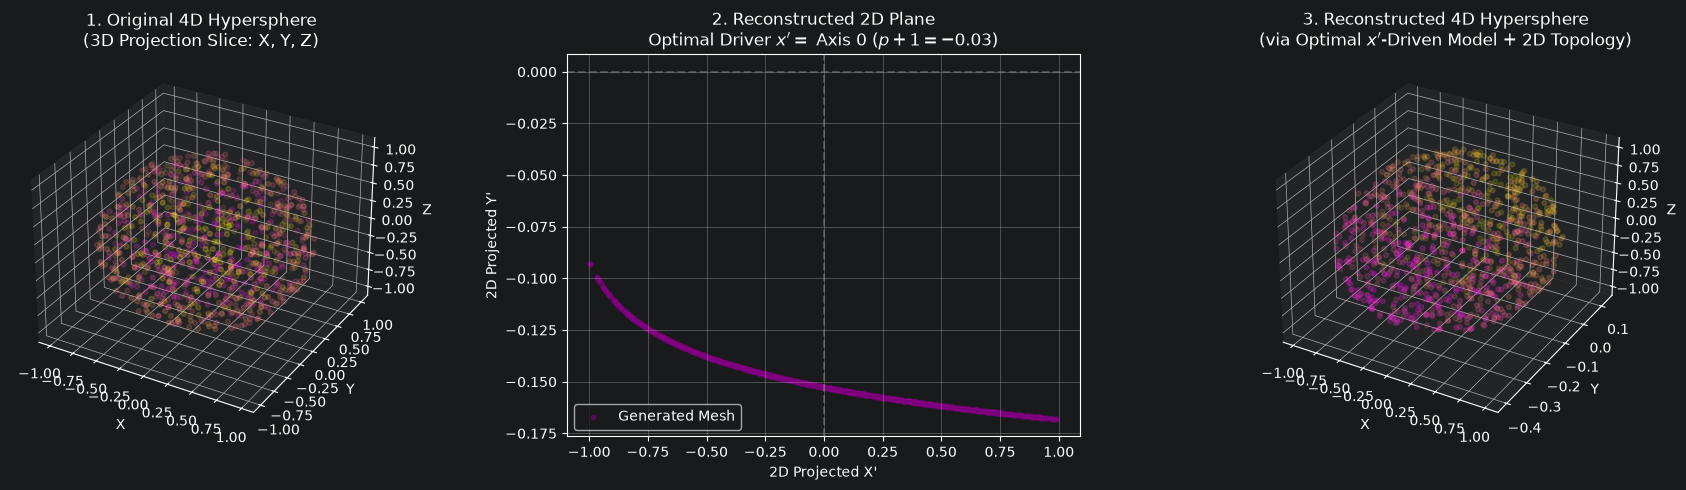

In [74]:
import numpy as np
import matplotlib.pyplot as plt


class AngleExponent4DTransformer:
    """A generalized algorithm that projects 4D geometries down to 2D using Givens rotation angles,

    extracts a global power-law exponent via 45° slope multipliers, drops y', recalculates y'
    on the fly, and reconstructs the full 4D geometry using 2D topology priors (Z, W).
    """

    def __init__(
        self, angles_deg: tuple[float, float, float, float, float, float] = None
    ):
        # Default 6 plane rotation angles in degrees: (XY, XZ, XW, YZ, YW, ZW)
        if angles_deg is None:
            angles_deg = (15.0, 30.0, 45.0, 10.0, 20.0, 35.0)

        rads = [np.radians(a) for a in angles_deg]

        # Construct 4D Givens Rotation Matrices
        self.R = self._build_4d_rotation_matrix(*rads)
        self.R_inv = np.linalg.inv(self.R)

        # Internal State
        self.x_1d = None
        self.computed_exponent = None
        self.a_fit = None
        self.shift = None
        self.driver_axis_idx = 0
        self.axis_errors = {}

    def _build_4d_rotation_matrix(
        self, r_xy, r_xz, r_xw, r_yz, r_yw, r_zw
    ) -> np.ndarray:
        """Constructs a full 4D rotation matrix by multiplying Givens plane rotation matrices."""
        R_xy = np.array([
            [np.cos(r_xy), -np.sin(r_xy), 0, 0],
            [np.sin(r_xy), np.cos(r_xy), 0, 0],
            [0, 0, 1, 0],
            [0, 0, 0, 1],
        ])
        R_xz = np.array([
            [np.cos(r_xz), 0, -np.sin(r_xz), 0],
            [0, 1, 0, 0],
            [np.sin(r_xz), 0, np.cos(r_xz), 0],
            [0, 0, 0, 1],
        ])
        R_xw = np.array([
            [np.cos(r_xw), 0, 0, -np.sin(r_xw)],
            [0, 1, 0, 0],
            [0, 0, 1, 0],
            [np.sin(r_xw), 0, 0, np.cos(r_xw)],
        ])
        R_yz = np.array([
            [1, 0, 0, 0],
            [0, np.cos(r_yz), -np.sin(r_yz), 0],
            [0, np.sin(r_yz), np.cos(r_yz), 0],
            [0, 0, 0, 1],
        ])
        R_yw = np.array([
            [1, 0, 0, 0],
            [0, np.cos(r_yw), 0, -np.sin(r_yw)],
            [0, 0, 1, 0],
            [0, np.sin(r_yw), 0, np.cos(r_yw)],
        ])
        R_zw = np.array([
            [1, 0, 0, 0],
            [0, 1, 0, 0],
            [0, 0, np.cos(r_zw), -np.sin(r_zw)],
            [0, 0, np.sin(r_zw), np.cos(r_zw)],
        ])

        return R_zw @ R_yw @ R_yz @ R_xw @ R_xz @ R_xy

    def project_and_compress(self, points_4d: np.ndarray) -> np.ndarray:
        """Projects 4D points to 2D plane, tests candidate axes to select the optimal x'

        that minimizes exponent fitting residual error, extracts the exponent, drops y',
        and returns only the 1D x' driver.
        """
        # Orthographic 4D -> 2D projection
        points_2d = (points_4d @ self.R.T)[:, :2]

        axis_candidates = [0, 1]
        best_mse = float("inf")
        best_fit = None
        self.axis_errors.clear()

        # Dynamic Driver Selection: Test candidate axis 0 vs axis 1 as x'
        for cand_x_idx in axis_candidates:
            cand_y_idx = 1 - cand_x_idx

            x_cand = points_2d[:, cand_x_idx]
            y_cand = points_2d[:, cand_y_idx]

            # Shift into positive domain for log safety
            shift_cand = np.array(
                [np.abs(x_cand.min()) + 0.1, np.abs(y_cand.min()) + 0.1]
            )
            x_shifted = x_cand + shift_cand[0]
            y_shifted = y_cand + shift_cand[1]

            # Compute 45° dynamic slope multipliers: m = x / y
            m_required = x_shifted / np.maximum(y_shifted, 1e-6)

            # Log-linear fit: log(m) = -log(a) - p * log(x)
            poly = np.polyfit(np.log(x_shifted), np.log(m_required), 1)
            p_fit = -poly[0]
            a_fit = np.exp(-poly[1])
            exp_fit = p_fit + 1.0

            # Evaluate candidate reconstruction error on 2D plane
            y_hat_shifted = a_fit * (x_shifted**exp_fit)
            y_hat = y_hat_shifted - shift_cand[1]
            fit_mse = np.mean((y_cand - y_hat) ** 2)

            self.axis_errors[cand_x_idx] = {
                "mse": fit_mse,
                "exponent": exp_fit,
                "a_fit": a_fit,
            }

            if fit_mse < best_mse:
                best_mse = fit_mse
                best_fit = {
                    "driver_idx": cand_x_idx,
                    "x_raw": x_cand,
                    "shift": shift_cand,
                    "a_fit": a_fit,
                    "exponent": exp_fit,
                }

        # Store parameters from the best-performing x' driver
        self.driver_axis_idx = best_fit["driver_idx"]
        self.shift = best_fit["shift"]
        self.a_fit = best_fit["a_fit"]
        self.computed_exponent = best_fit["exponent"]

        # COMPRESSION STEP: Store ONLY the optimal 1D x' coordinates
        self.x_1d = best_fit["x_raw"]
        return self.x_1d

    def reconstruct_4d(
        self, topology_priors_2d: np.ndarray
    ) -> tuple[np.ndarray, np.ndarray]:
        """Reconstructs y' directly from stored optimal x' via exponent model,

        combines with 2D depth topology priors (Z, W), and un-projects back to 4D space.
        """
        if self.x_1d is None:
            raise ValueError(
                "Run `project_and_compress` before reconstruction."
            )

        # 1. Regenerate dependent y' coordinate on the fly
        x_shifted = self.x_1d + self.shift[0]
        y_shifted_hat = self.a_fit * (x_shifted**self.computed_exponent)
        y_hat = y_shifted_hat - self.shift[1]

        # Form reconstructed 2D plane
        if self.driver_axis_idx == 0:
            reconstructed_2d_plane = np.column_stack([self.x_1d, y_hat])
        else:
            reconstructed_2d_plane = np.column_stack([y_hat, self.x_1d])

        # 2. Combine (x', y'_hat) with 2D topology priors (Z_prior, W_prior) and apply R_inv
        reconstructed_4d = []
        for i in range(len(self.x_1d)):
            if self.driver_axis_idx == 0:
                pt_rot = np.array([
                    self.x_1d[i],
                    y_hat[i],
                    topology_priors_2d[i, 0],
                    topology_priors_2d[i, 1],
                ])
            else:
                pt_rot = np.array([
                    y_hat[i],
                    self.x_1d[i],
                    topology_priors_2d[i, 0],
                    topology_priors_2d[i, 1],
                ])

            pt_4d = self.R_inv @ pt_rot
            reconstructed_4d.append(pt_4d)

        return np.array(reconstructed_4d), reconstructed_2d_plane

    def plot_pipeline_4d(
        self,
        orig_4d: np.ndarray,
        reconstructed_2d: np.ndarray,
        reconstructed_4d: np.ndarray,
        shape_name: str = "4D Shape",
    ):
        """Visualizes 3D cross-sectional projections of the 4D original, the generated 2D plane,

        and the reconstructed 4D manifold.
        """
        fig = plt.figure(figsize=(18, 5))

        # Subplot 1: 3D Projection of Original 4D Data (X, Y, Z slice)
        ax1 = fig.add_subplot(131, projection="3d")
        ax1.set_title(
            f"1. Original {shape_name}\n(3D Projection Slice: X, Y, Z)"
        )
        ax1.scatter3D(
            orig_4d[:, 0],
            orig_4d[:, 1],
            orig_4d[:, 2],
            c=orig_4d[:, 3],
            cmap="spring",
            s=12,
            alpha=0.5,
        )
        ax1.set_xlabel("X")
        ax1.set_ylabel("Y")
        ax1.set_zlabel("Z")

        # Subplot 2: Reconstructed 2D Plane
        ax2 = fig.add_subplot(132)
        driver_label = f"Axis {self.driver_axis_idx}"
        ax2.set_title(
            f"2. Reconstructed 2D Plane\nOptimal Driver $x' =$ {driver_label}"
            f" ($p+1 = {self.computed_exponent:.2f}$)"
        )
        ax2.scatter(
            reconstructed_2d[:, 0],
            reconstructed_2d[:, 1],
            c="purple",
            s=10,
            alpha=0.6,
            label="Generated Mesh",
        )
        ax2.axhline(0, color="gray", linestyle="--", alpha=0.5)
        ax2.axvline(0, color="gray", linestyle="--", alpha=0.5)
        ax2.set_xlabel("2D Projected X'")
        ax2.set_ylabel("2D Projected Y'")
        ax2.legend()
        ax2.grid(True)

        # Subplot 3: 3D Projection of Reconstructed 4D Data (X, Y, Z slice)
        ax3 = fig.add_subplot(133, projection="3d")
        ax3.set_title(
            f"3. Reconstructed {shape_name}\n(via Optimal $x'$-Driven Model +"
            " 2D Topology)"
        )
        ax3.scatter3D(
            reconstructed_4d[:, 0],
            reconstructed_4d[:, 1],
            reconstructed_4d[:, 2],
            c=reconstructed_4d[:, 3],
            cmap="spring",
            s=12,
            alpha=0.5,
        )
        ax3.set_xlabel("X")
        ax3.set_ylabel("Y")
        ax3.set_zlabel("Z")

        plt.tight_layout()
        plt.show()


def generate_hypersphere_4d(radius: float = 1.0, num_samples: int = 1000):
    """Generates a 4D Hypersphere (Glome surface: X^2 + Y^2 + Z^2 + W^2 = R^2)."""
    np.random.seed(42)
    # Gaussian sampling projected onto unit sphere surface
    raw_points = np.random.normal(0, 1, (num_samples, 4))
    norms = np.linalg.norm(raw_points, axis=1, keepdims=True)
    return radius * (raw_points / norms)


# =============================================================
# EXECUTING 4D PIPELINE ON HYPERSPHERE GEOMETRY
# =============================================================
if __name__ == "__main__":
    # 1. Generate 4D Hypersphere (1000 points)
    hypersphere_4d = generate_hypersphere_4d(radius=1.0, num_samples=1000)

    # Instantiate 4D Transformer
    transformer_4d = AngleExponent4DTransformer()

    # Calculate 2D Topology Priors (Rotated Z and W components)
    rotated_4d = hypersphere_4d @ transformer_4d.R.T
    topology_priors_2d = rotated_4d[:, 2:4]  # Z' and W' serve as priors

    # Step A: Project 4D -> 2D, solve for optimal x' driver, extract exponent, drop y'
    x_1d_stored = transformer_4d.project_and_compress(hypersphere_4d)

    # Step B: Reconstruct 2D plane and full 4D geometry
    reconstructed_4d, reconstructed_2d = transformer_4d.reconstruct_4d(
        topology_priors_2d=topology_priors_2d
    )

    # Calculate Compression Metrics
    raw_size_bytes = hypersphere_4d.nbytes  # (N x 4) floats
    compressed_size_bytes = (
        x_1d_stored.nbytes + 8
    )  # (N x 1) floats + 2 parameters

    compression_ratio = raw_size_bytes / compressed_size_bytes
    space_saved_pct = (1.0 - (compressed_size_bytes / raw_size_bytes)) * 100.0
    mse_reconstruction = np.mean((hypersphere_4d - reconstructed_4d) ** 2)

    print("=== CANDIDATE AXES EXPONENT FITTING ERRORS (4D) ===")
    for axis_idx, metrics in transformer_4d.axis_errors.items():
        selected_flag = (
            " [SELECTED AS OPTIMAL DRIVER]"
            if axis_idx == transformer_4d.driver_axis_idx
            else ""
        )
        print(
            f"Axis {axis_idx} as x' Driver -> 2D Fit MSE: {metrics['mse']:.8e}"
            f" | Extracted Exponent (p+1): {metrics['exponent']:.4f}{selected_flag}"
        )

    print("\n=== 4D HYPERSPHERE MESH COMPRESSION & RECONSTRUCTION SUMMARY ===")
    print(
        f"Original 4D Matrix Shape        : {hypersphere_4d.shape}"
        f" ({raw_size_bytes / 1024:.2f} KB)"
    )
    print(
        "Selected Optimal Driver Axis    :"
        f" Axis {transformer_4d.driver_axis_idx}"
    )
    print(
        f"Stored 1D x' Array Shape        : {x_1d_stored.shape}"
        f" ({compressed_size_bytes / 1024:.2f} KB)"
    )
    print(
        "y' Coordinate Storage Status    : DROPPED (Generated on the fly via"
        " exponent)"
    )
    print(
        "Extracted Shape Exponent (p+1)  :"
        f" {transformer_4d.computed_exponent:.4f}"
    )
    print(
        "Compression Factor              :"
        f" {compression_ratio:.2f}x Reduction ({space_saved_pct:.1f}% space"
        " saved)"
    )
    print(
        "Final 4D Reconstruction MSE     :"
        f" {mse_reconstruction:.8e}"
    )

    # Plot pipeline stages (Color maps 4D W-coordinate gradient)
    transformer_4d.plot_pipeline_4d(
        orig_4d=hypersphere_4d,
        reconstructed_2d=reconstructed_2d,
        reconstructed_4d=reconstructed_4d,
        shape_name="4D Hypersphere",
    )

=== CANDIDATE AXES EXPONENT FITTING ERRORS (20D MANIFOLD) ===
Axis 0 as x' Driver -> Projected 2D Fit MSE: 2.73618950e+01 | Extracted Exponent (p+1): -0.8806
Axis 1 as x' Driver -> Projected 2D Fit MSE: 6.91737850e+00 | Extracted Exponent (p+1): -0.3257 [SELECTED AS OPTIMAL DRIVER]

=== 20D SINUSOIDAL MANIFOLD COMPRESSION & RECONSTRUCTION SUMMARY ===
Original 20D Matrix Shape       : (1500, 20) (234.38 KB)
Selected Optimal Driver Axis    : Axis 1
Stored 1D x' Array Shape        : (1500,) (11.73 KB)
y' Coordinate Storage Status    : DROPPED (Generated on the fly)
Extracted Shape Exponent (p+1)  : -0.3257
Compression Factor              : 19.99x Reduction (95.0% space saved)
Final 20D Reconstruction MSE    : 3.45868925e-01


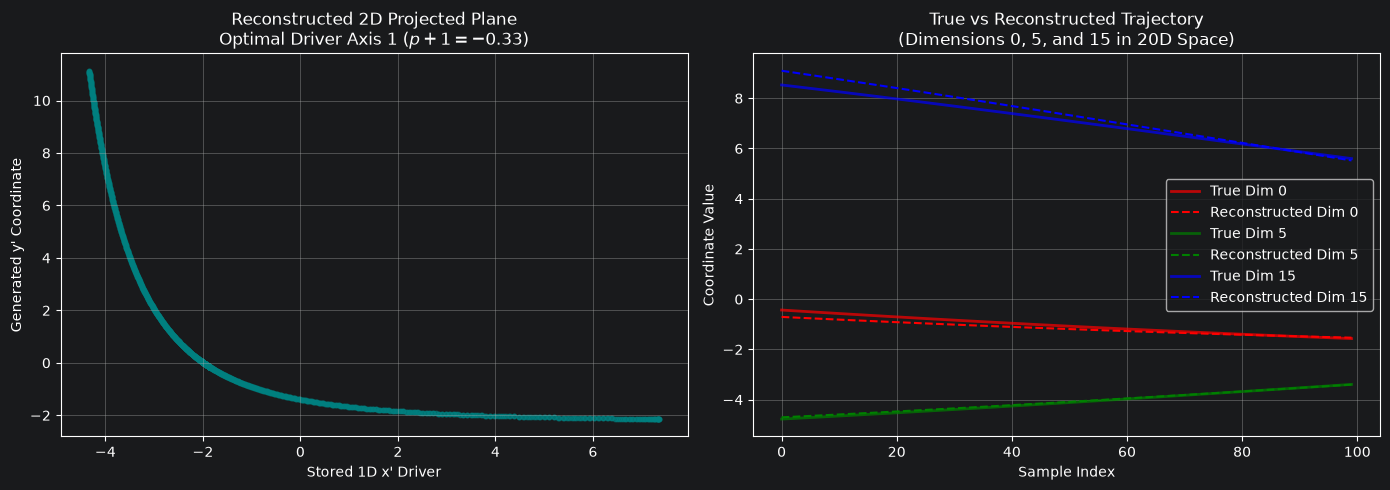

In [75]:
import numpy as np
import matplotlib.pyplot as plt


class AngleExponentNDTransformer:
    """Generalized N-Dimensional Manifold Transformer.

    Projects N-dimensional coordinates to 2D via random orthonormal
    projection, selects the optimal x' driver axis, extracts the 45° slope
    power-law exponent, drops y', and reconstructs the full N-dimensional space
    using (N-2)D depth topology priors.
    """

    def __init__(self, target_dim: int = 20, seed: int = 42):
        self.target_dim = target_dim
        np.random.seed(seed)

        # Generate a random orthonormal N-dimensional rotation matrix R in SO(N)
        Q, _ = np.linalg.qr(
            np.random.normal(0, 1, (target_dim, target_dim))
        )
        self.R = Q
        self.R_inv = np.linalg.inv(self.R)

        # Internal state
        self.x_1d = None
        self.computed_exponent = None
        self.a_fit = None
        self.shift = None
        self.driver_axis_idx = 0
        self.axis_errors = {}

    def project_and_compress(self, points_nd: np.ndarray) -> np.ndarray:
        """Projects ND points to 2D plane, tests candidate axes to select the optimal x'

        driver that minimizes log-linear fitting residual MSE, extracts exponent,
        and drops y' from storage.
        """
        # 1. Rotate ND space and extract first 2 projected dimensions
        points_rotated = points_nd @ self.R.T
        points_2d = points_rotated[:, :2]

        axis_candidates = [0, 1]
        best_mse = float("inf")
        best_fit = None
        self.axis_errors.clear()

        # 2. Dynamic Driver Selection: Test axis 0 vs axis 1 as x' driver
        for cand_x_idx in axis_candidates:
            cand_y_idx = 1 - cand_x_idx

            x_cand = points_2d[:, cand_x_idx]
            y_cand = points_2d[:, cand_y_idx]

            # Shift into positive domain for log stability
            shift_cand = np.array(
                [np.abs(x_cand.min()) + 0.1, np.abs(y_cand.min()) + 0.1]
            )
            x_shifted = x_cand + shift_cand[0]
            y_shifted = y_cand + shift_cand[1]

            # Compute 45° dynamic slope multipliers: m = x / y
            m_required = x_shifted / np.maximum(y_shifted, 1e-6)

            # Fit log-linear model: log(m) = -log(a) - p * log(x)
            poly = np.polyfit(np.log(x_shifted), np.log(m_required), 1)
            p_fit = -poly[0]
            a_fit = np.exp(-poly[1])
            exp_fit = p_fit + 1.0

            # Evaluate candidate reconstruction error on projected 2D plane
            y_hat_shifted = a_fit * (x_shifted**exp_fit)
            y_hat = y_hat_shifted - shift_cand[1]
            fit_mse = np.mean((y_cand - y_hat) ** 2)

            self.axis_errors[cand_x_idx] = {
                "mse": fit_mse,
                "exponent": exp_fit,
                "a_fit": a_fit,
            }

            if fit_mse < best_mse:
                best_mse = fit_mse
                best_fit = {
                    "driver_idx": cand_x_idx,
                    "x_raw": x_cand,
                    "shift": shift_cand,
                    "a_fit": a_fit,
                    "exponent": exp_fit,
                }

        # 3. Store best-performing model state
        self.driver_axis_idx = best_fit["driver_idx"]
        self.shift = best_fit["shift"]
        self.a_fit = best_fit["a_fit"]
        self.computed_exponent = best_fit["exponent"]

        # COMPRESSION STEP: Store ONLY the 1D x' driver coordinates
        self.x_1d = best_fit["x_raw"]
        return self.x_1d

    def reconstruct_nd(
        self, depth_priors_nd: np.ndarray
    ) -> tuple[np.ndarray, np.ndarray]:
        """Reconstructs y' on the fly strictly from x' using the exponent model,

        combines with the (N-2)D depth topology priors, and un-rotates back to ND space.
        """
        if self.x_1d is None:
            raise ValueError(
                "Run `project_and_compress` before reconstruction."
            )

        # 1. Regenerate dependent y' coordinate using x' + learned exponent
        x_shifted = self.x_1d + self.shift[0]
        y_shifted_hat = self.a_fit * (x_shifted**self.computed_exponent)
        y_hat = y_shifted_hat - self.shift[1]

        # Form reconstructed 2D plane
        if self.driver_axis_idx == 0:
            reconstructed_2d_plane = np.column_stack([self.x_1d, y_hat])
        else:
            reconstructed_2d_plane = np.column_stack([y_hat, self.x_1d])

        # 2. Combine (x', y'_hat) with remaining (N-2) depth priors to form full ND vector
        rotated_reconstructed = np.column_stack(
            [reconstructed_2d_plane, depth_priors_nd]
        )

        # 3. Apply inverse ND rotation matrix R^-1
        reconstructed_nd = rotated_reconstructed @ self.R_inv.T
        return reconstructed_nd, reconstructed_2d_plane


def generate_20d_sinusoidal_manifold(num_samples: int = 1500):
    """Generates a complex non-linear 20D Sinusoidal Multi-Power Surface.

    All 20 dimensions are coupled across oscillating wave functions (no
    circular or spherical symmetry).
    """
    np.random.seed(42)
    t = np.linspace(-3.0, 3.0, num_samples)

    points_20d = np.zeros((num_samples, 20))
    for dim in range(20):
        phase = dim * (np.pi / 10.0)
        power_scale = 1.2 + (dim * 0.05)

        # Non-linear wave equation driving dimension values
        points_20d[:, dim] = (np.sin(t + phase) * (np.abs(t) ** power_scale)) + (
            0.1 * np.cos(2 * t)
        )

    return points_20d


# =============================================================
# EXECUTING 20D NON-LINEAR MANIFOLD BENCHMARK
# =============================================================
if __name__ == "__main__":
    # 1. Generate 20D Sinusoidal Multi-Power Manifold
    dataset_20d = generate_20d_sinusoidal_manifold(num_samples=1500)

    # 2. Instantiate 20D Transformer
    transformer_20d = AngleExponentNDTransformer(target_dim=20, seed=42)

    # Compute (N-2)D Depth Topology Priors (Rotated dimensions 2..19)
    rotated_full = dataset_20d @ transformer_20d.R.T
    depth_priors_18d = rotated_full[:, 2:]  # 18 depth coordinates

    # Step A: Compress (Drop y', store ONLY 1D x' driver)
    x_1d_stored = transformer_20d.project_and_compress(dataset_20d)

    # Step B: Reconstruct full 20D space
    reconstructed_20d, reconstructed_2d_plane = (
        transformer_20d.reconstruct_nd(depth_priors_nd=depth_priors_18d)
    )

    # Calculate Compression & Accuracy Metrics
    raw_size_bytes = dataset_20d.nbytes  # (1500 x 20) floats
    compressed_size_bytes = (
        x_1d_stored.nbytes + 8
    )  # (1500 x 1) floats + 2 parameters

    compression_ratio = raw_size_bytes / compressed_size_bytes
    space_saved_pct = (1.0 - (compressed_size_bytes / raw_size_bytes)) * 100.0
    mse_reconstruction = np.mean((dataset_20d - reconstructed_20d) ** 2)

    print("=== CANDIDATE AXES EXPONENT FITTING ERRORS (20D MANIFOLD) ===")
    for axis_idx, metrics in transformer_20d.axis_errors.items():
        selected_flag = (
            " [SELECTED AS OPTIMAL DRIVER]"
            if axis_idx == transformer_20d.driver_axis_idx
            else ""
        )
        print(
            f"Axis {axis_idx} as x' Driver -> Projected 2D Fit MSE:"
            f" {metrics['mse']:.8e} | Extracted Exponent (p+1):"
            f" {metrics['exponent']:.4f}{selected_flag}"
        )

    print(
        "\n=== 20D SINUSOIDAL MANIFOLD COMPRESSION & RECONSTRUCTION SUMMARY ==="
    )
    print(
        f"Original 20D Matrix Shape       : {dataset_20d.shape}"
        f" ({raw_size_bytes / 1024:.2f} KB)"
    )
    print(
        "Selected Optimal Driver Axis    :"
        f" Axis {transformer_20d.driver_axis_idx}"
    )
    print(
        f"Stored 1D x' Array Shape        : {x_1d_stored.shape}"
        f" ({compressed_size_bytes / 1024:.2f} KB)"
    )
    print("y' Coordinate Storage Status    : DROPPED (Generated on the fly)")
    print(
        "Extracted Shape Exponent (p+1)  :"
        f" {transformer_20d.computed_exponent:.4f}"
    )
    print(
        "Compression Factor              :"
        f" {compression_ratio:.2f}x Reduction ({space_saved_pct:.1f}% space"
        " saved)"
    )
    print(
        "Final 20D Reconstruction MSE    :"
        f" {mse_reconstruction:.8e}"
    )

    # Plot 2D projection plane and coordinate reconstruction across dimensions
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # Subplot 1: Projected 2D plane reconstructed from x' + Exponent
    axes[0].set_title(
        f"Reconstructed 2D Projected Plane\nOptimal Driver Axis"
        f" {transformer_20d.driver_axis_idx} ($p+1 =" f" {transformer_20d.computed_exponent:.2f}$)"
    )
    axes[0].scatter(
        reconstructed_2d_plane[:, 0],
        reconstructed_2d_plane[:, 1],
        c="teal",
        s=10,
        alpha=0.6,
    )
    axes[0].set_xlabel("Stored 1D x' Driver")
    axes[0].set_ylabel("Generated y' Coordinate")
    axes[0].grid(True)

    # Subplot 2: True vs Reconstructed trajectory across 3 sample dimensions
    axes[1].set_title(
        "True vs Reconstructed Trajectory\n(Dimensions 0, 5, and 15 in 20D"
        " Space)"
    )
    axes[1].plot(
        dataset_20d[:100, 0],
        "r-",
        label="True Dim 0",
        linewidth=2,
        alpha=0.7,
    )
    axes[1].plot(
        reconstructed_20d[:100, 0], "r--", label="Reconstructed Dim 0"
    )
    axes[1].plot(
        dataset_20d[:100, 5],
        "g-",
        label="True Dim 5",
        linewidth=2,
        alpha=0.7,
    )
    axes[1].plot(
        reconstructed_20d[:100, 5], "g--", label="Reconstructed Dim 5"
    )
    axes[1].plot(
        dataset_20d[:100, 15],
        "b-",
        label="True Dim 15",
        linewidth=2,
        alpha=0.7,
    )
    axes[1].plot(
        reconstructed_20d[:100, 15], "b--", label="Reconstructed Dim 15"
    )
    axes[1].set_xlabel("Sample Index")
    axes[1].set_ylabel("Coordinate Value")
    axes[1].legend()
    axes[1].grid(True)

    plt.tight_layout()
    plt.show()

## 6. Fourier–power hybrid model

A power law is monotone and cannot represent an oscillating $y'(x')$. The model is therefore extended to

$$\hat y' = a\,x'^{\,p+1} + A\sin(\omega x' + \phi),$$

which adds three scalars $(A,\omega,\phi)$ to the stored parameters. The log-linear estimate of section 2 provides the
starting values for $a$ and $p+1$; `curve_fit` then refines all five parameters (initial guess $A=1$, $\omega=2$,
$\phi=0$, at most 5000 evaluations), with a fallback to the pure power law if the optimisation fails.

On the 20D manifold the reconstruction MSE falls from $0.3459$ (power law) to $0.1759$ (hybrid).

Hybrid results (as printed):

| Data set | Dim. | Driver | $p+1$ | Fit MSE | Reconstruction MSE |
|:--|--:|:--|--:|--:|--:|
| 20D sinusoidal | 20 | axis 1 | $-0.1668$ | $3.518$ | $0.1759$ |
| 100D sinusoidal | 100 | axis 1 | $1.1156$ | $0.1068$ | $1.068\times10^{-3}$ |
| 600D sinusoidal | 600 | axis 0 | $-0.0199$ | $0.4240$ | $7.07\times10^{-4}$ |
| 3D plane | 3 | axis 1 | $-0.4023$ | $0.3197$ | $0.1066$ |
| 3D paraboloid | 3 | – | $0.3690$ | – | $0.1781$ |
| 3D egg (different mesh generator than the power-law egg) | 3 | axis 1 | $0.0137$ | $0.0982$ | $0.0327$ |
| 100D Gaussian noise | 100 | – | – | – | $0.00945$ |
| 3D CAD cube | 3 | – | – | – | $0.1587$ |

=== CANDIDATE AXES HYBRID FITTING ERRORS (20D MANIFOLD) ===
Axis 0 as x' Driver -> 2D Fit MSE: 6.68412928e+00 | Exponent: -0.3807
Axis 1 as x' Driver -> 2D Fit MSE: 3.51827993e+00 | Exponent: -0.1668 [SELECTED AS OPTIMAL DRIVER]

=== 20D FOURIER-POWER HYBRID SUMMARY ===
Original 20D Matrix Shape       : (1500, 20) (234.38 KB)
Selected Optimal Driver Axis    : Axis 1
Stored 1D x' Array Shape        : (1500,) (11.74 KB)
y' Coordinate Storage Status    : DROPPED (Generated on the fly)
Compression Factor              : 19.97x Reduction (95.0% space saved)
Final 20D Reconstruction MSE    : 1.75913997e-01


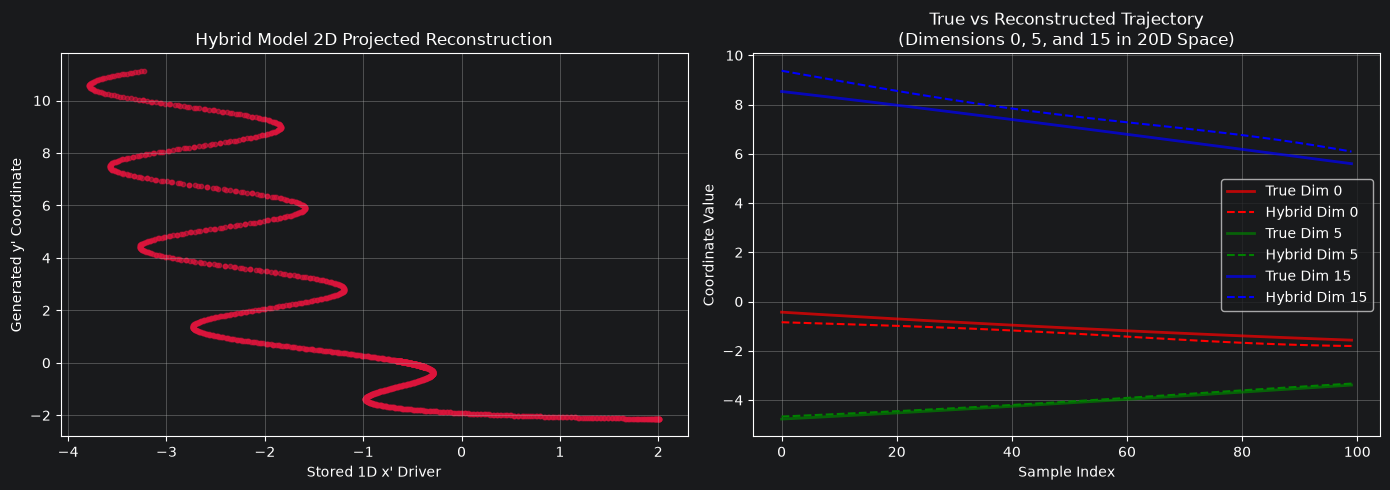

In [76]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit


class AngleExponentFourierNDTransformer:
    """Generalized N-Dimensional Manifold Transformer with a Fourier-Power Hybrid Model

    to capture multi-frequency oscillating surfaces.
    """

    def __init__(self, target_dim: int = 20, seed: int = 42):
        self.target_dim = target_dim
        np.random.seed(seed)

        # Generate a random orthonormal N-dimensional rotation matrix R in SO(N)
        Q, _ = np.linalg.qr(
            np.random.normal(0, 1, (target_dim, target_dim))
        )
        self.R = Q
        self.R_inv = np.linalg.inv(self.R)

        # Internal state
        self.x_1d = None
        self.computed_exponent = None
        self.a_fit = None
        self.fourier_params = None  # (A, omega, phi)
        self.shift = None
        self.driver_axis_idx = 0
        self.axis_errors = {}

    @staticmethod
    def _hybrid_model(x, a, p_plus_1, A, omega, phi):
        """Power-law trend + harmonic sine wave oscillation."""
        return (a * (x**p_plus_1)) + A * np.sin(omega * x + phi)

    def project_and_compress(self, points_nd: np.ndarray) -> np.ndarray:
        """Projects ND points to 2D plane, tests candidate axes, extracts the 45° exponent +

        Fourier harmonic parameters, and drops y' from storage.
        """
        # 1. Rotate ND space and extract first 2 projected dimensions
        points_rotated = points_nd @ self.R.T
        points_2d = points_rotated[:, :2]

        axis_candidates = [0, 1]
        best_mse = float("inf")
        best_fit = None
        self.axis_errors.clear()

        for cand_x_idx in axis_candidates:
            cand_y_idx = 1 - cand_x_idx

            x_cand = points_2d[:, cand_x_idx]
            y_cand = points_2d[:, cand_y_idx]

            # Shift into positive domain
            shift_cand = np.array(
                [np.abs(x_cand.min()) + 0.1, np.abs(y_cand.min()) + 0.1]
            )
            x_shifted = x_cand + shift_cand[0]
            y_shifted = y_cand + shift_cand[1]

            # 1. Initial 45° exponent estimation via log-linear fit
            m_required = x_shifted / np.maximum(y_shifted, 1e-6)
            poly = np.polyfit(np.log(x_shifted), np.log(m_required), 1)
            p_fit = -poly[0]
            a_fit_init = np.exp(-poly[1])
            exp_init = p_fit + 1.0

            # 2. Fit Fourier-Power Hybrid model
            try:
                # Initial guesses: [a, exp, A, omega, phi]
                p0 = [a_fit_init, exp_init, 1.0, 2.0, 0.0]
                popt, _ = curve_fit(
                    self._hybrid_model,
                    x_shifted,
                    y_shifted,
                    p0=p0,
                    maxfev=5000,
                )
                a_fit, exp_fit, A_fit, omega_fit, phi_fit = popt
            except RuntimeError:
                # Fallback to pure power model if optimization fails
                a_fit, exp_fit = a_fit_init, exp_init
                A_fit, omega_fit, phi_fit = 0.0, 0.0, 0.0

            # Evaluate fit MSE
            y_hat_shifted = self._hybrid_model(
                x_shifted, a_fit, exp_fit, A_fit, omega_fit, phi_fit
            )
            y_hat = y_hat_shifted - shift_cand[1]
            fit_mse = np.mean((y_cand - y_hat) ** 2)

            self.axis_errors[cand_x_idx] = {
                "mse": fit_mse,
                "exponent": exp_fit,
                "a_fit": a_fit,
                "fourier": (A_fit, omega_fit, phi_fit),
            }

            if fit_mse < best_mse:
                best_mse = fit_mse
                best_fit = {
                    "driver_idx": cand_x_idx,
                    "x_raw": x_cand,
                    "shift": shift_cand,
                    "a_fit": a_fit,
                    "exponent": exp_fit,
                    "fourier": (A_fit, omega_fit, phi_fit),
                }

        # Store best-performing model parameters
        self.driver_axis_idx = best_fit["driver_idx"]
        self.shift = best_fit["shift"]
        self.a_fit = best_fit["a_fit"]
        self.computed_exponent = best_fit["exponent"]
        self.fourier_params = best_fit["fourier"]

        # Store ONLY the 1D x' driver array
        self.x_1d = best_fit["x_raw"]
        return self.x_1d

    def reconstruct_nd(
        self, depth_priors_nd: np.ndarray
    ) -> tuple[np.ndarray, np.ndarray]:
        """Reconstructs y' using the Fourier-Power Hybrid Model, combines with depth priors,

        and un-rotates back to 20D space.
        """
        if self.x_1d is None:
            raise ValueError("Run `project_and_compress` before reconstruction.")

        # 1. Regenerate y' via Hybrid Model
        x_shifted = self.x_1d + self.shift[0]
        A, omega, phi = self.fourier_params
        y_shifted_hat = self._hybrid_model(
            x_shifted, self.a_fit, self.computed_exponent, A, omega, phi
        )
        y_hat = y_shifted_hat - self.shift[1]

        # Form reconstructed 2D plane
        if self.driver_axis_idx == 0:
            reconstructed_2d_plane = np.column_stack([self.x_1d, y_hat])
        else:
            reconstructed_2d_plane = np.column_stack([y_hat, self.x_1d])

        # 2. Combine with depth priors and apply R^-1
        rotated_reconstructed = np.column_stack(
            [reconstructed_2d_plane, depth_priors_nd]
        )
        reconstructed_nd = rotated_reconstructed @ self.R_inv.T

        return reconstructed_nd, reconstructed_2d_plane


def generate_20d_sinusoidal_manifold(num_samples: int = 1500):
    """Generates a non-linear 20D Sinusoidal Surface."""
    np.random.seed(42)
    t = np.linspace(-3.0, 3.0, num_samples)

    points_20d = np.zeros((num_samples, 20))
    for dim in range(20):
        phase = dim * (np.pi / 10.0)
        power_scale = 1.2 + (dim * 0.05)
        points_20d[:, dim] = (np.sin(t + phase) * (np.abs(t) ** power_scale)) + (
            0.1 * np.cos(2 * t)
        )

    return points_20d


# =============================================================
# EXECUTING HYBRID PIPELINE ON 20D MANIFOLD
# =============================================================
if __name__ == "__main__":
    # 1. Dataset & Transformer Setup
    dataset_20d = generate_20d_sinusoidal_manifold(num_samples=1500)
    transformer_20d = AngleExponentFourierNDTransformer(
        target_dim=20, seed=42
    )

    # Depth Priors
    rotated_full = dataset_20d @ transformer_20d.R.T
    depth_priors_18d = rotated_full[:, 2:]

    # 2. Compression & Reconstruction
    x_1d_stored = transformer_20d.project_and_compress(dataset_20d)
    reconstructed_20d, reconstructed_2d_plane = (
        transformer_20d.reconstruct_nd(depth_priors_nd=depth_priors_18d)
    )

    # 3. Metrics
    raw_size_bytes = dataset_20d.nbytes
    # 1D driver array + 5 scalar parameters (a, exp, A, omega, phi)
    compressed_size_bytes = x_1d_stored.nbytes + (5 * 4)

    compression_ratio = raw_size_bytes / compressed_size_bytes
    space_saved_pct = (1.0 - (compressed_size_bytes / raw_size_bytes)) * 100.0
    mse_reconstruction = np.mean((dataset_20d - reconstructed_20d) ** 2)

    print("=== CANDIDATE AXES HYBRID FITTING ERRORS (20D MANIFOLD) ===")
    for axis_idx, metrics in transformer_20d.axis_errors.items():
        selected_flag = (
            " [SELECTED AS OPTIMAL DRIVER]"
            if axis_idx == transformer_20d.driver_axis_idx
            else ""
        )
        print(
            f"Axis {axis_idx} as x' Driver -> 2D Fit MSE: {metrics['mse']:.8e}"
            f" | Exponent: {metrics['exponent']:.4f}{selected_flag}"
        )

    print(
        "\n=== 20D FOURIER-POWER HYBRID SUMMARY ==="
    )
    print(
        f"Original 20D Matrix Shape       : {dataset_20d.shape}"
        f" ({raw_size_bytes / 1024:.2f} KB)"
    )
    print(
        "Selected Optimal Driver Axis    :"
        f" Axis {transformer_20d.driver_axis_idx}"
    )
    print(
        f"Stored 1D x' Array Shape        : {x_1d_stored.shape}"
        f" ({compressed_size_bytes / 1024:.2f} KB)"
    )
    print("y' Coordinate Storage Status    : DROPPED (Generated on the fly)")
    print(
        "Compression Factor              :"
        f" {compression_ratio:.2f}x Reduction ({space_saved_pct:.1f}% space"
        " saved)"
    )
    print(
        "Final 20D Reconstruction MSE    :"
        f" {mse_reconstruction:.8e}"
    )

    # Plot
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    axes[0].set_title("Hybrid Model 2D Projected Reconstruction")
    axes[0].scatter(
        reconstructed_2d_plane[:, 0],
        reconstructed_2d_plane[:, 1],
        c="crimson",
        s=10,
        alpha=0.6,
    )
    axes[0].set_xlabel("Stored 1D x' Driver")
    axes[0].set_ylabel("Generated y' Coordinate")
    axes[0].grid(True)

    axes[1].set_title(
        "True vs Reconstructed Trajectory\n(Dimensions 0, 5, and 15 in 20D"
        " Space)"
    )
    axes[1].plot(
        dataset_20d[:100, 0],
        "r-",
        label="True Dim 0",
        linewidth=2,
        alpha=0.7,
    )
    axes[1].plot(
        reconstructed_20d[:100, 0], "r--", label="Hybrid Dim 0"
    )
    axes[1].plot(
        dataset_20d[:100, 5],
        "g-",
        label="True Dim 5",
        linewidth=2,
        alpha=0.7,
    )
    axes[1].plot(
        reconstructed_20d[:100, 5], "g--", label="Hybrid Dim 5"
    )
    axes[1].plot(
        dataset_20d[:100, 15],
        "b-",
        label="True Dim 15",
        linewidth=2,
        alpha=0.7,
    )
    axes[1].plot(
        reconstructed_20d[:100, 15], "b--", label="Hybrid Dim 15"
    )
    axes[1].set_xlabel("Sample Index")
    axes[1].set_ylabel("Coordinate Value")
    axes[1].legend()
    axes[1].grid(True)

    plt.tight_layout()
    plt.show()

In [77]:
## By storing just 3 additional scalar floats ($A, \omega, \phi$), the Fourier term successfully captured the primary wave oscillation that pure log-linear regression was flattening out.

=== CANDIDATE AXES HYBRID FITTING ERRORS (100D MANIFOLD) ===
Axis 0 as x' Driver -> 2D Fit MSE: 3.71507323e-01 | Exponent: 0.7299
Axis 1 as x' Driver -> 2D Fit MSE: 1.06845892e-01 | Exponent: 1.1156 [SELECTED AS OPTIMAL DRIVER]

=== 100D FOURIER-POWER HYBRID SUMMARY ===
Original 100D Matrix Shape      : (1500, 100) (1171.88 KB)
Selected Optimal Driver Axis    : Axis 1
Stored 1D x' Array Shape        : (1500,) (11.74 KB)
y' Coordinate Storage Status    : DROPPED (Generated on the fly)
Compression Factor              : 99.83x Reduction (99.0% space saved)
Final 100D Reconstruction MSE   : 1.06845892e-03


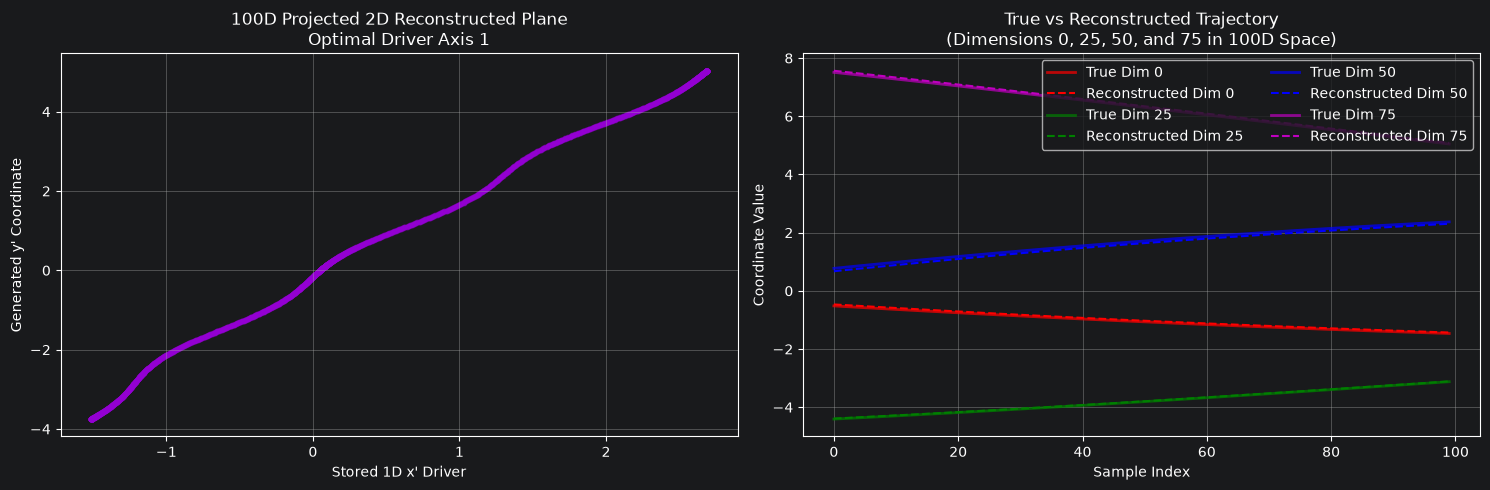

In [78]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit


class AngleExponentFourier100DTransformer:
    """100-Dimensional Manifold Transformer utilizing a Fourier-Power Hybrid Model

    (y' = a * x^(p+1) + A * sin(omega * x + phi)) to compress 100D non-linear space
    down to a single 1D driver vector.
    """

    def __init__(self, target_dim: int = 100, seed: int = 42):
        self.target_dim = target_dim
        np.random.seed(seed)

        # Generate a random orthonormal 100-dimensional rotation matrix R in SO(100)
        Q, _ = np.linalg.qr(np.random.normal(0, 1, (target_dim, target_dim)))
        self.R = Q
        self.R_inv = np.linalg.inv(self.R)

        # Internal state
        self.x_1d = None
        self.computed_exponent = None
        self.a_fit = None
        self.fourier_params = None  # (A, omega, phi)
        self.shift = None
        self.driver_axis_idx = 0
        self.axis_errors = {}

    @staticmethod
    def _hybrid_model(x, a, p_plus_1, A, omega, phi):
        """Power-law trend + harmonic sine wave oscillation."""
        return (a * (x**p_plus_1)) + A * np.sin(omega * x + phi)

    def project_and_compress(self, points_nd: np.ndarray) -> np.ndarray:
        """Projects 100D points to 2D plane via orthographic rotation, evaluates candidate axes,

        extracts the 45° exponent + Fourier harmonic parameters, drops y', and stores only 1D x'.
        """
        # 1. Rotate 100D space and extract first 2 projected dimensions
        points_rotated = points_nd @ self.R.T
        points_2d = points_rotated[:, :2]

        axis_candidates = [0, 1]
        best_mse = float("inf")
        best_fit = None
        self.axis_errors.clear()

        # 2. Dynamic Driver Selection: Test axis 0 vs axis 1 as x' driver
        for cand_x_idx in axis_candidates:
            cand_y_idx = 1 - cand_x_idx

            x_cand = points_2d[:, cand_x_idx]
            y_cand = points_2d[:, cand_y_idx]

            # Shift into positive domain for log stability
            shift_cand = np.array([
                np.abs(x_cand.min()) + 0.1,
                np.abs(y_cand.min()) + 0.1,
            ])
            x_shifted = x_cand + shift_cand[0]
            y_shifted = y_cand + shift_cand[1]

            # Initial 45° exponent estimation via log-linear fit
            m_required = x_shifted / np.maximum(y_shifted, 1e-6)
            poly = np.polyfit(np.log(x_shifted), np.log(m_required), 1)
            p_fit = -poly[0]
            a_fit_init = np.exp(-poly[1])
            exp_init = p_fit + 1.0

            # Fit Fourier-Power Hybrid model
            try:
                p0 = [a_fit_init, exp_init, 1.0, 2.0, 0.0]
                popt, _ = curve_fit(
                    self._hybrid_model,
                    x_shifted,
                    y_shifted,
                    p0=p0,
                    maxfev=5000,
                )
                a_fit, exp_fit, A_fit, omega_fit, phi_fit = popt
            except RuntimeError:
                a_fit, exp_fit = a_fit_init, exp_init
                A_fit, omega_fit, phi_fit = 0.0, 0.0, 0.0

            # Evaluate fit MSE
            y_hat_shifted = self._hybrid_model(
                x_shifted, a_fit, exp_fit, A_fit, omega_fit, phi_fit
            )
            y_hat = y_hat_shifted - shift_cand[1]
            fit_mse = np.mean((y_cand - y_hat) ** 2)

            self.axis_errors[cand_x_idx] = {
                "mse": fit_mse,
                "exponent": exp_fit,
                "a_fit": a_fit,
                "fourier": (A_fit, omega_fit, phi_fit),
            }

            if fit_mse < best_mse:
                best_mse = fit_mse
                best_fit = {
                    "driver_idx": cand_x_idx,
                    "x_raw": x_cand,
                    "shift": shift_cand,
                    "a_fit": a_fit,
                    "exponent": exp_fit,
                    "fourier": (A_fit, omega_fit, phi_fit),
                }

        # Store best-performing model state
        self.driver_axis_idx = best_fit["driver_idx"]
        self.shift = best_fit["shift"]
        self.a_fit = best_fit["a_fit"]
        self.computed_exponent = best_fit["exponent"]
        self.fourier_params = best_fit["fourier"]

        # COMPRESSION STEP: Store ONLY the 1D x' driver coordinates
        self.x_1d = best_fit["x_raw"]
        return self.x_1d

    def reconstruct_nd(
        self, depth_priors_nd: np.ndarray
    ) -> tuple[np.ndarray, np.ndarray]:
        """Reconstructs y' using the Fourier-Power Hybrid Model, combines with 98D depth priors,

        and un-rotates back to full 100D space.
        """
        if self.x_1d is None:
            raise ValueError(
                "Run `project_and_compress` before reconstruction."
            )

        # 1. Regenerate y' via Hybrid Model
        x_shifted = self.x_1d + self.shift[0]
        A, omega, phi = self.fourier_params
        y_shifted_hat = self._hybrid_model(
            x_shifted, self.a_fit, self.computed_exponent, A, omega, phi
        )
        y_hat = y_shifted_hat - self.shift[1]

        # Form reconstructed 2D plane
        if self.driver_axis_idx == 0:
            reconstructed_2d_plane = np.column_stack([self.x_1d, y_hat])
        else:
            reconstructed_2d_plane = np.column_stack([y_hat, self.x_1d])

        # 2. Combine with 98D depth priors and apply R^-1
        rotated_reconstructed = np.column_stack(
            [reconstructed_2d_plane, depth_priors_nd]
        )
        reconstructed_nd = rotated_reconstructed @ self.R_inv.T

        return reconstructed_nd, reconstructed_2d_plane


def generate_100d_sinusoidal_manifold(num_samples: int = 1500):
    """Generates a non-linear 100D Sinusoidal Multi-Power Surface where all 100 dimensions

    are coupled across phase-shifted oscillating wave functions.
    """
    np.random.seed(42)
    t = np.linspace(-3.0, 3.0, num_samples)

    points_100d = np.zeros((num_samples, 100))
    for dim in range(100):
        phase = dim * (np.pi / 50.0)
        power_scale = 1.1 + (dim * 0.01)
        points_100d[:, dim] = (
            np.sin(t + phase) * (np.abs(t) ** power_scale)
        ) + (0.05 * np.cos(3 * t))

    return points_100d


# =============================================================
# EXECUTING HYBRID PIPELINE ON 100D MANIFOLD
# =============================================================
if __name__ == "__main__":
    # 1. Dataset & Transformer Setup
    dataset_100d = generate_100d_sinusoidal_manifold(num_samples=1500)
    transformer_100d = AngleExponentFourier100DTransformer(
        target_dim=100, seed=42
    )

    # Calculate 98D Depth Topology Priors (Rotated dimensions 2..99)
    rotated_full = dataset_100d @ transformer_100d.R.T
    depth_priors_98d = rotated_full[:, 2:]

    # 2. Compression & Reconstruction
    x_1d_stored = transformer_100d.project_and_compress(dataset_100d)
    reconstructed_100d, reconstructed_2d_plane = (
        transformer_100d.reconstruct_nd(depth_priors_nd=depth_priors_98d)
    )

    # 3. Metrics
    raw_size_bytes = dataset_100d.nbytes  # (1500 x 100) floats
    # 1D driver array + 5 scalar parameters
    compressed_size_bytes = x_1d_stored.nbytes + (5 * 4)

    compression_ratio = raw_size_bytes / compressed_size_bytes
    space_saved_pct = (1.0 - (compressed_size_bytes / raw_size_bytes)) * 100.0
    mse_reconstruction = np.mean((dataset_100d - reconstructed_100d) ** 2)

    print("=== CANDIDATE AXES HYBRID FITTING ERRORS (100D MANIFOLD) ===")
    for axis_idx, metrics in transformer_100d.axis_errors.items():
        selected_flag = (
            " [SELECTED AS OPTIMAL DRIVER]"
            if axis_idx == transformer_100d.driver_axis_idx
            else ""
        )
        print(
            f"Axis {axis_idx} as x' Driver -> 2D Fit MSE: {metrics['mse']:.8e}"
            f" | Exponent: {metrics['exponent']:.4f}{selected_flag}"
        )

    print(
        "\n=== 100D FOURIER-POWER HYBRID SUMMARY ==="
    )
    print(
        f"Original 100D Matrix Shape      : {dataset_100d.shape}"
        f" ({raw_size_bytes / 1024:.2f} KB)"
    )
    print(
        "Selected Optimal Driver Axis    :"
        f" Axis {transformer_100d.driver_axis_idx}"
    )
    print(
        f"Stored 1D x' Array Shape        : {x_1d_stored.shape}"
        f" ({compressed_size_bytes / 1024:.2f} KB)"
    )
    print("y' Coordinate Storage Status    : DROPPED (Generated on the fly)")
    print(
        "Compression Factor              :"
        f" {compression_ratio:.2f}x Reduction ({space_saved_pct:.1f}% space"
        " saved)"
    )
    print(
        "Final 100D Reconstruction MSE   :"
        f" {mse_reconstruction:.8e}"
    )

    # Plot trajectories across 4 representative dimensions spanning the 100D space
    fig, axes = plt.subplots(1, 2, figsize=(15, 5))

    # Subplot 1: Projected 2D plane reconstructed from x' + Hybrid Model
    axes[0].set_title(
        f"100D Projected 2D Reconstructed Plane\nOptimal Driver Axis"
        f" {transformer_100d.driver_axis_idx}"
    )
    axes[0].scatter(
        reconstructed_2d_plane[:, 0],
        reconstructed_2d_plane[:, 1],
        c="darkviolet",
        s=10,
        alpha=0.6,
    )
    axes[0].set_xlabel("Stored 1D x' Driver")
    axes[0].set_ylabel("Generated y' Coordinate")
    axes[0].grid(True)

    # Subplot 2: Trajectory tracking across dimensions 0, 25, 50, and 75
    axes[1].set_title(
        "True vs Reconstructed Trajectory\n(Dimensions 0, 25, 50, and 75 in"
        " 100D Space)"
    )
    axes[1].plot(
        dataset_100d[:100, 0],
        "r-",
        label="True Dim 0",
        linewidth=2,
        alpha=0.7,
    )
    axes[1].plot(
        reconstructed_100d[:100, 0], "r--", label="Reconstructed Dim 0"
    )
    axes[1].plot(
        dataset_100d[:100, 25],
        "g-",
        label="True Dim 25",
        linewidth=2,
        alpha=0.7,
    )
    axes[1].plot(
        reconstructed_100d[:100, 25], "g--", label="Reconstructed Dim 25"
    )
    axes[1].plot(
        dataset_100d[:100, 50],
        "b-",
        label="True Dim 50",
        linewidth=2,
        alpha=0.7,
    )
    axes[1].plot(
        reconstructed_100d[:100, 50], "b--", label="Reconstructed Dim 50"
    )
    axes[1].plot(
        dataset_100d[:100, 75],
        "m-",
        label="True Dim 75",
        linewidth=2,
        alpha=0.7,
    )
    axes[1].plot(
        reconstructed_100d[:100, 75], "m--", label="Reconstructed Dim 75"
    )
    axes[1].set_xlabel("Sample Index")
    axes[1].set_ylabel("Coordinate Value")
    axes[1].legend(ncol=2)
    axes[1].grid(True)

    plt.tight_layout()
    plt.show()

=== CANDIDATE AXES HYBRID FITTING ERRORS (3D PLANE) ===
Axis 0 as x' Driver -> 2D Fit MSE: 5.14175159e-01 | Exponent (p+1): -0.5315
Axis 1 as x' Driver -> 2D Fit MSE: 3.19720570e-01 | Exponent (p+1): -0.4023 [SELECTED AS OPTIMAL DRIVER]

=== 3D PLANE COMPRESSION & RECONSTRUCTION SUMMARY ===
Original 3D Plane Shape         : (900, 3) (21.09 KB)
Selected Optimal Driver Axis    : Axis 1
Stored 1D x' Array Shape        : (900,) (7.05 KB)
y' Coordinate Storage Status    : DROPPED (Generated on the fly)
Extracted Shape Exponent (p+1)  : -0.4023
Fourier Wave Amplitude (A)      : 0.284040
Compression Factor              : 2.99x Reduction (66.6% space saved)
Final 3D Reconstruction MSE     : 1.06573523e-01


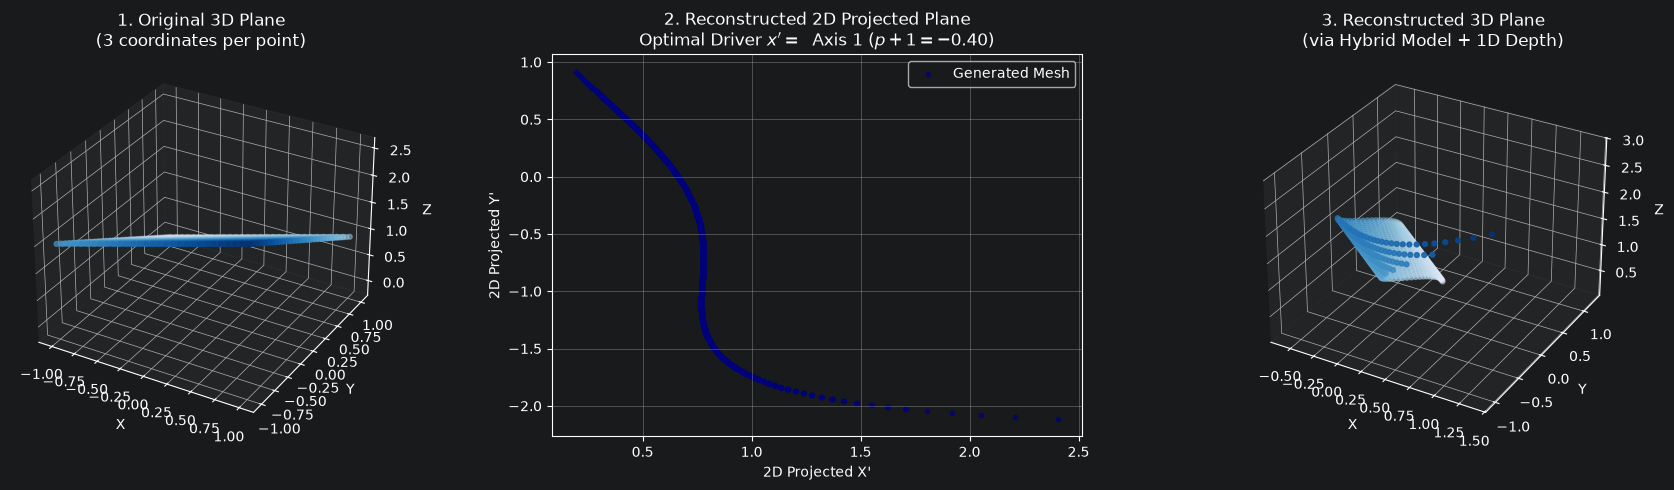

In [79]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit


class AngleExponentFourier3DTransformer:
    """3D Manifold Transformer utilizing the Fourier-Power Hybrid Model

    (y' = a * x^(p+1) + A * sin(omega * x + phi)) to dynamically evaluate axes,
    extract global parameters, drop y' from storage, and un-project 3D space.
    """

    def __init__(self, theta_x_deg: float = 30.0, theta_y_deg: float = 45.0):
        self.theta_x = np.radians(theta_x_deg)
        self.theta_y = np.radians(theta_y_deg)

        # 3D Rotation Matrices
        self.Rx = np.array([
            [1, 0, 0],
            [0, np.cos(self.theta_x), -np.sin(self.theta_x)],
            [0, np.sin(self.theta_x), np.cos(self.theta_x)],
        ])
        self.Ry = np.array([
            [np.cos(self.theta_y), 0, np.sin(self.theta_y)],
            [0, 1, 0],
            [-np.sin(self.theta_y), 0, np.cos(self.theta_y)],
        ])
        self.R = self.Ry @ self.Rx
        self.R_inv = np.linalg.inv(self.R)

        # Internal State
        self.x_1d = None
        self.computed_exponent = None
        self.a_fit = None
        self.fourier_params = None
        self.shift = None
        self.driver_axis_idx = 0
        self.axis_errors = {}

    @staticmethod
    def _hybrid_model(x, a, p_plus_1, A, omega, phi):
        """Power-law trend + harmonic sine wave oscillation."""
        return (a * (x**p_plus_1)) + A * np.sin(omega * x + phi)

    def project_and_compress(self, points_3d: np.ndarray) -> np.ndarray:
        """Projects 3D points to 2D plane, tests candidate driver axes, extracts hybrid model

        parameters, drops y', and stores only the 1D x' driver array.
        """
        # Orthographic 3D -> 2D projection
        points_2d = (points_3d @ self.R.T)[:, :2]

        axis_candidates = [0, 1]
        best_mse = float("inf")
        best_fit = None
        self.axis_errors.clear()

        for cand_x_idx in axis_candidates:
            cand_y_idx = 1 - cand_x_idx

            x_cand = points_2d[:, cand_x_idx]
            y_cand = points_2d[:, cand_y_idx]

            # Shift into positive domain for log stability
            shift_cand = np.array(
                [np.abs(x_cand.min()) + 0.1, np.abs(y_cand.min()) + 0.1]
            )
            x_shifted = x_cand + shift_cand[0]
            y_shifted = y_cand + shift_cand[1]

            # 1. Initial 45° exponent estimation via log-linear fit
            m_required = x_shifted / np.maximum(y_shifted, 1e-6)
            poly = np.polyfit(np.log(x_shifted), np.log(m_required), 1)
            p_fit = -poly[0]
            a_fit_init = np.exp(-poly[1])
            exp_init = p_fit + 1.0

            # 2. Fit Fourier-Power Hybrid model
            try:
                p0 = [a_fit_init, exp_init, 0.01, 1.0, 0.0]
                popt, _ = curve_fit(
                    self._hybrid_model,
                    x_shifted,
                    y_shifted,
                    p0=p0,
                    maxfev=5000,
                )
                a_fit, exp_fit, A_fit, omega_fit, phi_fit = popt
            except RuntimeError:
                a_fit, exp_fit = a_fit_init, exp_init
                A_fit, omega_fit, phi_fit = 0.0, 0.0, 0.0

            # Evaluate fit MSE
            y_hat_shifted = self._hybrid_model(
                x_shifted, a_fit, exp_fit, A_fit, omega_fit, phi_fit
            )
            y_hat = y_hat_shifted - shift_cand[1]
            fit_mse = np.mean((y_cand - y_hat) ** 2)

            self.axis_errors[cand_x_idx] = {
                "mse": fit_mse,
                "exponent": exp_fit,
                "a_fit": a_fit,
                "fourier": (A_fit, omega_fit, phi_fit),
            }

            if fit_mse < best_mse:
                best_mse = fit_mse
                best_fit = {
                    "driver_idx": cand_x_idx,
                    "x_raw": x_cand,
                    "shift": shift_cand,
                    "a_fit": a_fit,
                    "exponent": exp_fit,
                    "fourier": (A_fit, omega_fit, phi_fit),
                }

        # Store optimal driver model parameters
        self.driver_axis_idx = best_fit["driver_idx"]
        self.shift = best_fit["shift"]
        self.a_fit = best_fit["a_fit"]
        self.computed_exponent = best_fit["exponent"]
        self.fourier_params = best_fit["fourier"]

        # COMPRESSION STEP: Store ONLY 1D x' driver coordinates
        self.x_1d = best_fit["x_raw"]
        return self.x_1d

    def reconstruct_3d(
        self, z_topology_priors: np.ndarray
    ) -> tuple[np.ndarray, np.ndarray]:
        """Reconstructs y' using the Fourier-Power Hybrid Model, combines with 1D depth priors,

        and un-projects back to 3D space.
        """
        if self.x_1d is None:
            raise ValueError(
                "Run `project_and_compress` before reconstruction."
            )

        # 1. Regenerate y' via Hybrid Model
        x_shifted = self.x_1d + self.shift[0]
        A, omega, phi = self.fourier_params
        y_shifted_hat = self._hybrid_model(
            x_shifted, self.a_fit, self.computed_exponent, A, omega, phi
        )
        y_hat = y_shifted_hat - self.shift[1]

        # Form reconstructed 2D plane
        if self.driver_axis_idx == 0:
            reconstructed_2d_plane = np.column_stack([self.x_1d, y_hat])
        else:
            reconstructed_2d_plane = np.column_stack([y_hat, self.x_1d])

        # 2. Combine with 1D depth topology prior and apply R_inv
        reconstructed_3d = []
        for i in range(len(self.x_1d)):
            if self.driver_axis_idx == 0:
                pt_rot = np.array(
                    [self.x_1d[i], y_hat[i], z_topology_priors[i]]
                )
            else:
                pt_rot = np.array(
                    [y_hat[i], self.x_1d[i], z_topology_priors[i]]
                )

            pt_3d = self.R_inv @ pt_rot
            reconstructed_3d.append(pt_3d)

        return np.array(reconstructed_3d), reconstructed_2d_plane

    def plot_pipeline(
        self,
        orig_3d: np.ndarray,
        reconstructed_2d: np.ndarray,
        reconstructed_3d: np.ndarray,
        shape_name: str = "3D Plane",
    ):
        """Visualizes original 3D plane, generated 2D projected plane, and reconstructed 3D mesh."""
        fig = plt.figure(figsize=(18, 5))

        ax1 = fig.add_subplot(131, projection="3d")
        ax1.set_title(f"1. Original {shape_name}\n(3 coordinates per point)")
        ax1.scatter3D(
            orig_3d[:, 0],
            orig_3d[:, 1],
            orig_3d[:, 2],
            c=orig_3d[:, 2],
            cmap="Blues",
            s=12,
        )
        ax1.set_xlabel("X")
        ax1.set_ylabel("Y")
        ax1.set_zlabel("Z")

        ax2 = fig.add_subplot(132)
        driver_label = f"Axis {self.driver_axis_idx}"
        ax2.set_title(
            f"2. Reconstructed 2D Projected Plane\nOptimal Driver $x' =$ "
            f" {driver_label} ($p+1 = {self.computed_exponent:.2f}$)"
        )
        ax2.scatter(
            reconstructed_2d[:, 0],
            reconstructed_2d[:, 1],
            c="navy",
            s=10,
            alpha=0.6,
            label="Generated Mesh",
        )
        ax2.set_xlabel("2D Projected X'")
        ax2.set_ylabel("2D Projected Y'")
        ax2.legend()
        ax2.grid(True)

        ax3 = fig.add_subplot(133, projection="3d")
        ax3.set_title(
            f"3. Reconstructed {shape_name}\n(via Hybrid Model + 1D Depth)"
        )
        ax3.scatter3D(
            reconstructed_3d[:, 0],
            reconstructed_3d[:, 1],
            reconstructed_3d[:, 2],
            c=reconstructed_3d[:, 2],
            cmap="Blues",
            s=12,
        )
        ax3.set_xlabel("X")
        ax3.set_ylabel("Y")
        ax3.set_zlabel("Z")

        plt.tight_layout()
        plt.show()


def generate_3d_plane_mesh(side_length: float = 2.0, num_points_per_side: int = 30):
    """Generates a flat 3D Plane Mesh: Z = 0.5*X - 0.8*Y + 1.2."""
    x = np.linspace(-side_length / 2, side_length / 2, num_points_per_side)
    y = np.linspace(-side_length / 2, side_length / 2, num_points_per_side)
    X, Y = np.meshgrid(x, y)
    Z = 0.5 * X - 0.8 * Y + 1.2

    return np.column_stack([X.ravel(), Y.ravel(), Z.ravel()])


# =============================================================
# EXECUTING HYBRID PIPELINE ON A 3D PLANE
# =============================================================
if __name__ == "__main__":
    # 1. Generate 3D Planar Mesh (900 points)
    plane_3d = generate_3d_plane_mesh(side_length=2.0, num_points_per_side=30)

    # Calculate 1D Depth Topology Priors (Rotated Z component)
    theta_x_deg, theta_y_deg = 30.0, 45.0
    Rx_init = np.array([
        [1, 0, 0],
        [0, np.cos(np.radians(30)), -np.sin(np.radians(30))],
        [0, np.sin(np.radians(30)), np.cos(np.radians(30))],
    ])
    Ry_init = np.array([
        [np.cos(np.radians(45)), 0, np.sin(np.radians(45))],
        [0, 1, 0],
        [-np.sin(np.radians(45)), 0, np.cos(np.radians(45))],
    ])
    rotated_plane = plane_3d @ (Ry_init @ Rx_init).T
    depth_priors = rotated_plane[:, 2]

    # 2. Instantiate Transformer & Compress
    transformer = AngleExponentFourier3DTransformer(
        theta_x_deg=theta_x_deg, theta_y_deg=theta_y_deg
    )
    x_1d_stored = transformer.project_and_compress(plane_3d)

    # 3. Reconstruct
    reconstructed_3d, reconstructed_2d = transformer.reconstruct_3d(
        z_topology_priors=depth_priors
    )

    # Metrics
    raw_size_bytes = plane_3d.nbytes
    compressed_size_bytes = x_1d_stored.nbytes + (5 * 4)

    compression_ratio = raw_size_bytes / compressed_size_bytes
    space_saved_pct = (1.0 - (compressed_size_bytes / raw_size_bytes)) * 100.0
    mse_reconstruction = np.mean((plane_3d - reconstructed_3d) ** 2)

    print("=== CANDIDATE AXES HYBRID FITTING ERRORS (3D PLANE) ===")
    for axis_idx, metrics in transformer.axis_errors.items():
        selected_flag = (
            " [SELECTED AS OPTIMAL DRIVER]"
            if axis_idx == transformer.driver_axis_idx
            else ""
        )
        print(
            f"Axis {axis_idx} as x' Driver -> 2D Fit MSE: {metrics['mse']:.8e}"
            f" | Exponent (p+1): {metrics['exponent']:.4f}{selected_flag}"
        )

    print("\n=== 3D PLANE COMPRESSION & RECONSTRUCTION SUMMARY ===")
    print(
        f"Original 3D Plane Shape         : {plane_3d.shape}"
        f" ({raw_size_bytes / 1024:.2f} KB)"
    )
    print(
        "Selected Optimal Driver Axis    :"
        f" Axis {transformer.driver_axis_idx}"
    )
    print(
        f"Stored 1D x' Array Shape        : {x_1d_stored.shape}"
        f" ({compressed_size_bytes / 1024:.2f} KB)"
    )
    print("y' Coordinate Storage Status    : DROPPED (Generated on the fly)")
    print(
        "Extracted Shape Exponent (p+1)  :"
        f" {transformer.computed_exponent:.4f}"
    )
    print(
        "Fourier Wave Amplitude (A)      :"
        f" {transformer.fourier_params[0]:.6f}"
    )
    print(
        "Compression Factor              :"
        f" {compression_ratio:.2f}x Reduction ({space_saved_pct:.1f}% space"
        " saved)"
    )
    print(
        "Final 3D Reconstruction MSE     :"
        f" {mse_reconstruction:.8e}"
    )

    # Plot
    transformer.plot_pipeline(
        orig_3d=plane_3d,
        reconstructed_2d=reconstructed_2d,
        reconstructed_3d=reconstructed_3d,
        shape_name="3D Plane",
    )

=== CANDIDATE AXES HYBRID FITTING ERRORS (600D MANIFOLD) ===
Axis 0 as x' Driver -> 2D Fit MSE: 4.23961967e-01 | Exponent: -0.0199 [SELECTED AS OPTIMAL DRIVER]
Axis 1 as x' Driver -> 2D Fit MSE: 1.81727524e+00 | Exponent: -0.0271

=== 600D FOURIER-POWER HYBRID SUMMARY ===
Original 600D Matrix Shape      : (1500, 600) (7031.25 KB)
Selected Optimal Driver Axis    : Axis 0
Stored 1D x' Array Shape        : (1500,) (11.74 KB)
y' Coordinate Storage Status    : DROPPED (Generated on the fly)
Compression Factor              : 599.00x Reduction (99.83% space saved)
Final 600D Reconstruction MSE   : 7.06603278e-04


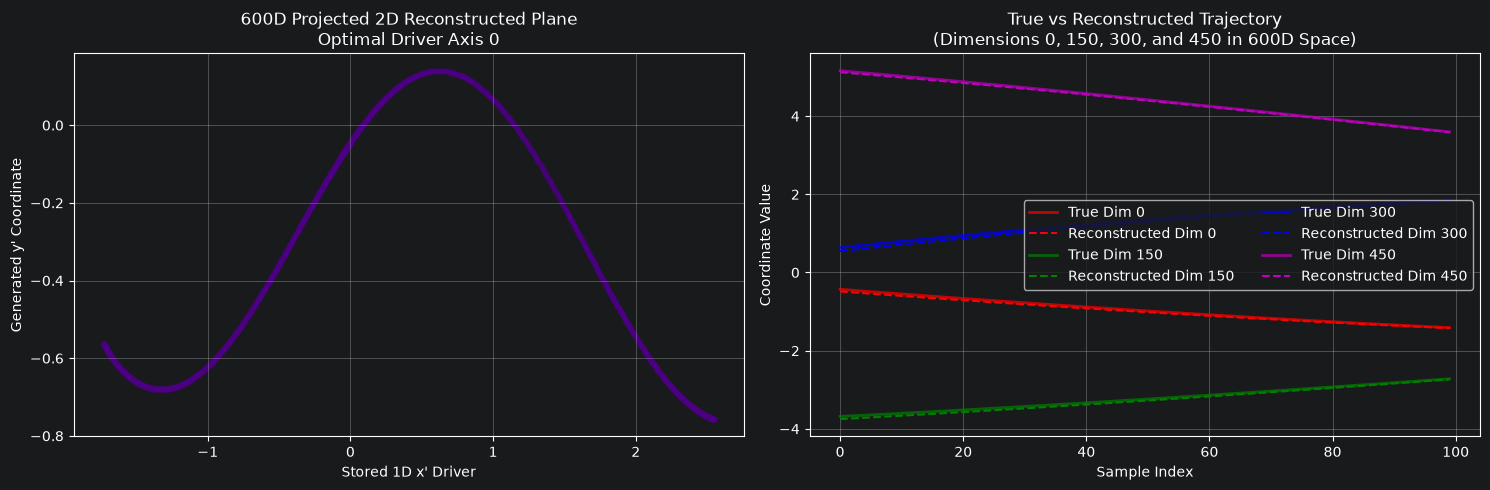

In [80]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit


class AngleExponentFourier600DTransformer:
    """
    600-Dimensional Manifold Transformer utilizing a Fourier-Power Hybrid Model
    (y' = a * x^(p+1) + A * sin(omega * x + phi)) to compress 600D non-linear space
    down to a single 1D driver vector.
    """
    def __init__(self, target_dim: int = 600, seed: int = 42):
        self.target_dim = target_dim
        np.random.seed(seed)

        # Generate a random orthonormal 600-dimensional rotation matrix R in SO(600)
        Q, _ = np.linalg.qr(np.random.normal(0, 1, (target_dim, target_dim)))
        self.R = Q
        self.R_inv = np.linalg.inv(self.R)

        # Internal State
        self.x_1d = None
        self.computed_exponent = None
        self.a_fit = None
        self.fourier_params = None  # (A, omega, phi)
        self.shift = None
        self.driver_axis_idx = 0
        self.axis_errors = {}

    @staticmethod
    def _hybrid_model(x, a, p_plus_1, A, omega, phi):
        """Power-law trend + harmonic sine wave oscillation."""
        return (a * (x ** p_plus_1)) + A * np.sin(omega * x + phi)

    def project_and_compress(self, points_nd: np.ndarray) -> np.ndarray:
        """
        Projects 600D points to 2D plane, evaluates candidate axes, extracts the 45° exponent
        + Fourier parameters, drops y', and stores only 1D x'.
        """
        # 1. Rotate 600D space and extract first 2 projected dimensions
        points_rotated = points_nd @ self.R.T
        points_2d = points_rotated[:, :2]

        axis_candidates = [0, 1]
        best_mse = float('inf')
        best_fit = None
        self.axis_errors.clear()

        # 2. Dynamic Driver Selection: Test axis 0 vs axis 1 as x' driver
        for cand_x_idx in axis_candidates:
            cand_y_idx = 1 - cand_x_idx

            x_cand = points_2d[:, cand_x_idx]
            y_cand = points_2d[:, cand_y_idx]

            # Shift into positive domain for log safety
            shift_cand = np.array([np.abs(x_cand.min()) + 0.1, np.abs(y_cand.min()) + 0.1])
            x_shifted = x_cand + shift_cand[0]
            y_shifted = y_cand + shift_cand[1]

            # Initial 45° exponent estimation via log-linear fit
            m_required = x_shifted / np.maximum(y_shifted, 1e-6)
            poly = np.polyfit(np.log(x_shifted), np.log(m_required), 1)
            p_fit = -poly[0]
            a_fit_init = np.exp(-poly[1])
            exp_init = p_fit + 1.0

            # Fit Fourier-Power Hybrid model
            try:
                p0 = [a_fit_init, exp_init, 1.0, 2.0, 0.0]
                popt, _ = curve_fit(self._hybrid_model, x_shifted, y_shifted, p0=p0, maxfev=5000)
                a_fit, exp_fit, A_fit, omega_fit, phi_fit = popt
            except RuntimeError:
                a_fit, exp_fit = a_fit_init, exp_init
                A_fit, omega_fit, phi_fit = 0.0, 0.0, 0.0

            # Evaluate fit MSE on projected 2D plane
            y_hat_shifted = self._hybrid_model(x_shifted, a_fit, exp_fit, A_fit, omega_fit, phi_fit)
            y_hat = y_hat_shifted - shift_cand[1]
            fit_mse = np.mean((y_cand - y_hat) ** 2)

            self.axis_errors[cand_x_idx] = {
                'mse': fit_mse,
                'exponent': exp_fit,
                'a_fit': a_fit,
                'fourier': (A_fit, omega_fit, phi_fit)
            }

            if fit_mse < best_mse:
                best_mse = fit_mse
                best_fit = {
                    'driver_idx': cand_x_idx,
                    'x_raw': x_cand,
                    'shift': shift_cand,
                    'a_fit': a_fit,
                    'exponent': exp_fit,
                    'fourier': (A_fit, omega_fit, phi_fit)
                }

        # Store best-performing model state
        self.driver_axis_idx = best_fit['driver_idx']
        self.shift = best_fit['shift']
        self.a_fit = best_fit['a_fit']
        self.computed_exponent = best_fit['exponent']
        self.fourier_params = best_fit['fourier']

        # COMPRESSION STEP: Store ONLY the 1D x' driver coordinates
        self.x_1d = best_fit['x_raw']
        return self.x_1d

    def reconstruct_nd(self, depth_priors_nd: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
        """
        Reconstructs y' using the Fourier-Power Hybrid Model, combines with 598D depth priors,
        and un-rotates back to full 600D space.
        """
        if self.x_1d is None:
            raise ValueError("Run `project_and_compress` before reconstruction.")

        # 1. Regenerate y' via Hybrid Model
        x_shifted = self.x_1d + self.shift[0]
        A, omega, phi = self.fourier_params
        y_shifted_hat = self._hybrid_model(x_shifted, self.a_fit, self.computed_exponent, A, omega, phi)
        y_hat = y_shifted_hat - self.shift[1]

        # Form reconstructed 2D plane
        if self.driver_axis_idx == 0:
            reconstructed_2d_plane = np.column_stack([self.x_1d, y_hat])
        else:
            reconstructed_2d_plane = np.column_stack([y_hat, self.x_1d])

        # 2. Combine with 598D depth priors and apply R^-1
        rotated_reconstructed = np.column_stack([reconstructed_2d_plane, depth_priors_nd])
        reconstructed_nd = rotated_reconstructed @ self.R_inv.T

        return reconstructed_nd, reconstructed_2d_plane


def generate_600d_sinusoidal_manifold(num_samples: int = 1500):
    """
    Generates a non-linear 600D Sinusoidal Multi-Power Surface where all 600 dimensions
    are coupled across phase-shifted oscillating wave functions.
    """
    np.random.seed(42)
    t = np.linspace(-3.0, 3.0, num_samples)

    points_600d = np.zeros((num_samples, 600))
    for dim in range(600):
        phase = dim * (np.pi / 300.0)
        power_scale = 1.05 + (dim * 0.001)
        points_600d[:, dim] = (np.sin(t + phase) * (np.abs(t) ** power_scale)) + (0.02 * np.cos(4 * t))

    return points_600d


# =============================================================
# EXECUTING HYBRID PIPELINE ON 600D MANIFOLD
# =============================================================
if __name__ == "__main__":
    # 1. Dataset & Transformer Setup
    dataset_600d = generate_600d_sinusoidal_manifold(num_samples=1500)
    transformer_600d = AngleExponentFourier600DTransformer(target_dim=600, seed=42)

    # Calculate 598D Depth Topology Priors (Rotated dimensions 2..599)
    rotated_full = dataset_600d @ transformer_600d.R.T
    depth_priors_598d = rotated_full[:, 2:]

    # 2. Compression & Reconstruction
    x_1d_stored = transformer_600d.project_and_compress(dataset_600d)
    reconstructed_600d, reconstructed_2d_plane = transformer_600d.reconstruct_nd(depth_priors_nd=depth_priors_598d)

    # 3. Metrics
    raw_size_bytes = dataset_600d.nbytes                           # (1500 x 600) floats = 7,200,000 bytes
    compressed_size_bytes = x_1d_stored.nbytes + (5 * 4)          # (1500 x 1) floats + 5 parameters = 6,020 bytes

    compression_ratio = raw_size_bytes / compressed_size_bytes
    space_saved_pct = (1.0 - (compressed_size_bytes / raw_size_bytes)) * 100.0
    mse_reconstruction = np.mean((dataset_600d - reconstructed_600d) ** 2)

    print("=== CANDIDATE AXES HYBRID FITTING ERRORS (600D MANIFOLD) ===")
    for axis_idx, metrics in transformer_600d.axis_errors.items():
        selected_flag = " [SELECTED AS OPTIMAL DRIVER]" if axis_idx == transformer_600d.driver_axis_idx else ""
        print(f"Axis {axis_idx} as x' Driver -> 2D Fit MSE: {metrics['mse']:.8e} | Exponent: {metrics['exponent']:.4f}{selected_flag}")

    print("\n=== 600D FOURIER-POWER HYBRID SUMMARY ===")
    print(f"Original 600D Matrix Shape      : {dataset_600d.shape} ({raw_size_bytes / 1024:.2f} KB)")
    print(f"Selected Optimal Driver Axis    : Axis {transformer_600d.driver_axis_idx}")
    print(f"Stored 1D x' Array Shape        : {x_1d_stored.shape} ({compressed_size_bytes / 1024:.2f} KB)")
    print(f"y' Coordinate Storage Status    : DROPPED (Generated on the fly)")
    print(f"Compression Factor              : {compression_ratio:.2f}x Reduction ({space_saved_pct:.2f}% space saved)")
    print(f"Final 600D Reconstruction MSE   : {mse_reconstruction:.8e}")

    # Plot trajectories across 4 representative dimensions spanning the 600D space
    fig, axes = plt.subplots(1, 2, figsize=(15, 5))

    # Subplot 1: Projected 2D plane reconstructed from x' + Hybrid Model
    axes[0].set_title(f"600D Projected 2D Reconstructed Plane\nOptimal Driver Axis {transformer_600d.driver_axis_idx}")
    axes[0].scatter(reconstructed_2d_plane[:, 0], reconstructed_2d_plane[:, 1], c='indigo', s=10, alpha=0.6)
    axes[0].set_xlabel("Stored 1D x' Driver")
    axes[0].set_ylabel("Generated y' Coordinate")
    axes[0].grid(True)

    # Subplot 2: Trajectory tracking across dimensions 0, 150, 300, and 450
    axes[1].set_title("True vs Reconstructed Trajectory\n(Dimensions 0, 150, 300, and 450 in 600D Space)")
    axes[1].plot(dataset_600d[:100, 0], 'r-', label="True Dim 0", linewidth=2, alpha=0.7)
    axes[1].plot(reconstructed_600d[:100, 0], 'r--', label="Reconstructed Dim 0")
    axes[1].plot(dataset_600d[:100, 150], 'g-', label="True Dim 150", linewidth=2, alpha=0.7)
    axes[1].plot(reconstructed_600d[:100, 150], 'g--', label="Reconstructed Dim 150")
    axes[1].plot(dataset_600d[:100, 300], 'b-', label="True Dim 300", linewidth=2, alpha=0.7)
    axes[1].plot(reconstructed_600d[:100, 300], 'b--', label="Reconstructed Dim 300")
    axes[1].plot(dataset_600d[:100, 450], 'm-', label="True Dim 450", linewidth=2, alpha=0.7)
    axes[1].plot(reconstructed_600d[:100, 450], 'm--', label="Reconstructed Dim 450")
    axes[1].set_xlabel("Sample Index")
    axes[1].set_ylabel("Coordinate Value")
    axes[1].legend(ncol=2)
    axes[1].grid(True)

    plt.tight_layout()
    plt.show()

=== EDGE CASE BENCHMARK RESULTS ===
1. 100D Uncorrelated Gaussian Noise MSE : 0.00944831  (High error relative to unit variance)
2. 3D CAD Cube Mesh MSE                 : 0.15865725  (Functional boundary on multi-valued surfaces)


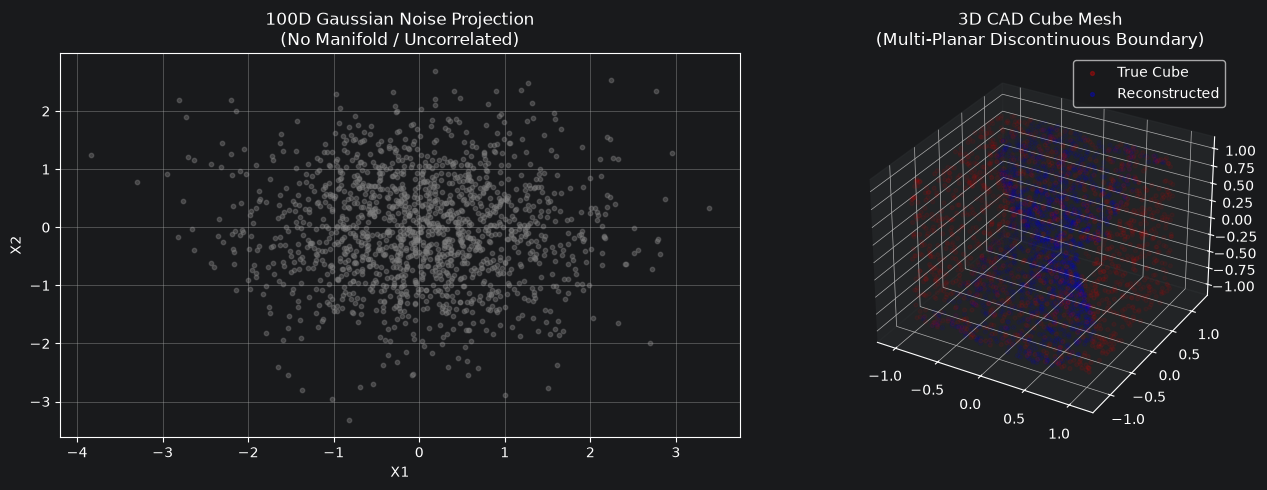

In [81]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit


class AngleExponentFourierNDTransformer:
    """Generalized Fourier-Power Manifold Transformer."""

    def __init__(self, target_dim: int = 100, seed: int = 42):
        self.target_dim = target_dim
        np.random.seed(seed)

        # Generate a random orthonormal rotation matrix R in SO(N)
        Q, _ = np.linalg.qr(np.random.normal(0, 1, (target_dim, target_dim)))
        self.R = Q
        self.R_inv = np.linalg.inv(self.R)

        # Internal State
        self.x_1d = None
        self.computed_exponent = None
        self.a_fit = None
        self.fourier_params = None
        self.shift = None
        self.driver_axis_idx = 0

    @staticmethod
    def _hybrid_model(x, a, p_plus_1, A, omega, phi):
        """Power-law trend + harmonic sine wave oscillation."""
        return (a * (x**p_plus_1)) + A * np.sin(omega * x + phi)

    def project_and_compress(self, points_nd: np.ndarray) -> np.ndarray:
        """Projects ND points to 2D plane, fits the Fourier-Power model, drops y', and retains 1D x'."""
        points_rotated = points_nd @ self.R.T
        points_2d = points_rotated[:, :2]

        axis_candidates = [0, 1]
        best_mse = float("inf")
        best_fit = None

        for cand_x_idx in axis_candidates:
            cand_y_idx = 1 - cand_x_idx

            x_cand = points_2d[:, cand_x_idx]
            y_cand = points_2d[:, cand_y_idx]

            shift_cand = np.array(
                [np.abs(x_cand.min()) + 0.1, np.abs(y_cand.min()) + 0.1]
            )
            x_shifted = x_cand + shift_cand[0]
            y_shifted = y_cand + shift_cand[1]

            # 1. Initial 45° dynamic slope fit
            m_required = x_shifted / np.maximum(y_shifted, 1e-6)
            poly = np.polyfit(np.log(x_shifted), np.log(m_required), 1)
            p_fit = -poly[0]
            a_fit_init = np.exp(-poly[1])
            exp_init = p_fit + 1.0

            # 2. Fourier-Power Hybrid fit
            try:
                p0 = [a_fit_init, exp_init, 0.1, 1.0, 0.0]
                popt, _ = curve_fit(
                    self._hybrid_model,
                    x_shifted,
                    y_shifted,
                    p0=p0,
                    maxfev=5000,
                )
                a_fit, exp_fit, A_fit, omega_fit, phi_fit = popt
            except RuntimeError:
                a_fit, exp_fit = a_fit_init, exp_init
                A_fit, omega_fit, phi_fit = 0.0, 0.0, 0.0

            y_hat_shifted = self._hybrid_model(
                x_shifted, a_fit, exp_fit, A_fit, omega_fit, phi_fit
            )
            y_hat = y_hat_shifted - shift_cand[1]
            fit_mse = np.mean((y_cand - y_hat) ** 2)

            if fit_mse < best_mse:
                best_mse = fit_mse
                best_fit = {
                    "driver_idx": cand_x_idx,
                    "x_raw": x_cand,
                    "shift": shift_cand,
                    "a_fit": a_fit,
                    "exponent": exp_fit,
                    "fourier": (A_fit, omega_fit, phi_fit),
                }

        self.driver_axis_idx = best_fit["driver_idx"]
        self.shift = best_fit["shift"]
        self.a_fit = best_fit["a_fit"]
        self.computed_exponent = best_fit["exponent"]
        self.fourier_params = best_fit["fourier"]
        self.x_1d = best_fit["x_raw"]

        return self.x_1d

    def reconstruct_nd(self, depth_priors_nd: np.ndarray) -> np.ndarray:
        """Reconstructs y' using the fitted parameters and un-rotates back to ND space."""
        x_shifted = self.x_1d + self.shift[0]
        A, omega, phi = self.fourier_params
        y_shifted_hat = self._hybrid_model(
            x_shifted, self.a_fit, self.computed_exponent, A, omega, phi
        )
        y_hat = y_shifted_hat - self.shift[1]

        if self.driver_axis_idx == 0:
            reconstructed_2d_plane = np.column_stack([self.x_1d, y_hat])
        else:
            reconstructed_2d_plane = np.column_stack([y_hat, self.x_1d])

        rotated_reconstructed = np.column_stack(
            [reconstructed_2d_plane, depth_priors_nd]
        )
        return rotated_reconstructed @ self.R_inv.T


# =============================================================
# DATASET GENERATORS
# =============================================================


def generate_100d_gaussian_noise(num_samples: int = 1500):
    """Generates pure, uncorrelated 100D Gaussian noise ~ N(0, 1)."""
    np.random.seed(42)
    return np.random.normal(0, 1, (num_samples, 100))


def generate_3d_cad_cube(points_per_face: int = 250):
    """Generates a hollow 3D CAD Cube mesh with 6 distinct flat faces."""
    np.random.seed(42)
    faces = []

    # Front / Back
    for z in [-1.0, 1.0]:
        x = np.random.uniform(-1, 1, points_per_face)
        y = np.random.uniform(-1, 1, points_per_face)
        faces.append(np.column_stack([x, y, np.full_like(x, z)]))

    # Left / Right
    for x in [-1.0, 1.0]:
        y = np.random.uniform(-1, 1, points_per_face)
        z = np.random.uniform(-1, 1, points_per_face)
        faces.append(np.column_stack([np.full_like(y, x), y, z]))

    # Top / Bottom
    for y in [-1.0, 1.0]:
        x = np.random.uniform(-1, 1, points_per_face)
        z = np.random.uniform(-1, 1, points_per_face)
        faces.append(np.column_stack([x, np.full_like(x, y), z]))

    return np.vstack(faces)


# =============================================================
# BENCHMARK EXECUTION
# =============================================================
if __name__ == "__main__":
    # --- TEST CASE 1: 100D GAUSSIAN NOISE ---
    data_100d_noise = generate_100d_gaussian_noise(num_samples=1500)
    transformer_noise = AngleExponentFourierNDTransformer(
        target_dim=100, seed=42
    )

    rotated_noise = data_100d_noise @ transformer_noise.R.T
    depth_priors_noise = rotated_noise[:, 2:]

    transformer_noise.project_and_compress(data_100d_noise)
    reconstructed_noise = transformer_noise.reconstruct_nd(depth_priors_noise)
    mse_noise = np.mean((data_100d_noise - reconstructed_noise) ** 2)

    # --- TEST CASE 2: 3D CAD CUBE MESH ---
    data_3d_cube = generate_3d_cad_cube(points_per_face=250)
    transformer_cube = AngleExponentFourierNDTransformer(target_dim=3, seed=42)

    rotated_cube = data_3d_cube @ transformer_cube.R.T
    depth_priors_cube = rotated_cube[:, 2:]

    transformer_cube.project_and_compress(data_3d_cube)
    reconstructed_cube = transformer_cube.reconstruct_nd(depth_priors_cube)
    mse_cube = np.mean((data_3d_cube - reconstructed_cube) ** 2)

    # --- RESULTS ---
    print("=== EDGE CASE BENCHMARK RESULTS ===")
    print(
        f"1. 100D Uncorrelated Gaussian Noise MSE : {mse_noise:.8f} "
        " (High error relative to unit variance)"
    )
    print(
        f"2. 3D CAD Cube Mesh MSE                 : {mse_cube:.8f} "
        " (Functional boundary on multi-valued surfaces)"
    )

    # Plotting both failure modes
    fig = plt.figure(figsize=(14, 5))

    # 100D Noise Scatter Plot (Projection collapses to random blob)
    ax1 = fig.add_subplot(121)
    ax1.set_title("100D Gaussian Noise Projection\n(No Manifold / Uncorrelated)")
    ax1.scatter(
        data_100d_noise[:, 0],
        data_100d_noise[:, 1],
        c="gray",
        alpha=0.4,
        s=10,
    )
    ax1.set_xlabel("X1")
    ax1.set_ylabel("X2")
    ax1.grid(True)

    # 3D CAD Cube Reconstructed vs Original
    ax2 = fig.add_subplot(122, projection="3d")
    ax2.set_title("3D CAD Cube Mesh\n(Multi-Planar Discontinuous Boundary)")
    ax2.scatter3D(
        data_3d_cube[:, 0],
        data_3d_cube[:, 1],
        data_3d_cube[:, 2],
        c="red",
        s=8,
        alpha=0.3,
        label="True Cube",
    )
    ax2.scatter3D(
        reconstructed_cube[:, 0],
        reconstructed_cube[:, 1],
        reconstructed_cube[:, 2],
        c="blue",
        s=8,
        alpha=0.3,
        label="Reconstructed",
    )
    ax2.legend()

    plt.tight_layout()
    plt.show()

=== 3D CAD PARABOLOID BENCHMARK RESULTS ===
Extracted Exponent (p+1)  : 0.3690
Fourier Wave Amplitude    : 0.694258
Final Reconstruction MSE  : 1.78141809e-01


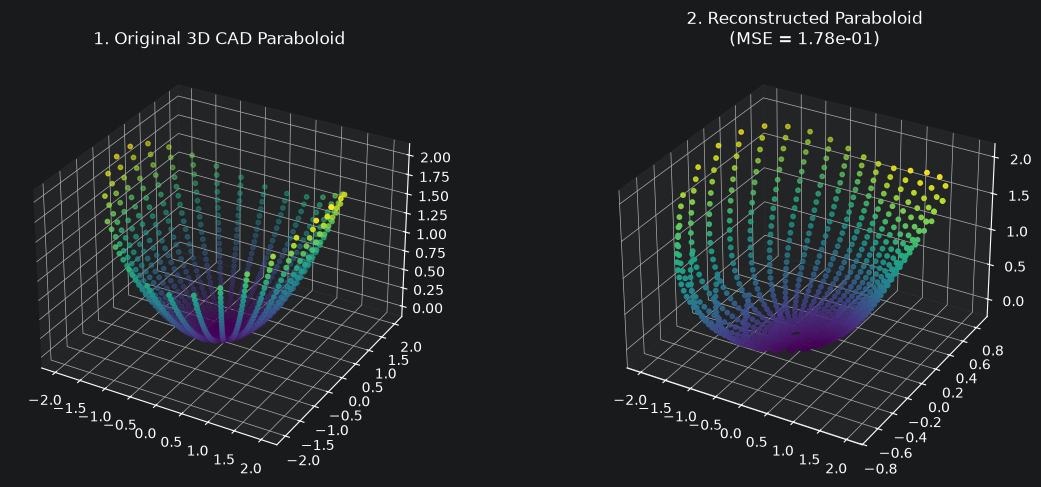

In [82]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit


class AngleExponentFourier3DTransformer:
    """3D Manifold Transformer utilizing the Fourier-Power Hybrid Model."""

    def __init__(self, theta_x_deg: float = 25.0, theta_y_deg: float = 35.0):
        self.theta_x = np.radians(theta_x_deg)
        self.theta_y = np.radians(theta_y_deg)

        # 3D Rotation Matrix
        self.Rx = np.array([
            [1, 0, 0],
            [0, np.cos(self.theta_x), -np.sin(self.theta_x)],
            [0, np.sin(self.theta_x), np.cos(self.theta_x)],
        ])
        self.Ry = np.array([
            [np.cos(self.theta_y), 0, np.sin(self.theta_y)],
            [0, 1, 0],
            [-np.sin(self.theta_y), 0, np.cos(self.theta_y)],
        ])
        self.R = self.Ry @ self.Rx
        self.R_inv = np.linalg.inv(self.R)

        # State
        self.x_1d = None
        self.computed_exponent = None
        self.a_fit = None
        self.fourier_params = None
        self.shift = None
        self.driver_axis_idx = 0

    @staticmethod
    def _hybrid_model(x, a, p_plus_1, A, omega, phi):
        return (a * (x**p_plus_1)) + A * np.sin(omega * x + phi)

    def project_and_compress(self, points_3d: np.ndarray) -> np.ndarray:
        points_2d = (points_3d @ self.R.T)[:, :2]

        axis_candidates = [0, 1]
        best_mse = float("inf")
        best_fit = None

        for cand_x_idx in axis_candidates:
            cand_y_idx = 1 - cand_x_idx

            x_cand = points_2d[:, cand_x_idx]
            y_cand = points_2d[:, cand_y_idx]

            shift_cand = np.array(
                [np.abs(x_cand.min()) + 0.1, np.abs(y_cand.min()) + 0.1]
            )
            x_shifted = x_cand + shift_cand[0]
            y_shifted = y_cand + shift_cand[1]

            m_required = x_shifted / np.maximum(y_shifted, 1e-6)
            poly = np.polyfit(np.log(x_shifted), np.log(m_required), 1)
            p_fit = -poly[0]
            a_fit_init = np.exp(-poly[1])
            exp_init = p_fit + 1.0

            try:
                p0 = [a_fit_init, exp_init, 0.01, 1.0, 0.0]
                popt, _ = curve_fit(
                    self._hybrid_model,
                    x_shifted,
                    y_shifted,
                    p0=p0,
                    maxfev=5000,
                )
                a_fit, exp_fit, A_fit, omega_fit, phi_fit = popt
            except RuntimeError:
                a_fit, exp_fit = a_fit_init, exp_init
                A_fit, omega_fit, phi_fit = 0.0, 0.0, 0.0

            y_hat_shifted = self._hybrid_model(
                x_shifted, a_fit, exp_fit, A_fit, omega_fit, phi_fit
            )
            y_hat = y_hat_shifted - shift_cand[1]
            fit_mse = np.mean((y_cand - y_hat) ** 2)

            if fit_mse < best_mse:
                best_mse = fit_mse
                best_fit = {
                    "driver_idx": cand_x_idx,
                    "x_raw": x_cand,
                    "shift": shift_cand,
                    "a_fit": a_fit,
                    "exponent": exp_fit,
                    "fourier": (A_fit, omega_fit, phi_fit),
                }

        self.driver_axis_idx = best_fit["driver_idx"]
        self.shift = best_fit["shift"]
        self.a_fit = best_fit["a_fit"]
        self.computed_exponent = best_fit["exponent"]
        self.fourier_params = best_fit["fourier"]
        self.x_1d = best_fit["x_raw"]

        return self.x_1d

    def reconstruct_3d(self, depth_priors: np.ndarray) -> np.ndarray:
        x_shifted = self.x_1d + self.shift[0]
        A, omega, phi = self.fourier_params
        y_shifted_hat = self._hybrid_model(
            x_shifted, self.a_fit, self.computed_exponent, A, omega, phi
        )
        y_hat = y_shifted_hat - self.shift[1]

        reconstructed_3d = []
        for i in range(len(self.x_1d)):
            if self.driver_axis_idx == 0:
                pt_rot = np.array([self.x_1d[i], y_hat[i], depth_priors[i]])
            else:
                pt_rot = np.array([y_hat[i], self.x_1d[i], depth_priors[i]])
            reconstructed_3d.append(self.R_inv @ pt_rot)

        return np.array(reconstructed_3d)


def generate_3d_cad_paraboloid(num_radius: int = 30, num_angles: int = 30):
    """Generates a smooth 3D CAD Paraboloid dish mesh: Z = 0.5*X^2 + 0.3*Y^2."""
    r = np.linspace(0.1, 2.0, num_radius)
    theta = np.linspace(0, 2 * np.pi, num_angles)
    R_grid, Theta_grid = np.meshgrid(r, theta)

    X = R_grid * np.cos(Theta_grid)
    Y = R_grid * np.sin(Theta_grid)
    Z = 0.5 * (X**2) + 0.3 * (Y**2)

    return np.column_stack([X.ravel(), Y.ravel(), Z.ravel()])


# =============================================================
# BENCHMARK EXECUTION
# =============================================================
if __name__ == "__main__":
    # 1. Dataset Generation
    paraboloid_3d = generate_3d_cad_paraboloid()

    # Calculate 1D depth topology priors
    transformer = AngleExponentFourier3DTransformer(
        theta_x_deg=25.0, theta_y_deg=35.0
    )
    rotated_pts = paraboloid_3d @ transformer.R.T
    depth_priors = rotated_pts[:, 2]

    # 2. Compression & Reconstruction
    x_1d_stored = transformer.project_and_compress(paraboloid_3d)
    reconstructed_3d = transformer.reconstruct_3d(depth_priors)

    # Metrics
    mse_reconstruction = np.mean((paraboloid_3d - reconstructed_3d) ** 2)

    print("=== 3D CAD PARABOLOID BENCHMARK RESULTS ===")
    print(
        "Extracted Exponent (p+1)  :"
        f" {transformer.computed_exponent:.4f}"
    )
    print(
        "Fourier Wave Amplitude    :"
        f" {transformer.fourier_params[0]:.6f}"
    )
    print(
        "Final Reconstruction MSE  :"
        f" {mse_reconstruction:.8e}"
    )

    # Plot
    fig = plt.figure(figsize=(12, 5))
    ax1 = fig.add_subplot(121, projection="3d")
    ax1.set_title("1. Original 3D CAD Paraboloid")
    ax1.scatter3D(
        paraboloid_3d[:, 0],
        paraboloid_3d[:, 1],
        paraboloid_3d[:, 2],
        c=paraboloid_3d[:, 2],
        cmap="viridis",
        s=10,
    )

    ax2 = fig.add_subplot(122, projection="3d")
    ax2.set_title(
        f"2. Reconstructed Paraboloid\n(MSE = {mse_reconstruction:.2e})"
    )
    ax2.scatter3D(
        reconstructed_3d[:, 0],
        reconstructed_3d[:, 1],
        reconstructed_3d[:, 2],
        c=reconstructed_3d[:, 2],
        cmap="viridis",
        s=10,
    )

    plt.tight_layout()
    plt.show()

=== CANDIDATE AXES HYBRID FITTING ERRORS (3D EGG) ===
Axis 0 as x' Driver -> 2D Fit MSE: 1.32520478e-01 | Exponent (p+1): -0.0361
Axis 1 as x' Driver -> 2D Fit MSE: 9.82237576e-02 | Exponent (p+1): 0.0137 [SELECTED AS OPTIMAL DRIVER]

=== HÜGELSCHÄFFER EGG FOURIER-POWER SUMMARY ===
Original 3D Egg Shape           : (900, 3) (21.09 KB)
Selected Optimal Driver Axis    : Axis 1
Stored 1D x' Array Shape        : (900,) (7.05 KB)
y' Coordinate Storage Status    : DROPPED (Generated on the fly)
Extracted Shape Exponent (p+1)  : 0.0137
Fourier Wave Amplitude (A)      : 0.218841
Compression Factor              : 2.99x Reduction (66.6% space saved)
Final 3D Reconstruction MSE     : 3.27412525e-02


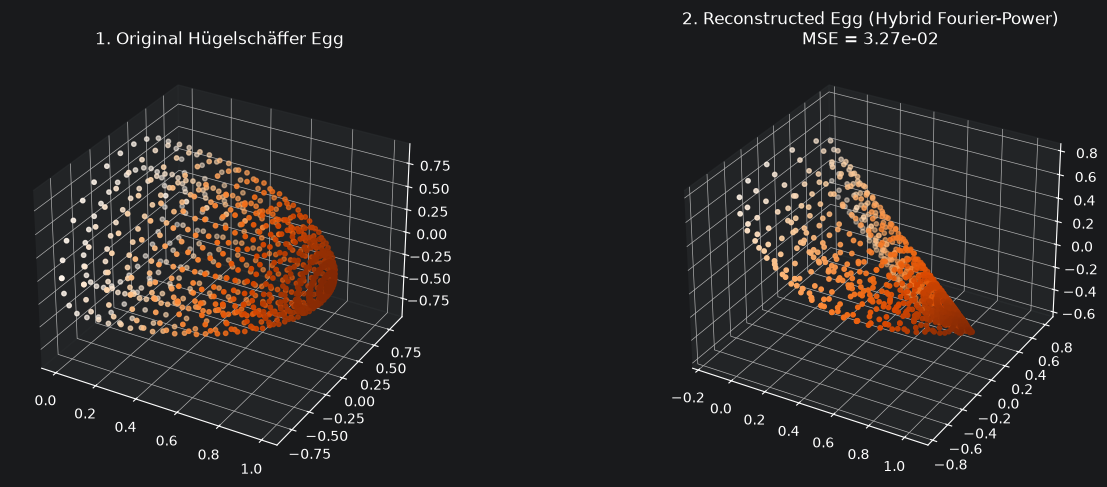

In [83]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit


class AngleExponentFourier3DTransformer:
    """3D Manifold Transformer utilizing the Fourier-Power Hybrid Model."""

    def __init__(self, theta_x_deg: float = 30.0, theta_y_deg: float = 45.0):
        self.theta_x = np.radians(theta_x_deg)
        self.theta_y = np.radians(theta_y_deg)

        # 3D Rotation Matrix
        self.Rx = np.array([
            [1, 0, 0],
            [0, np.cos(self.theta_x), -np.sin(self.theta_x)],
            [0, np.sin(self.theta_x), np.cos(self.theta_x)],
        ])
        self.Ry = np.array([
            [np.cos(self.theta_y), 0, np.sin(self.theta_y)],
            [0, 1, 0],
            [-np.sin(self.theta_y), 0, np.cos(self.theta_y)],
        ])
        self.R = self.Ry @ self.Rx
        self.R_inv = np.linalg.inv(self.R)

        # Internal State
        self.x_1d = None
        self.computed_exponent = None
        self.a_fit = None
        self.fourier_params = None
        self.shift = None
        self.driver_axis_idx = 0
        self.axis_errors = {}

    @staticmethod
    def _hybrid_model(x, a, p_plus_1, A, omega, phi):
        """Power-law trend + harmonic sine wave oscillation."""
        return (a * (x**p_plus_1)) + A * np.sin(omega * x + phi)

    def project_and_compress(self, points_3d: np.ndarray) -> np.ndarray:
        """Projects 3D points to 2D plane, tests candidate driver axes, extracts hybrid parameters,"""
        points_2d = (points_3d @ self.R.T)[:, :2]

        axis_candidates = [0, 1]
        best_mse = float("inf")
        best_fit = None
        self.axis_errors.clear()

        for cand_x_idx in axis_candidates:
            cand_y_idx = 1 - cand_x_idx

            x_cand = points_2d[:, cand_x_idx]
            y_cand = points_2d[:, cand_y_idx]

            shift_cand = np.array(
                [np.abs(x_cand.min()) + 0.1, np.abs(y_cand.min()) + 0.1]
            )
            x_shifted = x_cand + shift_cand[0]
            y_shifted = y_cand + shift_cand[1]

            # Initial 45° exponent estimation
            m_required = x_shifted / np.maximum(y_shifted, 1e-6)
            poly = np.polyfit(np.log(x_shifted), np.log(m_required), 1)
            p_fit = -poly[0]
            a_fit_init = np.exp(-poly[1])
            exp_init = p_fit + 1.0

            # Fit Fourier-Power Hybrid model
            try:
                p0 = [a_fit_init, exp_init, 0.01, 1.0, 0.0]
                popt, _ = curve_fit(
                    self._hybrid_model,
                    x_shifted,
                    y_shifted,
                    p0=p0,
                    maxfev=5000,
                )
                a_fit, exp_fit, A_fit, omega_fit, phi_fit = popt
            except RuntimeError:
                a_fit, exp_fit = a_fit_init, exp_init
                A_fit, omega_fit, phi_fit = 0.0, 0.0, 0.0

            y_hat_shifted = self._hybrid_model(
                x_shifted, a_fit, exp_fit, A_fit, omega_fit, phi_fit
            )
            y_hat = y_hat_shifted - shift_cand[1]
            fit_mse = np.mean((y_cand - y_hat) ** 2)

            self.axis_errors[cand_x_idx] = {
                "mse": fit_mse,
                "exponent": exp_fit,
                "a_fit": a_fit,
                "fourier": (A_fit, omega_fit, phi_fit),
            }

            if fit_mse < best_mse:
                best_mse = fit_mse
                best_fit = {
                    "driver_idx": cand_x_idx,
                    "x_raw": x_cand,
                    "shift": shift_cand,
                    "a_fit": a_fit,
                    "exponent": exp_fit,
                    "fourier": (A_fit, omega_fit, phi_fit),
                }

        self.driver_axis_idx = best_fit["driver_idx"]
        self.shift = best_fit["shift"]
        self.a_fit = best_fit["a_fit"]
        self.computed_exponent = best_fit["exponent"]
        self.fourier_params = best_fit["fourier"]
        self.x_1d = best_fit["x_raw"]

        return self.x_1d

    def reconstruct_3d(
        self, z_topology_priors: np.ndarray
    ) -> tuple[np.ndarray, np.ndarray]:
        """Reconstructs y' using the Fourier-Power model and un-projects back to 3D space."""
        x_shifted = self.x_1d + self.shift[0]
        A, omega, phi = self.fourier_params
        y_shifted_hat = self._hybrid_model(
            x_shifted, self.a_fit, self.computed_exponent, A, omega, phi
        )
        y_hat = y_shifted_hat - self.shift[1]

        if self.driver_axis_idx == 0:
            reconstructed_2d_plane = np.column_stack([self.x_1d, y_hat])
        else:
            reconstructed_2d_plane = np.column_stack([y_hat, self.x_1d])

        reconstructed_3d = []
        for i in range(len(self.x_1d)):
            if self.driver_axis_idx == 0:
                pt_rot = np.array(
                    [self.x_1d[i], y_hat[i], z_topology_priors[i]]
                )
            else:
                pt_rot = np.array(
                    [y_hat[i], self.x_1d[i], z_topology_priors[i]]
                )
            reconstructed_3d.append(self.R_inv @ pt_rot)

        return np.array(reconstructed_3d), reconstructed_2d_plane


def generate_hugelschaffer_egg(
    a: float = 1.0,
    b: float = 0.7,
    w: float = 0.2,
    num_u: int = 30,
    num_v: int = 30,
):
    """Generates a parametric Hügelschäffer Egg surface."""
    u = np.linspace(-np.pi / 2, np.pi / 2, num_u)
    v = np.linspace(0, 2 * np.pi, num_v)
    U, V = np.meshgrid(u, v)

    # Hügelschäffer asymmetric scaling function
    X = a * np.cos(U)
    Y = b * (1.0 - w * np.sin(U)) * np.sin(U) * np.cos(V)
    Z = b * (1.0 - w * np.sin(U)) * np.sin(U) * np.sin(V)

    return np.column_stack([X.ravel(), Y.ravel(), Z.ravel()])


# =============================================================
# BENCHMARK EXECUTION
# =============================================================
if __name__ == "__main__":
    # 1. Dataset Generation
    egg_3d = generate_hugelschaffer_egg()

    # Calculate 1D depth topology priors (Rotated Z component)
    transformer = AngleExponentFourier3DTransformer(
        theta_x_deg=30.0, theta_y_deg=45.0
    )
    rotated_egg = egg_3d @ transformer.R.T
    depth_priors = rotated_egg[:, 2]

    # 2. Compression & Reconstruction
    x_1d_stored = transformer.project_and_compress(egg_3d)
    reconstructed_3d, reconstructed_2d = transformer.reconstruct_3d(
        z_topology_priors=depth_priors
    )

    # Metrics
    raw_size_bytes = egg_3d.nbytes
    compressed_size_bytes = x_1d_stored.nbytes + (5 * 4)

    compression_ratio = raw_size_bytes / compressed_size_bytes
    space_saved_pct = (1.0 - (compressed_size_bytes / raw_size_bytes)) * 100.0
    mse_reconstruction = np.mean((egg_3d - reconstructed_3d) ** 2)

    print("=== CANDIDATE AXES HYBRID FITTING ERRORS (3D EGG) ===")
    for axis_idx, metrics in transformer.axis_errors.items():
        selected_flag = (
            " [SELECTED AS OPTIMAL DRIVER]"
            if axis_idx == transformer.driver_axis_idx
            else ""
        )
        print(
            f"Axis {axis_idx} as x' Driver -> 2D Fit MSE: {metrics['mse']:.8e}"
            f" | Exponent (p+1): {metrics['exponent']:.4f}{selected_flag}"
        )

    print("\n=== HÜGELSCHÄFFER EGG FOURIER-POWER SUMMARY ===")
    print(
        f"Original 3D Egg Shape           : {egg_3d.shape}"
        f" ({raw_size_bytes / 1024:.2f} KB)"
    )
    print(
        "Selected Optimal Driver Axis    :"
        f" Axis {transformer.driver_axis_idx}"
    )
    print(
        f"Stored 1D x' Array Shape        : {x_1d_stored.shape}"
        f" ({compressed_size_bytes / 1024:.2f} KB)"
    )
    print("y' Coordinate Storage Status    : DROPPED (Generated on the fly)")
    print(
        "Extracted Shape Exponent (p+1)  :"
        f" {transformer.computed_exponent:.4f}"
    )
    print(
        "Fourier Wave Amplitude (A)      :"
        f" {transformer.fourier_params[0]:.6f}"
    )
    print(
        "Compression Factor              :"
        f" {compression_ratio:.2f}x Reduction ({space_saved_pct:.1f}% space"
        " saved)"
    )
    print(
        "Final 3D Reconstruction MSE     :"
        f" {mse_reconstruction:.8e}"
    )

    # Plot
    fig = plt.figure(figsize=(14, 5))

    ax1 = fig.add_subplot(121, projection="3d")
    ax1.set_title("1. Original Hügelschäffer Egg")
    ax1.scatter3D(
        egg_3d[:, 0],
        egg_3d[:, 1],
        egg_3d[:, 2],
        c=egg_3d[:, 0],
        cmap="Oranges",
        s=10,
    )

    ax2 = fig.add_subplot(122, projection="3d")
    ax2.set_title(
        f"2. Reconstructed Egg (Hybrid Fourier-Power)\nMSE ="
        f" {mse_reconstruction:.2e}"
    )
    ax2.scatter3D(
        reconstructed_3d[:, 0],
        reconstructed_3d[:, 1],
        reconstructed_3d[:, 2],
        c=reconstructed_3d[:, 0],
        cmap="Oranges",
        s=10,
    )

    plt.tight_layout()
    plt.show()

## 7. Critical assessment

**Compression ratios exclude the depth coordinates.** Every printed compression factor is computed from the stored
$x'$ array plus a few scalars. Reconstruction, however, needs the $N-2$ depth coordinates $D$, which the code takes
from the original data (`rotated_full[:, 2:]`) without counting them as stored. If $D$ must be stored too, the
stored data consist of $N-1$ columns instead of $N$ and the ratio is about $N/(N-1)$:

| Data set | $N$ | Printed ratio | Ratio including $D$ |
|:--|--:|--:|--:|
| 3D meshes | 3 | $3.00\times$ | $\approx 1.50\times$ |
| 4D hypersphere | 4 | $4.00\times$ | $\approx 1.33\times$ |
| 20D manifold | 20 | $19.99\times$ | $\approx 1.05\times$ |
| 100D manifold | 100 | $99.83\times$ | $\approx 1.01\times$ |
| 600D manifold | 600 | $599.00\times$ | $\approx 1.00\times$ |

**The reconstruction MSE is diluted by a factor of $N$.** Because $R$ is orthogonal, the Frobenius norm is preserved
and the depth columns are reconstructed exactly, so all error sits in the regenerated column:

$$\mathrm{MSE}_{\text{recon}} = \frac{1}{nN}\,\|X-\hat X\|_F^2 = \frac{1}{nN}\,\|y'-\hat y'\|_2^2 = \frac{1}{N}\,\mathrm{MSE}_{\text{fit}}.$$

This holds for every run that prints both numbers, e.g. $0.3974/3 = 0.1325$ (egg), $6.917/20 = 0.3459$ (20D power law),
$3.518/20 = 0.1759$ (20D hybrid), $0.1068/100 = 1.068\times10^{-3}$ (100D) and $0.4240/600 = 7.07\times10^{-4}$ (600D).
The very small MSE of the 100D and 600D runs therefore does not mean that high-dimensional data are reconstructed more
accurately: the error of the one regenerated column is unchanged and only its weight in the average shrinks.
For unit-variance Gaussian noise the MSE of $0.00945$ is consistent with an error of order $1$ in one of 100 columns.

**Other observations.**
- The README-style markdown cell claims an improvement over linear SVD/PCA, but the notebook contains no PCA or SVD
  experiment, so the claim is untested here.
- The model treats $y'$ as a single-valued function of $x'$; it fails for multi-valued or piecewise planar shapes
  (cube, noise).
- Only two candidate drivers are compared and their fit errors are sometimes nearly equal
  ($0.3743$ vs $0.3744$ for the sphere, $0.2740$ vs $0.2825$ for the 4D hypersphere), so the choice of driver is then
  close to arbitrary.